# Marvel CPG: Exploratory Data Analysis v3 (updated client data)

**CDA 650 Experiential Learning · Client project with Globant · Team 1**
**Dataset:** Marvel CPG synthetic commercial data, **v3** (the second update Dr. Masse shared, on 16 October 2026), Jan 2025 – Jun 2026
**Versions:** v1 is the original data (`Marvel EDA.ipynb`), v2 is the first update of 10 October, and **v3 is this latest update**. Everything in this notebook is v3 evidence; v1 numbers only appear when we compare.

---

### Table of contents
1. Introduction
2. Setup and data loading
3. Data understanding and quality checks (and what changed since v1)
4. Univariate analysis
5. Bivariate and multivariate analysis
6. Time series analysis
7. The brief's KPIs (baseline values, official definitions)
8. Deep dives
9. Key insights: what changed from v1 and what it means for our build
10. Questions for Dr. Masse
11. Next steps

> **To run:** the notebook looks for the data folders. The **latest data** (16 October 2026) is expected in `data/raw/` (as in the shared V3 platform), or in `marvel_data_latest/`; the **original** v1 data in `old_marvel_data/`, `marvel_data/` or `data/original/` (the v1 comparisons need it). If it can't find them, it looks for the two zips next to the notebook (or asks for them on Colab): the latest data (the zip whose `fact_deliveries.csv` has an `order_date` column) and the original `marvel_data.zip`. The whole notebook takes a few minutes.

## 1. Introduction

### 1.1 Why we redid the EDA
The client has now sent two data updates. We ran a first EDA on the update of 10 October. On 16 October Dr. Masse sent a second update (`marvel_data 1.zip`) with this note:

| File | What the client said changed |
|---|---|
| `fact_sell_out.csv` | New columns `restock_units` and `restock_delivery_id`: every restock event is linked to a delivery in `fact_deliveries`. A real execution uplift is now built into daily sales (secondary display +8%, planogram compliance +5%, shelf share above the category median +3% per 10 percentage points). The 8% missing store-product-days and the elevated January OOS (12.8%) are intentional and unchanged |
| `fact_sell_in.csv` | The invoice date is now the Monday after the sell-out week it is based on (no look-ahead; earliest invoice 6 Jan 2025). `guardrail_violation` and `extra_discount_pct` are described as already in the file from the previous update |
| `fact_deliveries.csv` | Three fixes: "Early" now means a day early (delay −1) and "On Time" means exactly on schedule; `fill_rate_pct` matches units delivered ÷ ordered; "Short Ship" only when units delivered < ordered. Every actual delivery is on or before 30 Jun 2026 |
| `fact_execution_audits.csv` | `shelf_share_pct` is normalised per store × audit date × category (it sums to 100%); no audit rows for store-SKU pairs that are missing from sell-out |

The first update fixed several of our v1 problems but left others open: deliveries that didn't match the shelf refills, an "Early" label that really meant late, invoices that tracked the *next* week's sales, and no execution effect at all. This second update targets exactly those. So we didn't just swap the files: we re-ran the whole EDA on the latest data and checked each claim in the note against the data (3.11). The files also contain changes the note doesn't list (3.2), for example new columns in `dim_guardrails` and a rebuilt `fact_deliveries`.

(Team rule from the repo: the v1 work is frozen under the `v1-data-baseline` tag, and anything built on the new data should say it is **v3**. That's why this is a separate notebook.)

### 1.2 What we want to learn from this EDA
1. Is every item on the change list reflected in the data? Did anything change that the list doesn't mention?
2. Is the data internally consistent, including the new restock ↔ delivery link?
3. Which of our earlier findings (v1 and the first update) still hold, and which are no longer true?
4. What do the restock link, the execution uplift, the extra-discount columns and the normalised audits mean for each module (dashboard, OOS model, what-if simulator, chatbot)?
5. What are the KPI baselines now, using the official definitions from the Q&A?
6. What does the new data mean for the OOS model: how much of the next 7 days of restocks can be known in advance, and which inputs would leak the future?
7. What do we need to clarify with Dr. Masse this time?

### 1.3 The dataset (v3)
Eight tables. Unlike the first update, the latest zip contains all of them, so nothing has to be taken from the v1 files any more.

| File | Status | What one row is |
|---|---|---|
| `dim_stores` | unchanged (same as v1) | one store (channel, region, state, tier, city) |
| `dim_products` | updated in the first update | one SKU (category, brand, MSL flag, cost, list price, consumer price) |
| `dim_guardrails` | **updated**: new `standard_discount_pct`, other values changed | discount and margin rules for one channel × category |
| `dim_promotions` | new in the first update | one promotion: type, channel, category, dates, discount, minimum volume |
| `fact_sell_out` | **updated** | one store-SKU-day: units, end-of-day stock, OOS flag, price paid, promo, **restock units and the delivery behind them** |
| `fact_sell_in` | **updated** | one invoice line (store-SKU-week): units, gross sales, **standard + extra discount**, net sales, promo, **guardrail flag** |
| `fact_deliveries` | **rebuilt**: one row per restock order (order date, scheduled and actual delivery, units ordered vs delivered); no longer linked to invoices | one delivery |
| `fact_execution_audits` | **updated**: shelf share normalised | one SKU checked during a store audit: planogram, shelf share, secondary display |

### 1.4 What the client has answered since v1
After v1 we sent 19 questions; the answers (Marvel CPG Q&A) are binding, so this notebook follows them:

| Q | Answer we apply here |
|---|---|
| Q3 | `inventory_level` is end-of-day stock; OOS = ended the day at 0 |
| Q5, Q16 | `list_price` is the trade price; margin = (net price − cost) ÷ net price, with net price = list × (1 − discount) |
| Q10, Q15 | Exact KPI definitions (used in section 7); MSL and planogram compliance are different things |
| Q11 | Missing store-days are **not reported**, not zero sales |
| Q12 | OOS target = out of stock on **any** of the next 7 days; 0.75 / 0.70 / 0.80 are fixed minimums |
| Q13 | Compare sell-in and sell-out over the **same time window** (Traditional Trade is invoiced every two weeks) |
| Q14 | Elasticity and execution uplift must be **estimated from the data**, not assumed |
| Q17 | Distributors are wholesale accounts; show them separately from retail KPIs |
| Q18 | 30 June 2026 is "today"; train up to ~May 2026, test on June 2026 |

### 1.5 What this notebook covers
This notebook is EDA only. The missing-data experiments and the OOS model live in their own notebooks. Because June 2026 is the OOS model's test month, the checks on structure, keys and formulas (3.1–3.6) use the full data, but every analysis after that uses **1 Jan 2025 – 31 May 2026** (see the end of 3.6).

## 2. Setup and data loading

In [1]:
import os, gc, zipfile, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
from types import SimpleNamespace

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold', 'axes.titlesize': 12})
pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)

# fixed orders and colours so every chart in the notebook is consistent.
# Same as v1, except Distributor, Tier 2 and two category colours: we ran a colour-blind check
# and the v1 versions were hard to tell apart (e.g. the green and orange for protanopia)
CH_ORDER = ['Modern Trade', 'Traditional Trade', 'Distributor']
TIER_ORDER = ['Tier 1', 'Tier 2', 'Tier 3']
CAT_ORDER = ['Surface Cleaners', 'Dishwashing', 'Laundry']
REGION_ORDER = ['Northeast', 'Midwest', 'Southeast', 'West']
CH_COL = dict(zip(CH_ORDER, ['#4C72B0', '#DD8452', '#8C5A9E']))
TIER_COL = dict(zip(TIER_ORDER, ['#2A9D8F', '#D4A72C', '#C4473A']))
CAT_COL = dict(zip(CAT_ORDER, ['#7A5FC0', '#2E9BC0', '#C44E52']))
REG_COL = dict(zip(REGION_ORDER, ['#4C72B0', '#937860', '#DA8BC3', '#8C8C8C']))
DAYS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
TODAY = pd.Timestamp('2026-06-30')     # Q18: "today" in the simulation

def heatmap(*args, **kwargs):          # seaborn heatmap without the background grid lines
    ax = sns.heatmap(*args, **kwargs); ax.grid(False); return ax

def label_bars(ax, fmt='{:.1f}', size=9):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(v) for v in c.datavalues], fontsize=size, padding=2)

def weekly_decompose(s):               # additive decomposition with a 7-day period (the same method as statsmodels' seasonal_decompose)
    trend = s.rolling(7, center=True).mean()
    avg = (s - trend).groupby(s.index.dayofweek).mean()
    avg = avg - avg.mean()
    seasonal = pd.Series(s.index.dayofweek.map(avg).to_numpy(), index=s.index)
    return SimpleNamespace(observed=s, trend=trend, seasonal=seasonal, resid=s - trend - seasonal)

FIG_DIR = 'Marvel EDA v3 Figures'       # every chart is also saved here (for slides and the repo)
os.makedirs(FIG_DIR, exist_ok=True)
def show(name, tight=True):
    if tight:
        plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=130, bbox_inches='tight'); plt.show()

print('pandas', pd.__version__)

pandas 2.2.3


The cell below looks for the data folders (see the note at the top). If it can't find them, it looks for the two zips and unzips them. It also checks that it has the **latest** data (the 16 October update): the older first update would load without errors but give different results.
*(Google Drive instead? Mount Drive with `from google.colab import drive; drive.mount('/content/drive')`, then copy both zips into the working folder before this cell.)*

In [2]:
import glob

def unzip_flat(zip_path, target):      # the zips hold one top-level folder; put the CSVs straight into `target`
    os.makedirs(target, exist_ok=True)
    with zipfile.ZipFile(zip_path) as z:
        for n in z.namelist():
            if n.endswith('.csv'):
                with open(os.path.join(target, os.path.basename(n)), 'wb') as f:
                    f.write(z.read(n))

def find_dir(*names):                  # look in this folder and up to two levels above
    for base in ['.', '..', os.path.join('..', '..')]:
        for n in names:
            if os.path.isdir(os.path.join(base, n)):
                return os.path.join(base, n)

NEW_DIR = find_dir('data/raw', 'marvel_data_latest', 'new_marvel_data')   # latest data: shared V3 folder, or the unzipped 16 Oct update
OLD_DIR = find_dir('old_marvel_data', 'marvel_data', 'data/original')     # original (v1) data
if NEW_DIR is None or OLD_DIR is None:                                    # look for the zips, or ask for them on Colab
    zips = [z for base in ['.', '..', os.path.join('..', '..')] for z in glob.glob(os.path.join(base, '*.zip'))]
    if not zips:
        try:
            from google.colab import files   # opens a file picker -> choose BOTH zips
            print('Please choose two zips: the latest data (16 Oct 2026) and the original marvel_data.zip'); files.upload()
            zips = glob.glob('*.zip')
        except ImportError:
            raise FileNotFoundError('Latest data not found in data/raw/ (or original data in old_marvel_data/ or marvel_data/). '
                                    'Place the CSV files there, or put the two zips next to this notebook.')
    for zp in zips:
        with zipfile.ZipFile(zp) as z:
            names = z.namelist()
            so_csv = [n for n in names if n.endswith('fact_sell_out.csv')]
            cols = list(pd.read_csv(z.open(so_csv[0]), nrows=1).columns) if so_csv else []
        has_deliveries = any(n.endswith('fact_deliveries.csv') for n in names)
        if 'restock_units' in cols and NEW_DIR is None:
            unzip_flat(zp, 'marvel_data_latest')           # the latest data (16 Oct 2026)
        elif so_csv and not has_deliveries and OLD_DIR is None:
            unzip_flat(zp, 'marvel_data')                  # the original data (no fact_deliveries yet)
        # anything else (e.g. the first update of 10 Oct) is ignored
    NEW_DIR = NEW_DIR or ('marvel_data_latest' if os.path.isdir('marvel_data_latest') else None)
    OLD_DIR = OLD_DIR or ('marvel_data' if os.path.isdir('marvel_data') else None)
    if NEW_DIR is None or OLD_DIR is None:
        raise FileNotFoundError('Could not find both the latest and the original data (see the note at the top of the notebook).')

def old_path(name):                    # original data (the repo copies are prefixed "old_")
    p = os.path.join(OLD_DIR, f'{name}.csv')
    return p if os.path.exists(p) else os.path.join(OLD_DIR, f'old_{name}.csv')
print('latest data:', NEW_DIR, sorted(os.listdir(NEW_DIR)))
print('original data:', OLD_DIR)

# v3: the latest data (all eight tables)
sell_out   = pd.read_csv(f'{NEW_DIR}/fact_sell_out.csv', parse_dates=['date'], dtype={'promo_id': str, 'restock_delivery_id': str})
assert 'restock_units' in sell_out.columns, 'This notebook needs the latest data (16 Oct 2026): fact_sell_out must have restock_units'
products   = pd.read_csv(f'{NEW_DIR}/dim_products.csv')
promos     = pd.read_csv(f'{NEW_DIR}/dim_promotions.csv', parse_dates=['start_date', 'end_date'])
sell_in    = pd.read_csv(f'{NEW_DIR}/fact_sell_in.csv', parse_dates=['date'], dtype={'promo_id': str})
deliveries = pd.read_csv(f'{NEW_DIR}/fact_deliveries.csv', parse_dates=['order_date', 'scheduled_delivery', 'actual_delivery'])
stores     = pd.read_csv(f'{NEW_DIR}/dim_stores.csv')
guardrails = pd.read_csv(f'{NEW_DIR}/dim_guardrails.csv')
audits     = pd.read_csv(f'{NEW_DIR}/fact_execution_audits.csv', parse_dates=['date'])
# the original (v1) versions of the tables that changed, only used to compare old vs new
v1 = {'dim_products': pd.read_csv(old_path('dim_products')),
      'dim_guardrails': pd.read_csv(old_path('dim_guardrails')),
      'fact_sell_out': pd.read_csv(old_path('fact_sell_out'), parse_dates=['date']),
      'fact_sell_in': pd.read_csv(old_path('fact_sell_in'), parse_dates=['date']),
      'fact_execution_audits': pd.read_csv(old_path('fact_execution_audits'), parse_dates=['date'])}

ch_of = stores.set_index('store_id').channel        # quick lookups we use a lot
cat_of = products.set_index('sku_id').category

# Two versions of dim_guardrails exist: the 16 Oct update (has standard_discount_pct; max_discount_pct caps the EXTRA discount)
# and the earlier file (no standard_discount_pct). Sections 8.4 and 8.8 were written for the 16 Oct version.
GUARDRAILS_16_OCT = 'standard_discount_pct' in guardrails.columns
if not GUARDRAILS_16_OCT:
    std = (sell_in.assign(channel=sell_in.store_id.map(ch_of), category=sell_in.sku_id.map(cat_of),
                          standard_part=lambda d: (d.discount_pct - d.extra_discount_pct).round(2))
                  .groupby(['channel', 'category'])['standard_part'].median().rename('standard_discount_pct').reset_index())
    guardrails = guardrails.merge(std, on=['channel', 'category'])      # standard discount read off the invoices (a constant per channel × category)
print('dim_guardrails in use:', '16 Oct update (cap on the extra discount)' if GUARDRAILS_16_OCT else
      'EARLIER version: standard discount derived from the invoices; the caps in 8.4 and 8.8 then mean something else, read those two sections with care')

tables = {'dim_stores': stores, 'dim_products': products, 'dim_guardrails': guardrails, 'dim_promotions': promos,
          'fact_sell_out': sell_out, 'fact_sell_in': sell_in, 'fact_deliveries': deliveries, 'fact_execution_audits': audits}

latest data: ./marvel_data_latest ['dim_guardrails.csv', 'dim_products.csv', 'dim_promotions.csv', 'dim_stores.csv', 'fact_deliveries.csv', 'fact_execution_audits.csv', 'fact_sell_in.csv', 'fact_sell_out.csv']
original data: ./marvel_data


dim_guardrails in use: 16 Oct update (cap on the extra discount)


## 3. Data understanding and quality checks
Same checklist as v1 (size and types, missing values, duplicates, keys, value ranges, date coverage, internal consistency), plus two new questions: **what exactly changed since v1** (3.2) and **does each item of the client's change list hold** (3.11).

### 3.1 Size, columns and types

In [3]:
STATUS = {'dim_stores': 'unchanged', 'dim_products': 'updated', 'dim_guardrails': 'UPDATED', 'dim_promotions': 'new',
          'fact_sell_out': 'UPDATED', 'fact_sell_in': 'UPDATED', 'fact_deliveries': 'REBUILT', 'fact_execution_audits': 'UPDATED'}
SPAN = {'fact_sell_out': ('date', 'date'), 'fact_sell_in': ('date', 'date'), 'fact_execution_audits': ('date', 'date'),
        'fact_deliveries': ('order_date', 'actual_delivery'), 'dim_promotions': ('start_date', 'end_date')}
overview = pd.DataFrame([{
    'table': n, 'status_vs_v1': STATUS[n], 'rows': len(d), 'columns': d.shape[1],
    'memory_MB': round(d.memory_usage(deep=True).sum() / 1e6, 1),
    'first_date': d[SPAN[n][0]].min().date() if n in SPAN else '-',
    'last_date': d[SPAN[n][1]].max().date() if n in SPAN else '-'} for n, d in tables.items()])
display(overview)

for n in ['dim_guardrails', 'dim_promotions', 'fact_sell_out', 'fact_sell_in', 'fact_deliveries', 'fact_execution_audits']:
    print(f'--- {n} ---')
    display(tables[n].head(3))

,table,status_vs_v1,rows,columns,memory_MB,first_date,last_date
0,dim_stores,unchanged,221,7,0.1,-,-
1,dim_products,updated,23,8,0.0,-,-
2,dim_guardrails,UPDATED,9,6,0.0,-,-
3,dim_promotions,new,37,9,0.0,2025-01-05,2026-06-15
4,fact_sell_out,UPDATED,2193868,11,510.8,2025-01-01,2026-06-30
5,fact_sell_in,UPDATED,277059,11,71.5,2025-01-06,2026-06-29
6,fact_deliveries,REBUILT,142641,11,40.5,2025-01-01,2026-06-30
7,fact_execution_audits,UPDATED,208459,7,39.7,2025-01-01,2026-06-30


--- dim_guardrails ---


,channel,category,standard_discount_pct,max_discount_pct,min_target_margin,required_exec_tradeoff
0,Modern Trade,Surface Cleaners,9.64,5.03,22.01,Achieve 100% MSL compliance + planogram adherence
1,Modern Trade,Dishwashing,8.71,5.85,22.15,Achieve 100% MSL compliance + planogram adherence
2,Modern Trade,Laundry,8.28,4.05,25.70,Secure +10% shelf share or place 1 secondary d...


--- dim_promotions ---


,promo_id,promo_name,promo_type,category,channel,start_date,end_date,discount_pct,min_volume_units
0,PRO-001,Spring Clean Blitz,TPR,Surface Cleaners,Modern Trade,2025-03-03,2025-03-23,12.0,50
1,PRO-002,Spring Clean Blitz,TPR,Surface Cleaners,Traditional Trade,2025-03-03,2025-03-23,12.0,50
2,PRO-003,Spring Clean Blitz,TPR,Dishwashing,Modern Trade,2025-03-03,2025-03-23,10.0,30


...

,transaction_id,date,store_id,sku_id,units_sold,gross_sales,discount_pct,extra_discount_pct,net_sales,promo_id,guardrail_violation
0,TXN-00001,2025-01-06,STR-0001,SKU-1001,16,72.0,10.78,1.14,64.24,NaN,False
1,TXN-00002,2025-01-06,STR-0001,SKU-1002,8,35.2,11.44,1.80,31.17,NaN,False
2,TXN-00003,2025-01-06,STR-0001,SKU-1004,4,23.2,11.91,2.27,20.44,NaN,False


--- fact_deliveries ---


,delivery_id,store_id,sku_id,order_date,scheduled_delivery,actual_delivery,delay_days,delivery_status,units_ordered,units_delivered,fill_rate_pct
0,DLV-00001,STR-0001,SKU-1001,2025-01-06,2025-01-08,2025-01-08,0,On Time,58,58,100.0
1,DLV-00002,STR-0001,SKU-1001,2025-02-02,2025-02-05,2025-02-05,0,On Time,51,51,100.0
2,DLV-00003,STR-0001,SKU-1001,2025-03-01,2025-03-04,2025-03-03,-1,Early,65,65,100.0


--- fact_execution_audits ---


,audit_id,date,store_id,sku_id,planogram_compliance,shelf_share_pct,secondary_display
0,AUD-00001,2025-01-28,STR-0001,SKU-1001,True,17.68,True
1,AUD-00002,2025-01-28,STR-0001,SKU-1002,True,25.63,False
2,AUD-00003,2025-01-28,STR-0001,SKU-1004,True,5.16,False


### 3.2 What changed since v1?
First the obvious part: rows and columns, for every table that differs from v1. Then something the change list doesn't say: are the store-SKU-days that exist in both versions the *same* data with extra columns, or was everything regenerated?

In [4]:
rows = []
for n in ['dim_products', 'dim_guardrails', 'fact_sell_out', 'fact_sell_in', 'fact_execution_audits']:
    old, new = v1[n], tables[n]
    rows.append({'table': n, 'rows_v1': len(old), 'rows_v3': len(new), 'row_change_%': round((len(new) / len(old) - 1) * 100, 1),
                 'columns_added': ', '.join(c for c in new.columns if c not in old.columns) or '-',
                 'columns_removed': ', '.join(c for c in old.columns if c not in new.columns) or '-'})
display(pd.DataFrame(rows))
print('fact_deliveries is new since v1; dim_stores is identical to v1:',
      bool(stores.equals(pd.read_csv(old_path('dim_stores')))))

pp = products.merge(v1['dim_products'], on='sku_id', suffixes=('', '_v1'))
print('Unit cost and list price unchanged for every SKU:',
      bool((pp.unit_cost == pp.unit_cost_v1).all() and (pp.list_price == pp.list_price_v1).all()))

k3 = ['date', 'store_id', 'sku_id']
both = sell_out[k3 + ['units_sold_daily', 'inventory_level']].merge(
    v1['fact_sell_out'][k3 + ['units_sold_daily', 'inventory_level']], on=k3, suffixes=('_v3', '_v1'))
print(f'Store-SKU-days present in both versions: {len(both):,}')
print(f"  same units sold: {(both.units_sold_daily_v3 == both.units_sold_daily_v1).mean():.1%}"
      f" | same stock level: {(both.inventory_level_v3 == both.inventory_level_v1).mean():.1%}")

pairs_so = set(zip(sell_out.store_id, sell_out.sku_id))
a1 = v1['fact_execution_audits']
orphan = lambda a: sum((s, p) not in pairs_so for s, p in zip(a.store_id, a.sku_id))
print(f'Audit rows for store-SKU pairs that never appear in sell-out: v1 {orphan(a1):,} ({orphan(a1) / len(a1):.1%}) -> v3 {orphan(audits):,}')
display(guardrails.merge(v1['dim_guardrails'][['channel', 'category', 'max_discount_pct', 'min_target_margin']],
                         on=['channel', 'category'], suffixes=('', '_v1'))
        [['channel', 'category', 'standard_discount_pct', 'max_discount_pct_v1', 'max_discount_pct', 'min_target_margin_v1', 'min_target_margin']])
del both, pp

,table,rows_v1,rows_v3,row_change_%,columns_added,columns_removed
0,dim_products,23,23,0.0,consumer_price,-
1,dim_guardrails,9,9,0.0,standard_discount_pct,-
2,fact_sell_out,1656756,2193868,32.4,"consumer_price_actual, promo_id, promo_discoun...",-
3,fact_sell_in,277969,277059,-0.3,"gross_sales, discount_pct, extra_discount_pct,...",-
4,fact_execution_audits,207020,208459,0.7,-,-


fact_deliveries is new since v1; dim_stores is identical to v1: True
Unit cost and list price unchanged for every SKU: True


Store-SKU-days present in both versions: 1,398,460
  same units sold: 14.0% | same stock level: 1.2%


Audit rows for store-SKU pairs that never appear in sell-out: v1 14,727 (7.1%) -> v3 0


,channel,category,standard_discount_pct,max_discount_pct_v1,max_discount_pct,min_target_margin_v1,min_target_margin
0,Modern Trade,Surface Cleaners,9.64,12.80,5.03,26.62,22.01
1,Modern Trade,Dishwashing,8.71,11.34,5.85,22.26,22.15
2,Modern Trade,Laundry,8.28,13.30,4.05,25.50,25.70
3,Traditional Trade,Surface Cleaners,2.30,6.62,3.15,31.47,28.61
4,Traditional Trade,Dishwashing,2.84,7.99,4.36,27.52,27.60
5,Traditional Trade,Laundry,3.24,7.16,5.23,27.08,26.61
6,Distributor,Surface Cleaners,11.44,17.80,5.65,23.45,22.06
7,Distributor,Dishwashing,10.81,15.07,5.51,21.97,22.63
8,Distributor,Laundry,11.31,16.34,6.99,17.41,19.06


**Notes**
1. Same 23 SKUs with the same cost and list price. `dim_products` only gained `consumer_price` (in the first update). **`dim_guardrails` changed completely** and the change list doesn't say so: it has a new column `standard_discount_pct`, and `max_discount_pct` and `min_target_margin` have new values (for example Modern Trade Surface Cleaners 12.8 → 5.03). We come back to what that means in 8.4 and 8.8, and to which version is final in section 10.
2. Sell-out has **32.4% more rows** than v1 (1.66M → 2.19M). There aren't more stores or SKUs; there are fewer missing days (3.7). Sell-in has about the same number of lines (−0.3%) and the audits +0.7%.
3. `fact_deliveries` was **rebuilt**. In the first update it had 281,004 rows, one per invoice line, with `transaction_id` and `invoice_date`. Now it has about half as many rows (142,641), one per *restock order*, with an `order_date` and no link to invoices.
4. The bigger surprise, again: of the 1.4M store-SKU-days that exist in both versions, only **14.0%** have the same units sold and **1.2%** the same stock level. So the whole simulation was **regenerated once more**. That's why we redo every check instead of only looking at the new columns, and why no v1 number can be reused without checking it again.
5. The audits lost every row for a store-SKU pair that doesn't exist in sell-out: **7.1% of v1 audit rows (14,727) → 0**.
6. How sales and stock-outs changed is analysed from 3.7 on, without June 2026 (see the end of 3.6). The short version: stock levels are about twice as high, and stock-outs are concentrated in small stores in a different way than before.

### 3.3 Missing values and duplicates

In [5]:
keys = {'dim_stores': ['store_id'], 'dim_products': ['sku_id'], 'dim_guardrails': ['channel', 'category'], 'dim_promotions': ['promo_id'],
        'fact_sell_out': ['date', 'store_id', 'sku_id'], 'fact_sell_in': ['transaction_id'], 'fact_deliveries': ['delivery_id'],
        'fact_execution_audits': ['audit_id']}
display(pd.DataFrame([{'table': n, 'null_cells': int(d.isna().sum().sum()),
                       'columns_with_nulls': ', '.join(d.columns[d.isna().any()]) or '-',
                       'duplicate_rows': int(d.duplicated().sum()), 'primary_key': ' + '.join(keys[n]),
                       'duplicate_keys': int(d.duplicated(keys[n]).sum())} for n, d in tables.items()]))
print(f"Rows with a promo_id: sell-out {sell_out.promo_id.notna().mean():.1%} | sell-in {sell_in.promo_id.notna().mean():.1%}")
print('Sell-out promo_discount_pct is 0 exactly when promo_id is empty:',
      bool(((sell_out.promo_discount_pct == 0) == sell_out.promo_id.isna()).all()))
print('Sell-out restock_delivery_id is empty exactly when restock_units is 0:',
      bool((sell_out.restock_delivery_id.isna() == (sell_out.restock_units == 0)).all()))
print(f"Sell-out rows with a restock: {(sell_out.restock_units > 0).mean():.1%} | invoice lines flagged guardrail_violation: {sell_in.guardrail_violation.mean():.1%}")

,table,null_cells,columns_with_nulls,duplicate_rows,primary_key,duplicate_keys
0,dim_stores,0,-,0,store_id,0
1,dim_products,0,-,0,sku_id,0
2,dim_guardrails,0,-,0,channel + category,0
3,dim_promotions,0,-,0,promo_id,0
4,fact_sell_out,3868308,"promo_id, restock_delivery_id",0,date + store_id + sku_id,0
5,fact_sell_in,225929,promo_id,0,transaction_id,0
6,fact_deliveries,0,-,0,delivery_id,0
7,fact_execution_audits,0,-,0,audit_id,0


Rows with a promo_id: sell-out 17.7% | sell-in 18.5%
Sell-out promo_discount_pct is 0 exactly when promo_id is empty: True
Sell-out restock_delivery_id is empty exactly when restock_units is 0: True
Sell-out rows with a restock: 6.0% | invoice lines flagged guardrail_violation: 3.0%


The only nulls are in `promo_id` (17.7% of sell-out rows and 18.5% of invoice lines have a promotion) and in `restock_delivery_id`, which is empty exactly when `restock_units` is 0 (6.0% of sell-out rows have a restock). `promo_discount_pct` is 0 on exactly the rows without a promo. `guardrail_violation` is true on 3.0% of invoice lines. Keys are unique everywhere, including `fact_deliveries`.

### 3.4 Referential integrity
Same checks as v1, plus the new links: promotions, the restock ↔ delivery link, and the audits. We also checked that a promo row really matches its promotion (right channel, right category, inside the promo dates).

In [6]:
ri = []
for n in ['fact_sell_out', 'fact_sell_in', 'fact_deliveries', 'fact_execution_audits']:
    d = tables[n]
    ri.append({'check': f'{n}.store_id exists in dim_stores', 'passed': bool(d.store_id.isin(stores.store_id).all())})
    ri.append({'check': f'{n}.sku_id exists in dim_products', 'passed': bool(d.sku_id.isin(products.sku_id).all())})
combos = {(c, k) for c in stores.channel.unique() for k in products.category.unique()}
ri.append({'check': 'dim_guardrails covers every channel x category', 'passed': combos == set(zip(guardrails.channel, guardrails.category))})
ri.append({'check': 'every store appears in all four fact tables',
           'passed': all(set(stores.store_id) == set(tables[n].store_id) for n in ['fact_sell_out', 'fact_sell_in', 'fact_deliveries', 'fact_execution_audits'])})

# the new link: every restock in sell-out points to a delivery
rs = (sell_out[sell_out.restock_units > 0]
      .merge(deliveries, left_on='restock_delivery_id', right_on='delivery_id', how='left', suffixes=('', '_d')))
ri.append({'check': 'every restock row points to a delivery that exists in fact_deliveries', 'passed': bool(rs.delivery_id.notna().all())})
ri.append({'check': 'restock row and delivery have the same store, SKU and units',
           'passed': bool(((rs.store_id == rs.store_id_d) & (rs.sku_id == rs.sku_id_d) & (rs.restock_units == rs.units_delivered)).all())})
ri.append({'check': 'restock date = actual_delivery date of that delivery', 'passed': bool((rs.date == rs.actual_delivery).all())})
ri.append({'check': 'no delivery is linked to more than one restock row', 'passed': bool(rs.restock_delivery_id.is_unique)})
pairs_so = set(zip(sell_out.store_id, sell_out.sku_id))
ri.append({'check': 'every audited store-SKU pair also appears in sell-out',
           'passed': all((s, p) in pairs_so for s, p in zip(audits.store_id, audits.sku_id))})

pm = promos.set_index('promo_id')
for n, d in [('fact_sell_out', sell_out), ('fact_sell_in', sell_in)]:
    ri.append({'check': f'{n}.promo_id exists in dim_promotions', 'passed': bool(d.promo_id.dropna().isin(promos.promo_id).all())})
    p = d[d.promo_id.notna()]
    pr_ = pm.loc[p.promo_id]
    ri.append({'check': f'{n}: promo rows have the promo channel and category',
               'passed': bool(((p.store_id.map(ch_of).values == pr_.channel.values) & (p.sku_id.map(cat_of).values == pr_.category.values)).all())})
    ri.append({'check': f'{n}: promo rows fall inside the promo dates',
               'passed': bool(((p.date.values >= pr_.start_date.values) & (p.date.values <= pr_.end_date.values)).all())})
p = sell_out[sell_out.promo_id.notna()]
ri.append({'check': 'fact_sell_out: promo_discount_pct = the promo discount',
           'passed': bool(np.isclose(p.promo_discount_pct.values, pm.loc[p.promo_id].discount_pct.values).all())})

# is every store-SKU-day inside a promo window tagged, or only some stores?
part = []
for _, r in promos.iterrows():
    m = (sell_out.store_id.map(ch_of) == r.channel) & (sell_out.sku_id.map(cat_of) == r.category) & sell_out.date.between(r.start_date, r.end_date)
    part.append((sell_out.promo_id[m] == r.promo_id).mean())
ri.append({'check': 'every eligible store-SKU-day inside a promo window carries that promo', 'passed': bool(np.allclose(part, 1))})
del rs, p, pr_
pd.DataFrame(ri)

,check,passed
0,fact_sell_out.store_id exists in dim_stores,True
1,fact_sell_out.sku_id exists in dim_products,True
2,fact_sell_in.store_id exists in dim_stores,True
3,fact_sell_in.sku_id exists in dim_products,True
4,fact_deliveries.store_id exists in dim_stores,True
5,fact_deliveries.sku_id exists in dim_products,True
6,fact_execution_audits.store_id exists in dim_s...,True
7,fact_execution_audits.sku_id exists in dim_pro...,True
8,dim_guardrails covers every channel x category,True
9,every store appears in all four fact tables,True


Everything links up. Two things are worth remembering for later:
1. **The restock link is exact.** Every restock row in sell-out points to a delivery that exists in `fact_deliveries`, with the same store, the same SKU, the same units, and the restock date equal to the delivery's actual date. It is one-to-one (no delivery is used twice). This is the fix we were waiting for since v1: the stock and the deliveries finally tell the same story (3.9).
2. **Promotions are blanket:** if a promo runs for a channel × category, *every* store-SKU-day in that window carries it, in both sell-out and sell-in. No store opts out. So promo days can be read straight off `dim_promotions`, and since promotions are planned in advance, the calendar is a fair forward-looking input for the OOS model.

### 3.5 Value range and arithmetic checks
v1 only had to check ranges. v3 has columns that are *calculated* from other columns (gross and net sales, standard + extra discount, fill rate, delay, shelf share per visit), so we also checked that the arithmetic adds up. We show the share of rows that pass instead of just True/False, because some checks pass for almost every row but not all.

In [7]:
si_chk = (sell_in.assign(channel=sell_in.store_id.map(ch_of), category=sell_in.sku_id.map(cat_of))
                 .merge(products[['sku_id', 'list_price', 'unit_cost']], on='sku_id').merge(guardrails, on=['channel', 'category']))
so_chk = sell_out[['sku_id', 'consumer_price_actual', 'promo_id', 'promo_discount_pct']].merge(products[['sku_id', 'consumer_price']], on='sku_id')
price_ratio = so_chk.consumer_price_actual / so_chk.consumer_price
on_promo = so_chk.promo_id.notna()
fill_calc = deliveries.units_delivered / deliveries.units_ordered * 100
days_vs_schedule = (deliveries.actual_delivery - deliveries.scheduled_delivery).dt.days
status = deliveries.delivery_status
margin_si = (si_chk.net_sales - si_chk.units_sold * si_chk.unit_cost) / si_chk.net_sales * 100
au_chk = audits.assign(category=audits.sku_id.map(cat_of))
visit_sum = au_chk.groupby(['store_id', 'date', 'category']).shelf_share_pct.sum()

checks = pd.DataFrame([
    ('sell-out: units_sold_daily >= 0', (sell_out.units_sold_daily >= 0).mean()),
    ('sell-out: inventory_level >= 0', (sell_out.inventory_level >= 0).mean()),
    ('sell-out: is_out_of_stock == (inventory_level == 0)', (sell_out.is_out_of_stock == (sell_out.inventory_level == 0)).mean()),
    ('sell-out: price paid within ±3.1% of consumer_price (no promo)', price_ratio[~on_promo].between(0.969, 1.031).mean()),
    ('sell-out: price paid = consumer_price × (1 − promo discount) (promo)',
     np.isclose(so_chk.consumer_price_actual, so_chk.consumer_price * (1 - so_chk.promo_discount_pct / 100), rtol=0.002)[on_promo].mean()),
    ('sell-in: units_sold > 0', (sell_in.units_sold > 0).mean()),
    ('sell-in: gross_sales = units × list_price', np.isclose(si_chk.gross_sales, si_chk.units_sold * si_chk.list_price, atol=0.011).mean()),
    ('sell-in: net_sales = gross_sales × (1 − discount_pct)', np.isclose(si_chk.net_sales, si_chk.gross_sales * (1 - si_chk.discount_pct / 100), atol=0.011).mean()),
    ('sell-in: discount_pct = standard_discount_pct + extra_discount_pct', np.isclose(si_chk.discount_pct, si_chk.standard_discount_pct + si_chk.extra_discount_pct, atol=0.011).mean()),
    ('sell-in: margin on every invoice >= min_target_margin', (margin_si >= si_chk.min_target_margin).mean()),
    ('products: consumer_price > list_price > unit_cost', ((products.consumer_price > products.list_price) & (products.list_price > products.unit_cost)).mean()),
    ('deliveries: units_delivered <= units_ordered', (deliveries.units_delivered <= deliveries.units_ordered).mean()),
    ('deliveries: fill_rate_pct = delivered ÷ ordered (to 2 decimals)', np.isclose(deliveries.fill_rate_pct, fill_calc, atol=0.0051).mean()),
    ('deliveries: delay_days = actual − scheduled', (deliveries.delay_days == days_vs_schedule).mean()),
    ('deliveries: status matches the dates (Early < 0, On Time = 0, Late > 0)',
     ((status.str.startswith('Early') == (days_vs_schedule < 0)) & (status.str.startswith('On Time') == (days_vs_schedule == 0))
      & (status.str.startswith('Late') == (days_vs_schedule > 0))).mean()),
    ('deliveries: "Short Ship" label only when units delivered < ordered', (status.str.contains('Short') == (deliveries.units_delivered < deliveries.units_ordered)).mean()),
    ('deliveries: scheduled delivery after the order date', (deliveries.scheduled_delivery > deliveries.order_date).mean()),
    ('deliveries: actual delivery on or before 30 Jun 2026', (deliveries.actual_delivery <= TODAY).mean()),
    ('audits: 0 <= shelf_share_pct <= 100', audits.shelf_share_pct.between(0, 100).mean()),
    ('audits: shelf shares sum to 100% in each store × date × category visit (±0.05)', np.isclose(visit_sum, 100, atol=0.05).mean()),
], columns=['check', 'share_of_rows_passing'])
checks['passed'] = checks.share_of_rows_passing == 1
display(checks.round(4))
print(f"Largest gap between fill_rate_pct and delivered ÷ ordered: {(deliveries.fill_rate_pct - fill_calc).abs().max():.4f} percentage points "
      f"| shelf-share sum per visit: min {visit_sum.min():.2f}, max {visit_sum.max():.2f}")
del au_chk

,check,share_of_rows_passing,passed
0,sell-out: units_sold_daily >= 0,1.0,True
1,sell-out: inventory_level >= 0,1.0,True
2,sell-out: is_out_of_stock == (inventory_level ...,1.0,True
3,sell-out: price paid within ±3.1% of consumer_...,1.0,True
4,sell-out: price paid = consumer_price × (1 − p...,1.0,True
5,sell-in: units_sold > 0,1.0,True
6,sell-in: gross_sales = units × list_price,1.0,True
7,sell-in: net_sales = gross_sales × (1 − discou...,1.0,True
8,sell-in: discount_pct = standard_discount_pct ...,1.0,True
9,sell-in: margin on every invoice >= min_target...,1.0,True


Largest gap between fill_rate_pct and delivered ÷ ordered: 0.0050 percentage points | shelf-share sum per visit: min 99.98, max 100.03


**Every check passes**, including all the ones that failed in the first update. The new money columns add up exactly (gross = units × list price, net = gross × (1 − discount), and **discount = standard + extra** on every line), and every invoice keeps a margin above the minimum. On the fixes in the change list:
1. `fill_rate_pct` now equals units delivered ÷ ordered to two decimals (largest gap 0.005 percentage points, which is just rounding). In the first update 4.9% of rows were off.
2. The "Short Ship" label appears only when fewer units arrived than were ordered.
3. The shelf shares of the SKUs in a category visit sum to 100% (99.98–100.03).
4. No actual delivery is dated after 30 June 2026.

`delivery_status` is a label, so we can't check it with arithmetic. But it should agree with the dates. Here is every status against *actual minus scheduled delivery* (negative = early, positive = late):

In [8]:
pd.crosstab(deliveries.delivery_status, days_vs_schedule.rename('actual − scheduled (days)'))

actual − scheduled (days),-1,0,1,2,3,4,5,6,7
delivery_status,,,,,,,,,
Early,45978,0,0,0,0,0,0,0,0
Early / Short Ship,2499,0,0,0,0,0,0,0,0
Late,0,0,5186,5074,5096,2120,2043,504,534
Late / Short Ship,0,0,249,267,254,91,116,29,29
On Time,0,69118,0,0,0,0,0,0,0
On Time / Short Ship,0,3454,0,0,0,0,0,0,0


The labels now agree with the dates:
1. **"Early" means exactly one day early** (−1 day), "On Time" means exactly on schedule (0), and "Late" means 1 to 7 days late. In the first update every "Early" delivery was actually a day *late*.
2. `delay_days` is now simply *actual − scheduled*, so an early delivery shows −1 instead of being cut at 0.

So `delivery_status` can be used as it is for the delivery KPIs (we still work from the dates, which gives the same answer).

### 3.6 Date coverage

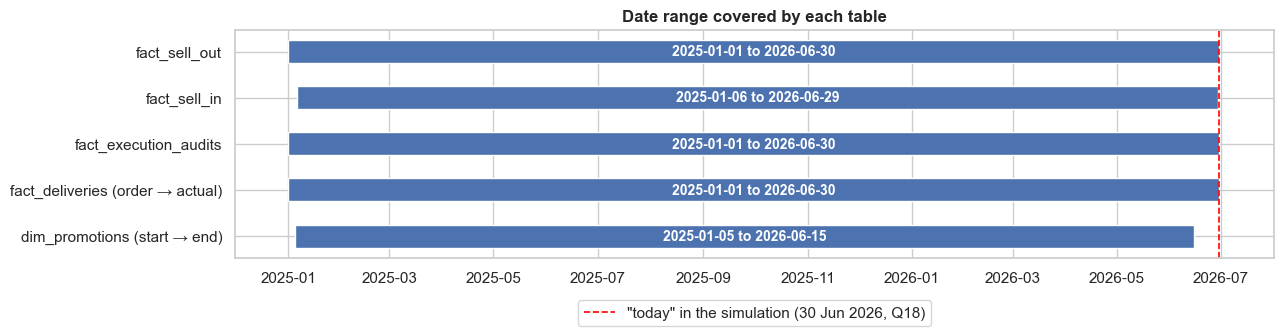

Deliveries scheduled after "today": 87 (0.06%); actual deliveries after "today": 0
Invoice dates: first 2025-01-06 (a Monday), last 2026-06-29; orders in fact_deliveries: 2025-01-01 to 2026-06-30


In [9]:
spans = {'fact_sell_out': (sell_out.date.min(), sell_out.date.max()),
         'fact_sell_in': (sell_in.date.min(), sell_in.date.max()),
         'fact_execution_audits': (audits.date.min(), audits.date.max()),
         'fact_deliveries (order → actual)': (deliveries.order_date.min(), deliveries.actual_delivery.max()),
         'dim_promotions (start → end)': (promos.start_date.min(), promos.end_date.max())}
fig, ax = plt.subplots(figsize=(13, 3.6))
for i, (n, (d0, d1)) in enumerate(spans.items()):
    ax.barh(i, (d1 - d0).days, left=d0, color='#4C72B0', height=0.5)
    ax.text(d0 + (d1 - d0) / 2, i, f'{d0.date()} to {d1.date()}', va='center', ha='center', fontsize=10, color='white', fontweight='bold')
ax.axvline(TODAY, color='red', ls='--', lw=1.2, label='"today" in the simulation (30 Jun 2026, Q18)')
ax.set_yticks(range(len(spans))); ax.set_yticklabels(spans.keys()); ax.invert_yaxis()
ax.set_xlim(pd.Timestamp('2024-12-01'), pd.Timestamp('2026-08-01'))
ax.set_title('Date range covered by each table'); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15))
show('03_date_coverage')
sched_after = deliveries.scheduled_delivery > TODAY
print(f'Deliveries scheduled after "today": {sched_after.sum():,} ({sched_after.mean():.2%}); actual deliveries after "today": {(deliveries.actual_delivery > TODAY).sum():,}')
print(f'Invoice dates: first {sell_in.date.min().date()} (a {sell_in.date.min().day_name()}), last {sell_in.date.max().date()}; '
      f'orders in fact_deliveries: {deliveries.order_date.min().date()} to {deliveries.order_date.max().date()}')

Sell-out and audits cover 1 Jan 2025 – 30 Jun 2026, as before. What changed:
1. **Sell-in now starts on Monday 6 Jan 2025.** Each invoice describes the week *before* its date, so the first one covers 30 Dec – 5 Jan, and the last one (29 Jun 2026) covers 22–28 June. The 29–30 June sell-out days have no invoice yet.
2. **Deliveries run from 1 Jan 2025 to 30 Jun 2026 and none arrive after "today"** (in the first update 1.1% landed in July). 87 deliveries (0.06%) were *scheduled* for 1 July but arrived a day early.
3. Promotions run from 5 Jan 2025 to 15 Jun 2026, so there are **no planned promos after "today"**. The second-half events of 2025 (Back to School, Fall Cleaning, Holiday Bundle) don't have a 2026 version in the file.

**The analysis window.** Everything above (3.1–3.6) checks structure, keys and formulas, so it uses the full data. From here on, every analysis uses **1 Jan 2025 – 31 May 2026** only. June 2026 is the test month for the OOS model, and patterns like OOS, missingness, restocks, promo lift or deliveries vs stock could shape modelling choices, so June has to stay out of them to avoid leakage. For deliveries we keep the ones that arrived by 31 May. Because each invoice now describes the week *before* its date, the last invoice in the window (25 May) covers up to Sunday 24 May; the sell-in vs sell-out gap is therefore always computed on matching weeks.

In [10]:
EDA_END = pd.Timestamp('2026-05-31')   # June 2026 = OOS model test month, kept out from here on
sell_out = sell_out[sell_out.date <= EDA_END].reset_index(drop=True)
sell_in = sell_in[sell_in.date <= EDA_END].reset_index(drop=True)                      # last invoice 25 May (covers 18-24 May)
deliveries = deliveries[deliveries.actual_delivery <= EDA_END].reset_index(drop=True)   # deliveries that arrived by 31 May
audits = audits[audits.date <= EDA_END].reset_index(drop=True)
v1 = {n: d[d.date <= EDA_END].reset_index(drop=True) if 'date' in d else d for n, d in v1.items()}
GAP_END = sell_in.date.max() - pd.Timedelta(days=1)   # each invoice covers the week before it: sell-in is complete up to this Sunday
print(f'Analysis window: {sell_out.date.min().date()} to {sell_out.date.max().date()} | sell-out rows {len(sell_out):,} | '
      f'invoice lines {len(sell_in):,} | deliveries {len(deliveries):,} | audit rows {len(audits):,} | sell-in gap compared up to {GAP_END.date()}')

Analysis window: 2025-01-01 to 2026-05-31 | sell-out rows 2,073,376 | invoice lines 259,286 | deliveries 134,742 | audit rows 196,930 | sell-in gap compared up to 2026-05-24


### 3.7 The missing days problem (again)
The change list says the 8% missing store-product-days are intentional and unchanged. In the first update the missing store-days had already dropped from 30.3% in v1 to about 8%. We measured again on the latest data.

In [11]:
store_days = sell_out[['store_id', 'date']].drop_duplicates()
all_days = pd.date_range(sell_out.date.min(), sell_out.date.max(), freq='D')
expected = len(stores) * len(all_days)
print(f'Store-days expected: {expected:,} | recorded: {len(store_days):,} | missing: {1 - len(store_days) / expected:.1%}   (v1: 30.3%)')

assortment = sell_out[['store_id', 'sku_id']].drop_duplicates()
skus_per_store = assortment.groupby('store_id').sku_id.nunique()
rows_per_store_day = sell_out.groupby(['store_id', 'date']).size()
full_days = (rows_per_store_day.values == skus_per_store.reindex(rows_per_store_day.index.get_level_values('store_id')).values).mean()
print(f'Recorded store-days where every SKU of the store is present: {full_days:.1%}')
missing_per_day = len(stores) - store_days.groupby('date').size()
print(f'Stores missing per day: min {missing_per_day.min()} | max {missing_per_day.max()}   (v1: exactly 67 every day)')

Store-days expected: 114,036 | recorded: 104,748 | missing: 8.1%   (v1: 30.3%)


Recorded store-days where every SKU of the store is present: 100.0%
Stores missing per day: min 18 | max 18   (v1: exactly 67 every day)


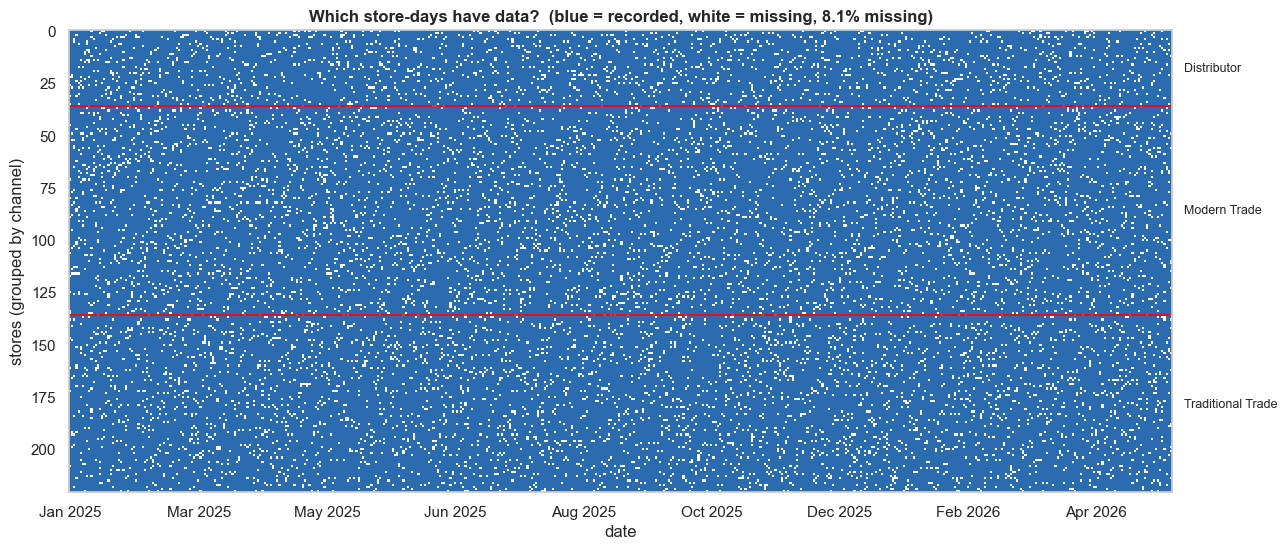

In [12]:
presence = (store_days.assign(v=1).pivot(index='store_id', columns='date', values='v')
            .reindex(columns=all_days).fillna(0))
presence = presence.reindex(stores.sort_values(['channel', 'store_id']).store_id)

fig, ax = plt.subplots(figsize=(15, 6))
ax.imshow(presence.values, aspect='auto', cmap=ListedColormap(['white', '#2b6cb0']), interpolation='nearest')
ax.grid(False)
ax.set_title(f'Which store-days have data?  (blue = recorded, white = missing, {1 - presence.values.mean():.1%} missing)')
ax.set_ylabel('stores (grouped by channel)'); ax.set_xlabel('date')
ticks = np.arange(0, len(all_days), 60)
ax.set_xticks(ticks); ax.set_xticklabels([all_days[i].strftime('%b %Y') for i in ticks])
ch_counts = stores.channel.value_counts().sort_index()
edges = ch_counts.cumsum().values
for e in edges[:-1]:
    ax.axhline(e - 0.5, color='red', lw=1.2)
for ch, s0, e in zip(ch_counts.index, np.r_[0, edges[:-1]], edges):
    ax.text(len(all_days) + 5, (s0 + e) / 2, ch, va='center', fontsize=9)
fig.subplots_adjust(right=0.86)
show('03_missing_store_days_heatmap', tight=False)

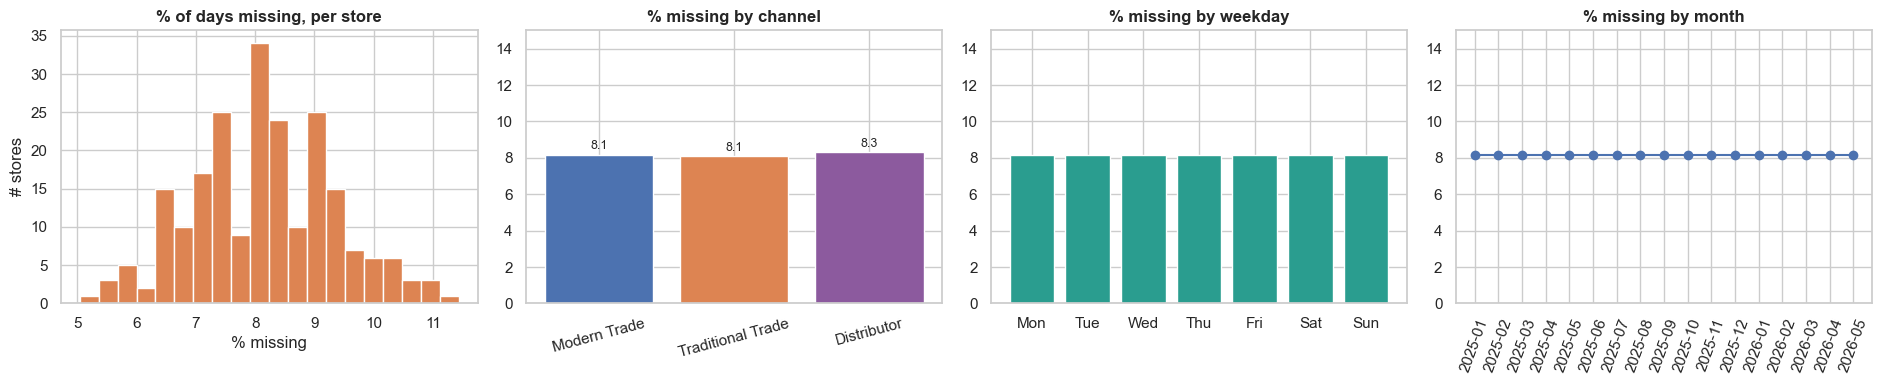

Missing per store: min 5.0% | median 8.1% | max 11.4%
Spread of missing % across stores: 1.22% | what pure chance would give: 1.20%


In [13]:
missing_by_store = 1 - presence.mean(axis=1)
daily_presence = presence.mean(axis=0)
dow_missing = 1 - daily_presence.groupby(all_days.dayofweek).mean()
month_missing = 1 - daily_presence.groupby(all_days.to_period('M')).mean()
ch_missing = missing_by_store.groupby(stores.set_index('store_id').channel).mean().reindex(CH_ORDER)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
axes[0].hist(missing_by_store * 100, bins=20, color='#DD8452'); axes[0].set_title('% of days missing, per store')
axes[0].set_xlabel('% missing'); axes[0].set_ylabel('# stores')
axes[1].bar(ch_missing.index, ch_missing.values * 100, color=[CH_COL[c] for c in ch_missing.index])
axes[1].set_title('% missing by channel'); axes[1].set_ylim(0, 15); axes[1].tick_params(axis='x', rotation=15); label_bars(axes[1])
axes[2].bar(DAYS, dow_missing.values * 100, color='#2A9D8F'); axes[2].set_title('% missing by weekday'); axes[2].set_ylim(0, 15)
axes[3].plot(month_missing.index.astype(str), month_missing.values * 100, marker='o')
axes[3].set_title('% missing by month'); axes[3].set_ylim(0, 15); axes[3].tick_params(axis='x', rotation=70)
show('03_missing_patterns')
p_miss = 1 - presence.values.mean()
print(f'Missing per store: min {missing_by_store.min():.1%} | median {missing_by_store.median():.1%} | max {missing_by_store.max():.1%}')
print(f'Spread of missing % across stores: {missing_by_store.std():.2%} | what pure chance would give: {np.sqrt(p_miss * (1 - p_miss) / len(all_days)):.2%}')

**What we found**
1. Missing store-days are **8.1%** (v1: 30.3%), as the change list says. The shape is the same as in the first update and in v1: always a whole store-day, never partial, and **exactly 18 stores are missing every single day** (v1: exactly 67).
2. There's no pattern by channel (8.1–8.3%), weekday or month, and the spread across stores (1.22 points) is what pure chance gives (1.20). So the gaps are still **missing completely at random**, and averages over reported days are unbiased.

### 3.8 Internal consistency: does the stock math add up?
With the new restock columns we can now write the stock math exactly, on the reported rows:

$$\text{stock}_{today} = \text{stock}_{previous\ report} - \text{units sold}_{today} + \text{restock units}_{today}$$

In v1 we had to *back out* the deliveries from the stock; now they are given. We split by days since the previous recorded row: if sales or restocks happened on the missing days, the stock after a gap would not follow the formula.

In [14]:
so = sell_out.sort_values(['store_id', 'sku_id', 'date']).reset_index(drop=True)
g = so.groupby(['store_id', 'sku_id'])
so['gap_days'] = g.date.diff().dt.days
so['prev_inv'] = g.inventory_level.shift()
so['stock_gap'] = so.inventory_level - (so.prev_inv - so.units_sold_daily + so.restock_units)   # 0 when the stock math is exact

gap_check = (so.dropna(subset=['gap_days'])
               .assign(days_since_last_record=lambda d: d.gap_days.clip(upper=4).astype(int).astype(str).replace({'4': '4+'}))
               .groupby('days_since_last_record')
               .agg(rows=('stock_gap', 'size'),
                    stock_math_exact=('stock_gap', lambda x: (x == 0).mean()),
                    rows_with_restock=('restock_units', lambda x: (x > 0).mean())))
display(gap_check.round(3))
print('Rows where the stock math does not add up:', int((so.stock_gap.dropna() != 0).sum()))

# deliveries on the days a store did not report
sd = presence.rename_axis(columns='date').stack().rename('reported').reset_index()
dlv_days = (deliveries[['store_id', 'actual_delivery']].drop_duplicates()
            .rename(columns={'actual_delivery': 'date'}).assign(delivery_recorded=True))
sd = sd.merge(dlv_days, on=['store_id', 'date'], how='left')
sd['delivery_recorded'] = sd.delivery_recorded.eq(True)
print(f"Store-days with at least one delivery in fact_deliveries: missing store-days {sd.loc[sd.reported == 0, 'delivery_recorded'].mean():.1%} "
      f"| reported store-days {sd.loc[sd.reported == 1, 'delivery_recorded'].mean():.1%}")
unlinked = deliveries[~deliveries.delivery_id.isin(so.restock_delivery_id.dropna())]
u = unlinked.merge(sd[['store_id', 'date', 'reported']], left_on=['store_id', 'actual_delivery'], right_on=['store_id', 'date'], how='left')
print(f"Deliveries with no restock row in sell-out: {len(unlinked):,} ({len(unlinked) / len(deliveries):.1%}) | "
      f"of those, arriving on a day the store did not report: {(u.reported == 0).mean():.1%} | "
      f"units: {unlinked.units_delivered.sum():,} ({unlinked.units_delivered.sum() / deliveries.units_delivered.sum():.1%} of all delivered units)")
del sd, dlv_days, u

,rows,stock_math_exact,rows_with_restock
days_since_last_record,,,
1,1899743,1.0,0.060
2,156557,1.0,0.060
3,11429,1.0,0.061
4+,1272,1.0,0.068


Rows where the stock math does not add up: 0
Store-days with at least one delivery in fact_deliveries: missing store-days 67.8% | reported store-days 66.9%
Deliveries with no restock row in sell-out: 11,119 (8.3%) | of those, arriving on a day the store did not report: 100.0% | units: 1,045,257 (8.3% of all delivered units)


**What we found**
The stock math is now **exact on 100% of reported rows**: stock = previous reported stock − sales + restock units. It holds right after gaps of 2, 3 and 4+ days too, and restocks show up at the same ~6% rate whether or not there was a gap. So in `fact_sell_out`, **the inventory looks frozen across missing days**: the next reported stock picks up exactly where the last one left off.

That doesn't mean nothing happened on those days:
1. **Sales are unknown, not zero.** The store simply didn't report them (Dr. Masse, Q11: not reported, not zero sales).
2. **Deliveries do arrive on missing store-days.** `fact_deliveries` records a delivery on 67.8% of missing store-days, about the same rate as on reported days (66.9%). **11,119 deliveries (8.3% of all, about 1.05M units) have no restock row in sell-out, and every one of them lands on a day the store did not report.** After the gap the stock carries on as if they never arrived.

So the data suggests that the sell-out inventory is frozen across missing days in the simulation, and that deliveries recorded on those days are never added to it. In this EDA we carry the last reported stock forward (which is how the sell-out inventory behaves) and use averages per *reported* day for sales. How to fill gap-day sales and stock is a question for the missing-data notebook; with 8% gaps instead of 30%, it matters much less now.

### 3.9 Do the deliveries now explain the stock restocks?
On the first update, the biggest limit for the OOS model was that **we couldn't know when the next restock lands**: `fact_deliveries` looked unrelated to the stock. The latest data links every restock in sell-out to a delivery. So the questions are: does the link hold up, how long before arrival is an order known, and does every delivery reach the stock?

Restock rows linked to a delivery: 100.0% | same units: 100.0% | restock date = actual delivery date: 100.0%


,restocks_per_store_sku,deliveries_per_store_sku,deliveries_not_in_stock_%,avg_restock_units,restock_units_÷_sellout,delivered_units_÷_sellout,orders_known_ahead_%
Modern Trade,29.83,32.52,8.26,112.48,1.04,1.13,41.82
Traditional Trade,25.67,27.97,8.22,65.56,1.03,1.12,72.39
Distributor,29.74,32.43,8.29,95.14,1.03,1.12,25.54


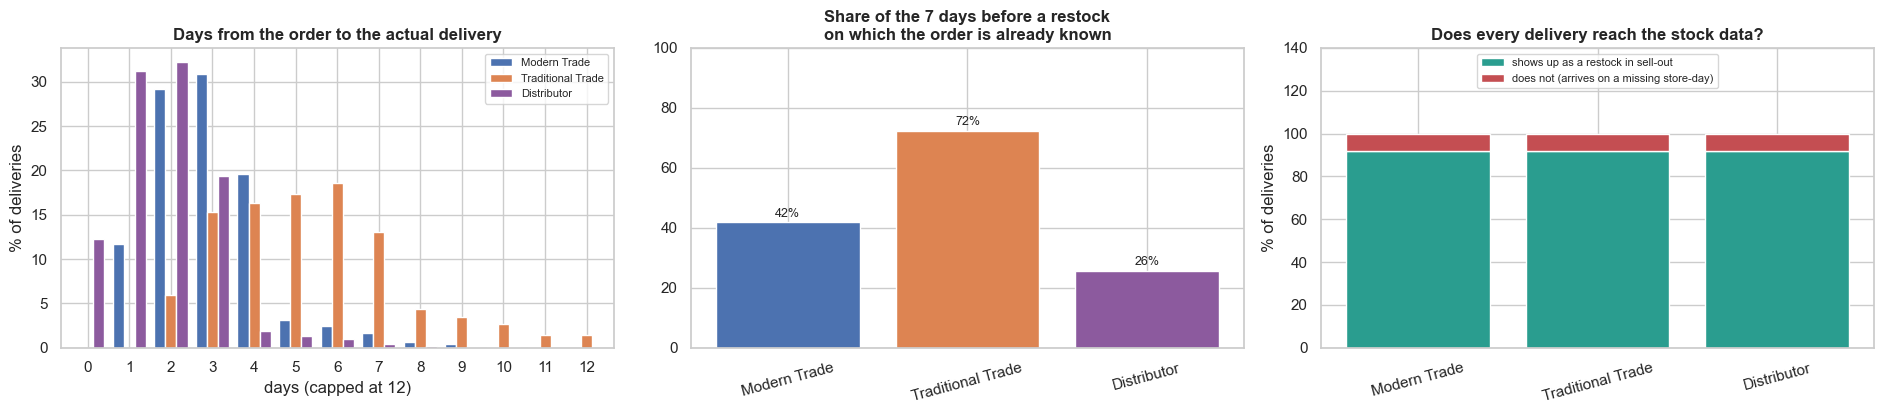

In [15]:
refills = so.loc[so.restock_units > 0, ['store_id', 'sku_id', 'date', 'restock_units', 'prev_inv', 'restock_delivery_id']].sort_values('date')
j = refills.merge(deliveries, left_on='restock_delivery_id', right_on='delivery_id')
print(f"Restock rows linked to a delivery: {refills.restock_delivery_id.notna().mean():.1%} | same units: {(j.restock_units == j.units_delivered).mean():.1%} | "
      f"restock date = actual delivery date: {(j.date == j.actual_delivery).mean():.1%}")

d9 = deliveries.assign(channel=deliveries.store_id.map(ch_of), lead_order_to_arrival=(deliveries.actual_delivery - deliveries.order_date).dt.days,
                       reaches_stock=deliveries.delivery_id.isin(refills.restock_delivery_id))
d9['known_ahead'] = np.minimum(d9.lead_order_to_arrival, 7) / 7      # share of the 7 days before arrival on which the order already exists
pairs_ch = assortment.store_id.map(ch_of).value_counts()
so_ch = so.store_id.map(ch_of)
link = pd.DataFrame({
    'restocks_per_store_sku': refills.store_id.map(ch_of).value_counts() / pairs_ch,
    'deliveries_per_store_sku': deliveries.store_id.map(ch_of).value_counts() / pairs_ch,
    'deliveries_not_in_stock_%': d9.groupby('channel').reaches_stock.apply(lambda s: (1 - s.mean()) * 100),
    'avg_restock_units': refills.groupby(refills.store_id.map(ch_of)).restock_units.mean(),
    'restock_units_÷_sellout': refills.groupby(refills.store_id.map(ch_of)).restock_units.sum() / so.groupby(so_ch).units_sold_daily.sum(),
    'delivered_units_÷_sellout': deliveries.groupby(deliveries.store_id.map(ch_of)).units_delivered.sum() / so.groupby(so_ch).units_sold_daily.sum(),
    'orders_known_ahead_%': d9.groupby('channel').known_ahead.mean() * 100}).reindex(CH_ORDER).round(2)
display(link)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
lead9 = d9.assign(lead=d9.lead_order_to_arrival.clip(upper=12)).groupby(['lead', 'channel']).size().unstack()[CH_ORDER].fillna(0)
(lead9 / lead9.sum() * 100).plot.bar(ax=axes[0], color=[CH_COL[c] for c in CH_ORDER], rot=0, width=0.8)
axes[0].set_title('Days from the order to the actual delivery'); axes[0].set_xlabel('days (capped at 12)'); axes[0].set_ylabel('% of deliveries'); axes[0].legend(fontsize=8)
kn = d9.groupby('channel').known_ahead.mean().reindex(CH_ORDER) * 100
axes[1].bar(kn.index, kn.values, color=[CH_COL[c] for c in kn.index]); label_bars(axes[1], '{:.0f}%'); axes[1].set_ylim(0, 100)
axes[1].set_title('Share of the 7 days before a restock\non which the order is already known'); axes[1].tick_params(axis='x', rotation=15)
reach = d9.groupby('channel').reaches_stock.mean().reindex(CH_ORDER) * 100
axes[2].bar(reach.index, reach.values, color='#2A9D8F', label='shows up as a restock in sell-out')
axes[2].bar(reach.index, 100 - reach.values, bottom=reach.values, color='#C44E52', label='does not (arrives on a missing store-day)')
axes[2].set_ylim(0, 140); axes[2].legend(fontsize=8, loc='upper center', ncol=1); axes[2].set_title('Does every delivery reach the stock data?'); axes[2].set_ylabel('% of deliveries'); axes[2].tick_params(axis='x', rotation=15)
show('03_restocks_vs_deliveries')

**What we found**
Yes, at last. The deliveries now explain the stock restocks:
1. **100% of restock rows are linked to a delivery**, with the same units and the same date.
2. The counts differ only by the deliveries that land on missing store-days: a Modern Trade store-SKU has 29.8 restocks and 32.5 deliveries over the 17 months (Traditional Trade 25.7 and 28.0; Distributors 29.7 and 32.4). The gap is exactly the **8.3% of deliveries** that arrive on a day the store didn't report. In units, restocks equal about 103–104% of sell-out and deliveries 112–113%.
3. **Orders are placed 2 to 7 days before they arrive**: median 2 days for Distributors, 3 for Modern Trade and 5 for Traditional Trade. That means that on any day the next restock is only partly known in advance: the order already exists on **72%** of the 7 days before a Traditional Trade restock, **42%** for Modern Trade and just **26%** for Distributors.

Why this matters: on the first update, the biggest blocker for the OOS model was that the next restock date was unknowable, and a "planned delivery date" was our main data ask. The scheduled delivery date is now a legitimate input, **but only for restocks that were ordered before the day we predict from**, and the short lead times of Modern Trade and Distributors limit how much of the 7-day horizon it covers. How much it helps is a question for the modelling notebook.

### 3.10 Outliers
Same 1.5 × IQR rule as v1, on the main numeric columns (including the new ones):

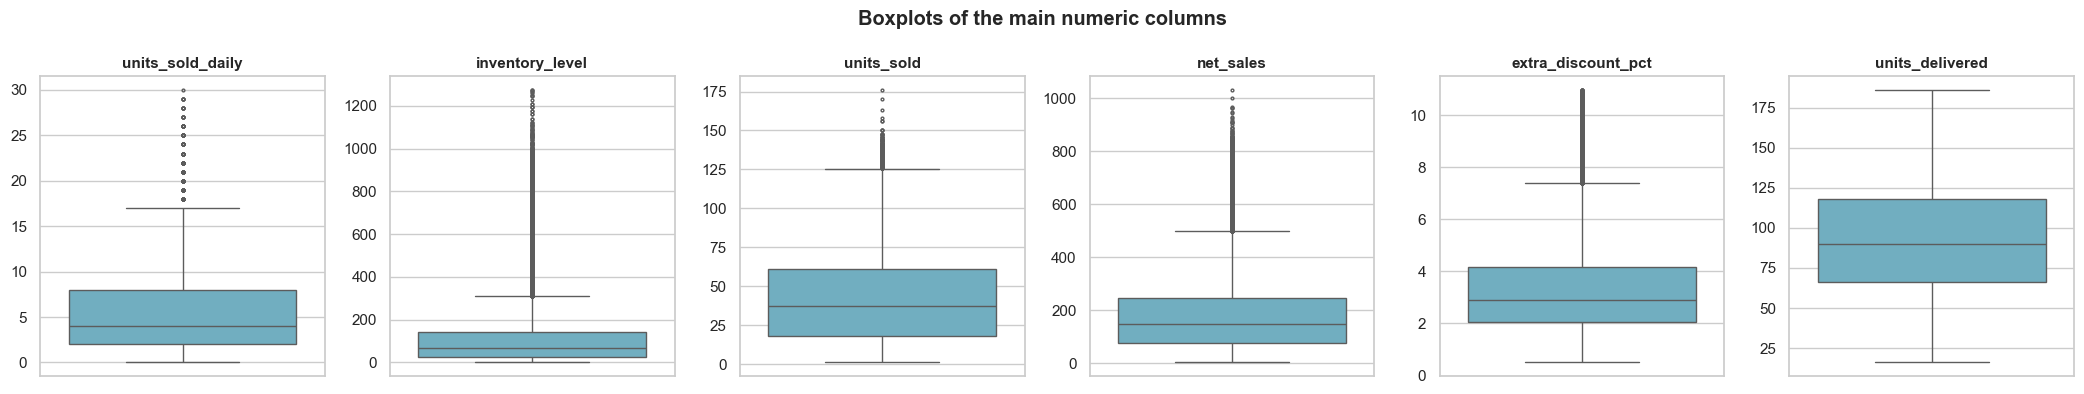

,column,min,median,max,upper_fence,outlier_%
0,fact_sell_out.units_sold_daily,0.00,4.00,34.00,17.000,1.27
1,fact_sell_out.inventory_level,0.00,66.00,1341.00,313.000,7.54
2,fact_sell_in.units_sold,1.00,37.00,176.00,125.500,0.23
3,fact_sell_in.net_sales,2.13,149.29,1032.25,497.575,2.65
4,fact_sell_in.extra_discount_pct,0.50,2.89,10.98,7.440,2.83
5,fact_deliveries.units_delivered,16.00,90.00,186.00,196.000,0.00


Where do the "outlier" sales days (> 17.0 units) come from? {'Tier 1': 99.6, 'Tier 2': 0.4}


In [16]:
num_cols = [('fact_sell_out', 'units_sold_daily'), ('fact_sell_out', 'inventory_level'), ('fact_sell_in', 'units_sold'),
            ('fact_sell_in', 'net_sales'), ('fact_sell_in', 'extra_discount_pct'), ('fact_deliveries', 'units_delivered')]
rows = []
fig, axes = plt.subplots(1, 6, figsize=(21, 4))
for ax, (t, c) in zip(axes, num_cols):
    x = tables[t][c]
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    rows.append({'column': f'{t}.{c}', 'min': x.min(), 'median': x.median(), 'max': x.max(),
                 'upper_fence': q3 + 1.5 * iqr, 'outlier_%': round(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean() * 100, 2)})
    sns.boxplot(y=x.sample(200_000, random_state=0) if len(x) > 200_000 else x, ax=ax, color='#64B5CD', fliersize=2)
    ax.set_title(c, fontsize=11); ax.set_ylabel('')
plt.suptitle('Boxplots of the main numeric columns', fontweight='bold'); show('03_outliers')
display(pd.DataFrame(rows))

fence = rows[0]['upper_fence']
high = sell_out[sell_out.units_sold_daily > fence].merge(stores[['store_id', 'segment_tier']], on='store_id')
print(f'Where do the "outlier" sales days (> {fence:.1f} units) come from?',
      (high.segment_tier.value_counts(normalize=True) * 100).round(1).to_dict())
del high

**What we found**
Same as before: only 0–8% of values are flagged, and **99.6%** of the "outlier" sales days come from Tier 1 stores. They're big stores, not errors, so we keep them. New: stock levels have 7.5% flagged values (median 66, maximum 1,341 units), again big Tier 1 stores (4.1). Delivered units have no outliers (16–186 per delivery).

### 3.11 Checking the client's change list
Putting 3.2–3.10 together against the note Dr. Masse sent on 16 October:

| Client said | What we found | Verified? |
|---|---|---|
| `fact_sell_out`: every restock linked to a delivery (`restock_units`, `restock_delivery_id`) | Yes: 100% linked, same units and date, one-to-one (3.4, 3.9) | Yes |
| `fact_sell_out`: execution uplift built into daily sales (display +8%, planogram +5%, shelf share +3% per 10 points) | We measure 0.1–1.2%, about ten times smaller, with three ways of linking audits to sales (8.7) | **Not confirmed** |
| 8% missing store-product-days unchanged | 8.1% missing, whole days, random (3.7) | Yes |
| January OOS elevated (12.8%) | 12.8% in Jan 2025 vs 6.5% in Jan 2026 (6.5). In the first update January 2025 was *lower* (3.6%) | Yes |
| `fact_sell_in`: invoice date = Monday after the sell-out week; earliest 6 Jan 2025 | Yes; an invoice equals the previous 7 days of sell-out × 1.11, and no longer tracks the next 7 (8.3) | Yes |
| `guardrail_violation` and `extra_discount_pct` "already in the file from the previous update" | They are in the file now, but they were **not** in the sell-in file of 10 October that we received | Present now |
| `fact_deliveries`: "Early" = early, "On Time" = exact | Yes (3.5) | Yes |
| `fact_deliveries`: `fill_rate_pct` matches units; "Short Ship" only when short | Yes, to two decimals (3.5) | Yes |
| `fact_deliveries`: nothing after 30 Jun 2026 | Yes: 0 deliveries after "today" (3.6) | Yes |
| `fact_execution_audits`: shelf share sums to 100% per visit; no rows for missing store-SKU pairs | Yes on both (3.5, 3.2) | Yes |
| *(not in the note)* | `dim_guardrails` rebuilt (new `standard_discount_pct`, new caps); `fact_deliveries` rebuilt (no invoice link, half the rows); sell-out regenerated again (14% of shared rows have the same units); stock levels twice as high | New findings |

### 3.12 Data quality summary

| Check | Result | What we'll do |
|---|---|---|
| Nulls, duplicates, keys | Clean; the only nulls mean "no promo" or "no restock" | Nothing |
| Referential integrity | All IDs and promo links match; **restock ↔ delivery link exact** | Use the link |
| Sales, price and discount arithmetic | Exact (discount = standard + extra) | Nothing |
| Deliveries: fill rate, status, dates | All correct now | Use the label or the dates |
| Audits | Shelf share sums to 100% per visit; no orphan rows | Re-define the shelf-share KPI (4.8) |
| Date range | Ends 30 Jun 2026; no delivery after "today" | Nothing |
| Missing store-days | 8.1% (was 30.3%), whole days, random | Same handling as before, much smaller impact |
| Stock across missing days | Exact on reported days; frozen across gaps; 8.3% of deliveries (all on missing days) never reach the stock | Carry stock forward; treat gap-day sales as unknown |
| June 2026 | Test month for the OOS model | Left out of every analysis from 3.7 on |
| Data regenerated | Only 14% of shared rows match v1 | Re-check every v1 number |
| Outliers | Real Tier 1 volume and stock | Keep them |
| `dim_guardrails` | The 16 Oct file differs from the earlier one (new standard-discount column, different caps and margins); the shared V3 data platform still uses the earlier file | Confirm which version is final (section 10) |

## 4. Univariate analysis
As in v1, we first join store and product info onto sell-out once. One thing is different: v1 had no prices in sell-out, so we valued sales at list price. Now we have the **price the consumer actually paid**, so `sales_value` = units × `consumer_price_actual`. (We keep `list_value` = units × list price for anything about Marvel's own revenue, since list price is the trade price, Q5.)

In [17]:
sof = (so[['date', 'store_id', 'sku_id', 'units_sold_daily', 'inventory_level', 'is_out_of_stock',
           'consumer_price_actual', 'promo_id', 'promo_discount_pct']]
       .merge(stores[['store_id', 'channel', 'region', 'state', 'segment_tier']], on='store_id')
       .merge(products[['sku_id', 'product_name', 'category', 'brand', 'is_msl', 'list_price', 'consumer_price']], on='sku_id'))
sof['on_promo'] = sof.promo_id.notna()
sof['sales_value'] = sof.units_sold_daily * sof.consumer_price_actual
sof['list_value'] = sof.units_sold_daily * sof.list_price
sof_gap = sof[sof.date <= GAP_END]          # sell-out for the weeks that have an invoice (see 3.6)
si = (sell_in.merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
             .merge(products[['sku_id', 'category', 'list_price', 'unit_cost']], on='sku_id'))
si['on_promo'] = si.promo_id.notna()
au = (audits.merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
            .merge(products[['sku_id', 'category']], on='sku_id'))
dv = (deliveries.merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
                .merge(products[['sku_id', 'category']], on='sku_id'))
dv['lead_scheduled'] = (dv.scheduled_delivery - dv.order_date).dt.days
dv['lead_actual'] = (dv.actual_delivery - dv.order_date).dt.days
dv['days_vs_schedule'] = (dv.actual_delivery - dv.scheduled_delivery).dt.days
print(sof.shape, si.shape, au.shape, dv.shape)

(2073376, 22) (259286, 18) (196930, 11) (134742, 18)


### 4.1 Stores and products
`dim_stores` didn't change, so this is a quick reminder of who the stores are (details in v1, section 4.1). The product table is the same 23 SKUs with the same cost and list price, plus a new `consumer_price`.

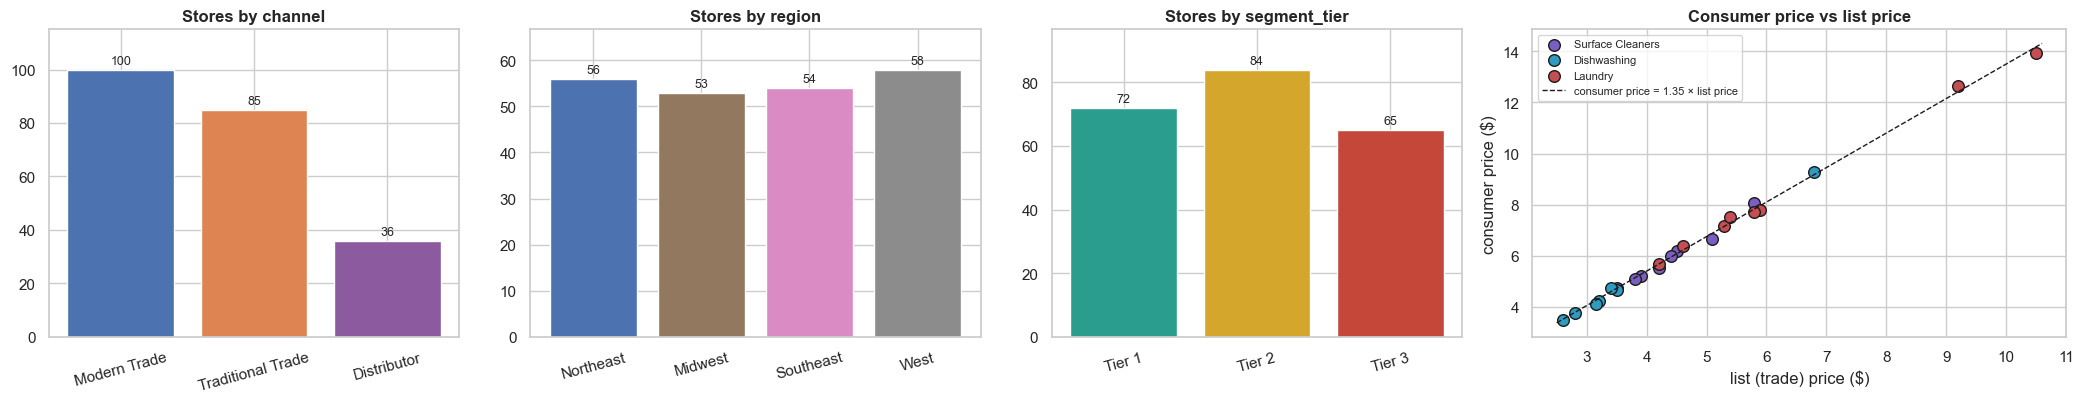

segment_tier,Tier 1,Tier 2,Tier 3
channel,,,
Modern Trade,41,35,24
Traditional Trade,16,39,30
Distributor,15,10,11


,sku_id,product_name,category,is_msl,unit_cost,list_price,consumer_price,consumer_over_list,margin_on_list_pct
0,SKU-1001,Marvel Power Clean Lemon 1L,Surface Cleaners,True,2.10,4.50,6.17,1.37,53.3
1,SKU-1002,Marvel Power Clean Original 1L,Surface Cleaners,True,2.05,4.40,5.98,1.36,53.4
2,SKU-1003,Marvel Power Clean Lavender 750ml,Surface Cleaners,False,1.85,3.90,5.22,1.34,52.6
3,SKU-1004,Marvel Heavy-Duty Degreaser 1L,Surface Cleaners,True,2.80,5.80,8.07,1.39,51.7
4,SKU-1005,Marvel Heavy-Duty Degreaser 500ml,Surface Cleaners,False,1.65,3.50,4.72,1.35,52.9
5,SKU-1006,Marvel Glass & Surface Spray 32oz,Surface Cleaners,True,1.95,4.20,5.52,1.31,53.6
6,SKU-1007,Marvel Bathroom Foam Cleaner 20oz,Surface Cleaners,False,1.75,3.80,5.08,1.34,53.9
7,SKU-1008,Marvel Multi-Surface Wipes 75ct,Surface Cleaners,True,2.45,5.10,6.66,1.31,52.0
8,SKU-1009,Marvel Dish Soap Citrus 28oz,Dishwashing,True,1.50,3.20,4.22,1.32,53.1
9,SKU-1010,Marvel Dish Soap Original 28oz,Dishwashing,True,1.48,3.15,4.10,1.30,53.0


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2), gridspec_kw={'width_ratios': [1, 1.1, 1, 1.3]})
for ax, col, order, pal in zip(axes[:3], ['channel', 'region', 'segment_tier'], [CH_ORDER, REGION_ORDER, TIER_ORDER], [CH_COL, REG_COL, TIER_COL]):
    cnt = stores[col].value_counts().reindex(order)
    ax.bar(cnt.index, cnt.values, color=[pal[x] for x in cnt.index])
    label_bars(ax, '{:.0f}'); ax.set_title(f'Stores by {col}'); ax.tick_params(axis='x', rotation=15); ax.set_ylim(0, cnt.max() * 1.15)
for cat in CAT_ORDER:
    sub = products[products.category == cat]
    axes[3].scatter(sub.list_price, sub.consumer_price, s=70, color=CAT_COL[cat], label=cat, edgecolor='k')
x = np.linspace(2.5, 10.6, 10)
axes[3].plot(x, 1.35 * x, 'k--', lw=1, label='consumer price = 1.35 × list price')
axes[3].set_xlabel('list (trade) price ($)'); axes[3].set_ylabel('consumer price ($)'); axes[3].set_title('Consumer price vs list price'); axes[3].legend(fontsize=8)
show('04_stores_products')
display(pd.crosstab(stores.channel, stores.segment_tier).reindex(CH_ORDER)[TIER_ORDER])
display(products.assign(consumer_over_list=lambda d: (d.consumer_price / d.list_price).round(2),
                        margin_on_list_pct=lambda d: ((d.list_price - d.unit_cost) / d.list_price * 100).round(1))
                [['sku_id', 'product_name', 'category', 'is_msl', 'unit_cost', 'list_price', 'consumer_price', 'consumer_over_list', 'margin_on_list_pct']])

**Notes**
1. Same 221 stores as v1: 100 Modern Trade, 85 Traditional Trade, 36 Distributors. Modern Trade is mostly Tier 1; Traditional Trade is mostly Tier 2 and 3.
2. The **consumer price is 1.30–1.40× the list price** for every SKU, which fits Q5 ("typically 20–40% higher"). So we have two prices: what Marvel charges the store (list) and what the shopper pays (consumer).
3. Unit cost and list price didn't change, so the margin on list price is still 51–54% everywhere.
### 4.2 Daily sales (sell-out)

,count,mean,std,min,25%,50%,75%,max,zero_sales_share
v1,1565789.0,4.73,3.87,0.0,2.0,4.0,7.0,32.0,0.117
v3,2073376.0,5.40,4.40,0.0,2.0,4.0,8.0,34.0,0.114


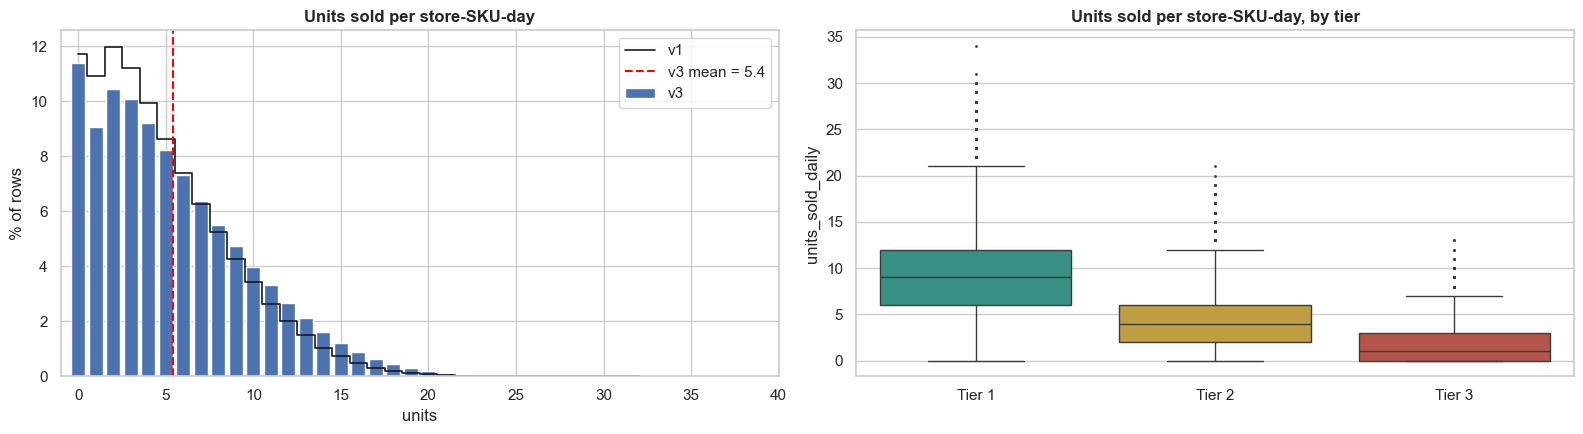

In [19]:
u, u1 = sof.units_sold_daily, v1['fact_sell_out'].units_sold_daily
display(pd.DataFrame({'v1': u1.describe(), 'v3': u.describe()}).T.round(2).assign(zero_sales_share=[(u1 == 0).mean().round(3), (u == 0).mean().round(3)]))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
vc = u.value_counts(normalize=True).sort_index() * 100
vc1 = u1.value_counts(normalize=True).sort_index() * 100
axes[0].bar(vc.index, vc.values, color='#4C72B0', label='v3')
axes[0].step(vc1.index, vc1.values, where='mid', color='k', lw=1.2, label='v1')
axes[0].axvline(u.mean(), color='red', ls='--', label=f'v3 mean = {u.mean():.1f}')
axes[0].set_title('Units sold per store-SKU-day'); axes[0].set_xlabel('units'); axes[0].set_ylabel('% of rows'); axes[0].legend(); axes[0].set_xlim(-1, 40)
samp = sof.sample(300_000, random_state=1)
sns.boxplot(data=samp, x='segment_tier', y='units_sold_daily', order=TIER_ORDER, hue='segment_tier', palette=TIER_COL, legend=False, ax=axes[1], fliersize=1)
axes[1].set_title('Units sold per store-SKU-day, by tier'); axes[1].set_xlabel('')
show('04_daily_sales')

**Notes:** Daily sales per SKU are still small, right-skewed counts (median 4 units, max 34, 11% zero-sales days), but the mean went up from 4.73 to **5.40** (+14%). Tier is still the big split.
### 4.3 Stock levels

,count,mean,std,min,25%,50%,75%,max
v1,1565789.0,45.7,42.8,0.0,14.0,32.0,65.0,315.0
v3,2073376.0,107.4,125.4,0.0,27.0,65.0,139.0,1341.0


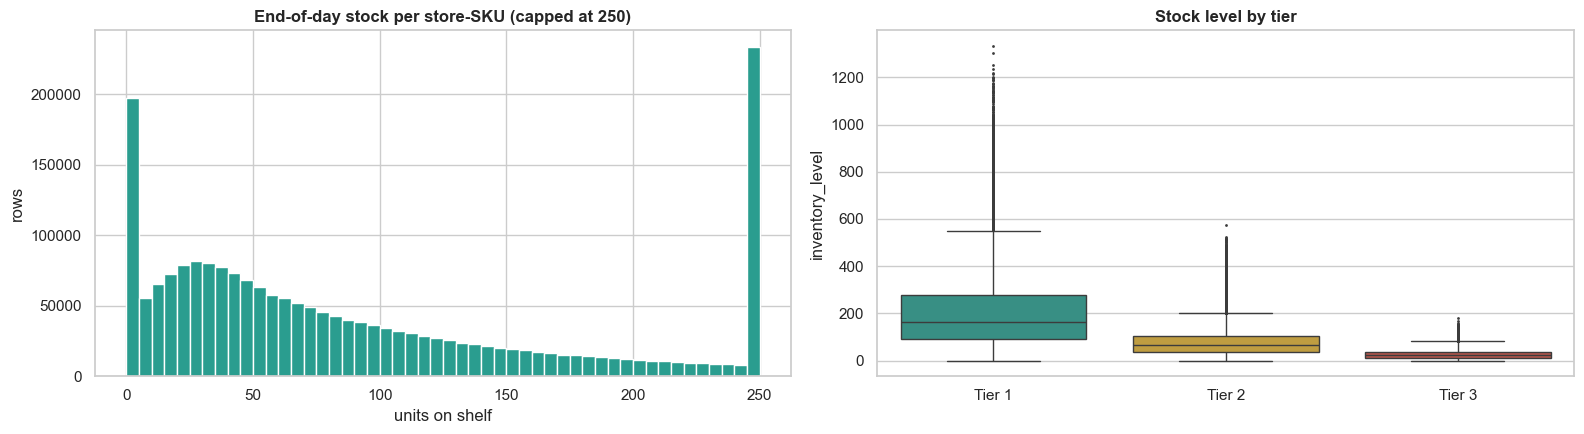

In [20]:
inv, inv1 = sof.inventory_level, v1['fact_sell_out'].inventory_level
display(pd.DataFrame({'v1': inv1.describe(), 'v3': inv.describe()}).T.round(1))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].hist(inv.clip(upper=250), bins=50, color='#2A9D8F')
axes[0].set_title('End-of-day stock per store-SKU (capped at 250)'); axes[0].set_xlabel('units on shelf'); axes[0].set_ylabel('rows')
sns.boxplot(data=samp, x='segment_tier', y='inventory_level', order=TIER_ORDER, hue='segment_tier', palette=TIER_COL, legend=False, ax=axes[1], fliersize=1)
axes[1].set_title('Stock level by tier'); axes[1].set_xlabel('')
show('04_stock_levels')

**Notes:** Stock levels are **about twice as high as in v1**: median 65 units (v1: 32), mean 107 (v1: 46), maximum 1,341 (v1: 315), still with a spike at 0 for the OOS days. The difference is entirely in the big stores: Tier 1 holds 205 units of a SKU on average, Tier 2 75 and Tier 3 only 26. Measured in days of average sales, that is about 22 days of stock in Tier 1, 17 in Tier 2 and 15 in Tier 3 (8.1, 8.2).
### 4.4 Prices and promotions in sell-out (new)
v1 had no price column in sell-out at all. Now every row has the price the consumer paid and, if a promo was running, the promo and its discount.

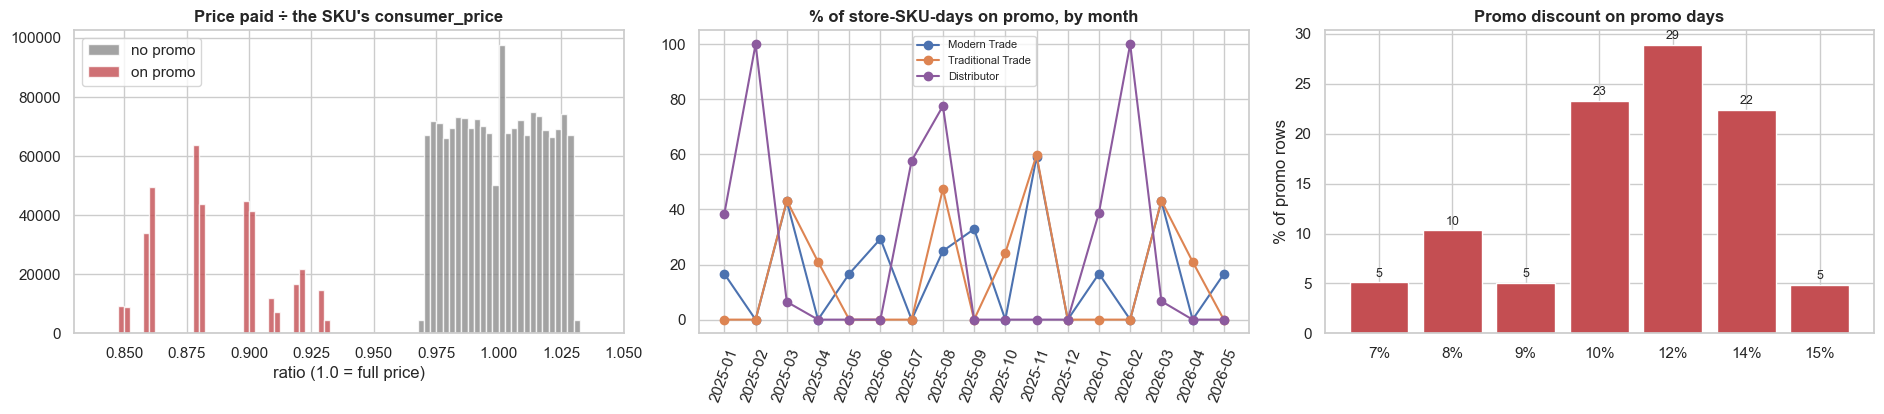

Store-SKU-days on promo: 17.9% | everyday price range: 0.969 to 1.031


In [21]:
sof['price_vs_consumer_price'] = sof.consumer_price_actual / sof.consumer_price
fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
for flag, col, lbl in [(False, '#8C8C8C', 'no promo'), (True, '#C44E52', 'on promo')]:
    axes[0].hist(sof.loc[sof.on_promo == flag, 'price_vs_consumer_price'], bins=np.arange(0.84, 1.04, 0.0025), color=col, alpha=0.8, label=lbl)
axes[0].set_title('Price paid ÷ the SKU\'s consumer_price'); axes[0].set_xlabel('ratio (1.0 = full price)'); axes[0].legend()
promo_share = sof.groupby([sof.date.dt.to_period('M'), 'channel']).on_promo.mean().unstack()[CH_ORDER] * 100
for ch in CH_ORDER:
    axes[1].plot(promo_share.index.astype(str), promo_share[ch], marker='o', color=CH_COL[ch], label=ch)
axes[1].set_title('% of store-SKU-days on promo, by month'); axes[1].tick_params(axis='x', rotation=70); axes[1].legend(fontsize=8)
dist = sof.loc[sof.on_promo, 'promo_discount_pct'].value_counts(normalize=True).sort_index() * 100
axes[2].bar(dist.index.astype(int).astype(str) + '%', dist.values, color='#C44E52'); label_bars(axes[2], '{:.0f}')
axes[2].set_title('Promo discount on promo days'); axes[2].set_ylabel('% of promo rows')
show('04_prices_promos_sellout')
print(f"Store-SKU-days on promo: {sof.on_promo.mean():.1%} | everyday price range: "
      f"{sof.loc[~sof.on_promo, 'price_vs_consumer_price'].min():.3f} to {sof.loc[~sof.on_promo, 'price_vs_consumer_price'].max():.3f}")

**Notes:**
1. **17.9%** of store-SKU-days are on promo.
2. On normal days the price paid moves evenly within **±3%** of the consumer price (the grey block). On promo days it drops by exactly the promo discount, so the red bars sit at a few fixed levels (7–15% off).
3. Promos are very uneven over time. Distributors are on promo for **all of February** in both years (the Q1 volume deal), and Modern and Traditional Trade peak in March (Spring Clean Blitz, ~43% of days) and November (Holiday Bundle, ~59%).

Section 8.5 checks whether sales actually respond to the price changes.

### 4.5 Sell-in (invoices)
The discount is now split into two columns: `standard_discount_pct` (a fixed level per channel × category, from `dim_guardrails`) plus `extra_discount_pct`, the negotiated part. `discount_pct` is their sum (3.5).

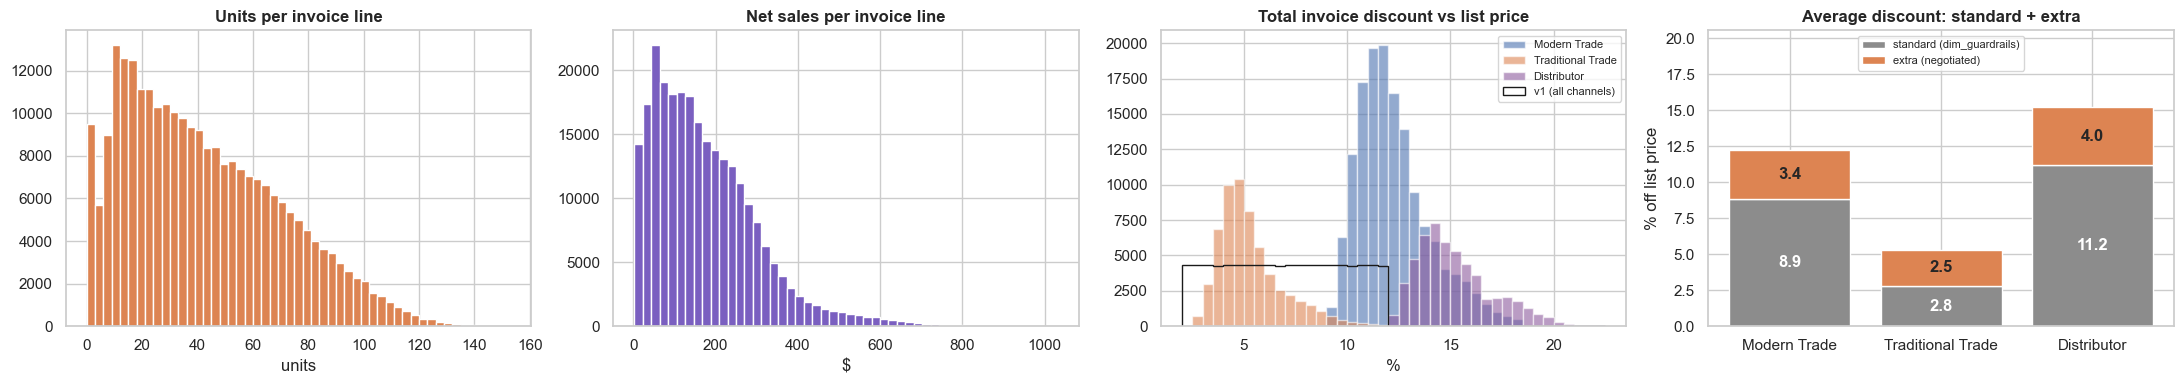

,units_sold,net_sales,discount_pct,standard,extra,promo_share,flagged_share
channel,,,,,,,
Modern Trade,48.799,204.239,12.250,8.866,3.384,0.179,0.030
Traditional Trade,24.457,110.472,5.314,2.799,2.516,0.156,0.029
Distributor,41.447,166.513,15.221,11.209,4.012,0.247,0.031


In [22]:
sg = si.merge(guardrails[['channel', 'category', 'standard_discount_pct', 'max_discount_pct']], on=['channel', 'category'])
fig, axes = plt.subplots(1, 4, figsize=(22, 4))
axes[0].hist(si.units_sold, bins=range(0, 155, 3), color='#DD8452'); axes[0].set_title('Units per invoice line'); axes[0].set_xlabel('units')
axes[1].hist(si.net_sales, bins=50, color='#7A5FC0'); axes[1].set_title('Net sales per invoice line'); axes[1].set_xlabel('$')
for ch in CH_ORDER:
    axes[2].hist(sg.loc[sg.channel == ch, 'discount_pct'], bins=np.arange(2, 23, 0.5), color=CH_COL[ch], alpha=0.6, label=ch)
v1_disc = (1 - v1['fact_sell_in'].net_sales / (v1['fact_sell_in'].units_sold * v1['fact_sell_in'].sku_id.map(products.set_index('sku_id').list_price))) * 100
axes[2].hist(v1_disc, bins=np.arange(2, 23, 0.5), histtype='step', color='k', lw=1.2, label='v1 (all channels)', weights=np.full(len(v1_disc), len(si) / len(v1_disc) / 3))
axes[2].set_title('Total invoice discount vs list price'); axes[2].set_xlabel('%'); axes[2].legend(fontsize=8)
parts = sg.groupby('channel')[['standard_discount_pct', 'extra_discount_pct']].mean().reindex(CH_ORDER)
axes[3].bar(parts.index, parts.standard_discount_pct, color='#8C8C8C', label='standard (dim_guardrails)')
axes[3].bar(parts.index, parts.extra_discount_pct, bottom=parts.standard_discount_pct, color='#DD8452', label='extra (negotiated)')
for i, (s_, e_) in enumerate(zip(parts.standard_discount_pct, parts.extra_discount_pct)):
    axes[3].text(i, s_ / 2, f'{s_:.1f}', ha='center', va='center', color='white', fontweight='bold')
    axes[3].text(i, s_ + e_ / 2, f'{e_:.1f}', ha='center', va='center', fontweight='bold')
axes[3].set_title('Average discount: standard + extra'); axes[3].set_ylabel('% off list price'); axes[3].legend(fontsize=8, loc='upper center'); axes[3].set_ylim(0, parts.sum(axis=1).max() * 1.35)
show('04_sell_in')
display(sg.groupby('channel').agg(units_sold=('units_sold', 'mean'), net_sales=('net_sales', 'mean'), discount_pct=('discount_pct', 'mean'),
                                  standard=('standard_discount_pct', 'mean'), extra=('extra_discount_pct', 'mean'), promo_share=('on_promo', 'mean'),
                                  flagged_share=('guardrail_violation', 'mean')).reindex(CH_ORDER).round(3))

**Notes:**
1. A typical invoice line is ~37 units and ~$150 net (medians; v1 averages: ~23 units and ~$98).
2. The **total discount** is again its own level per channel: **Traditional Trade ~5%, Modern Trade ~12%, Distributors ~15%** (v1: a flat random 2–12% everywhere, black line).
3. The new split shows where it comes from: the **standard** part is most of it (2.8 / 8.9 / 11.2 points) and the **extra** part adds 2.5 / 3.4 / 4.0 points on average.
4. Promotions are on 16–25% of invoice lines (Distributors the most), and `guardrail_violation` is set on about 3% of lines in every channel.

### 4.6 The promotions calendar

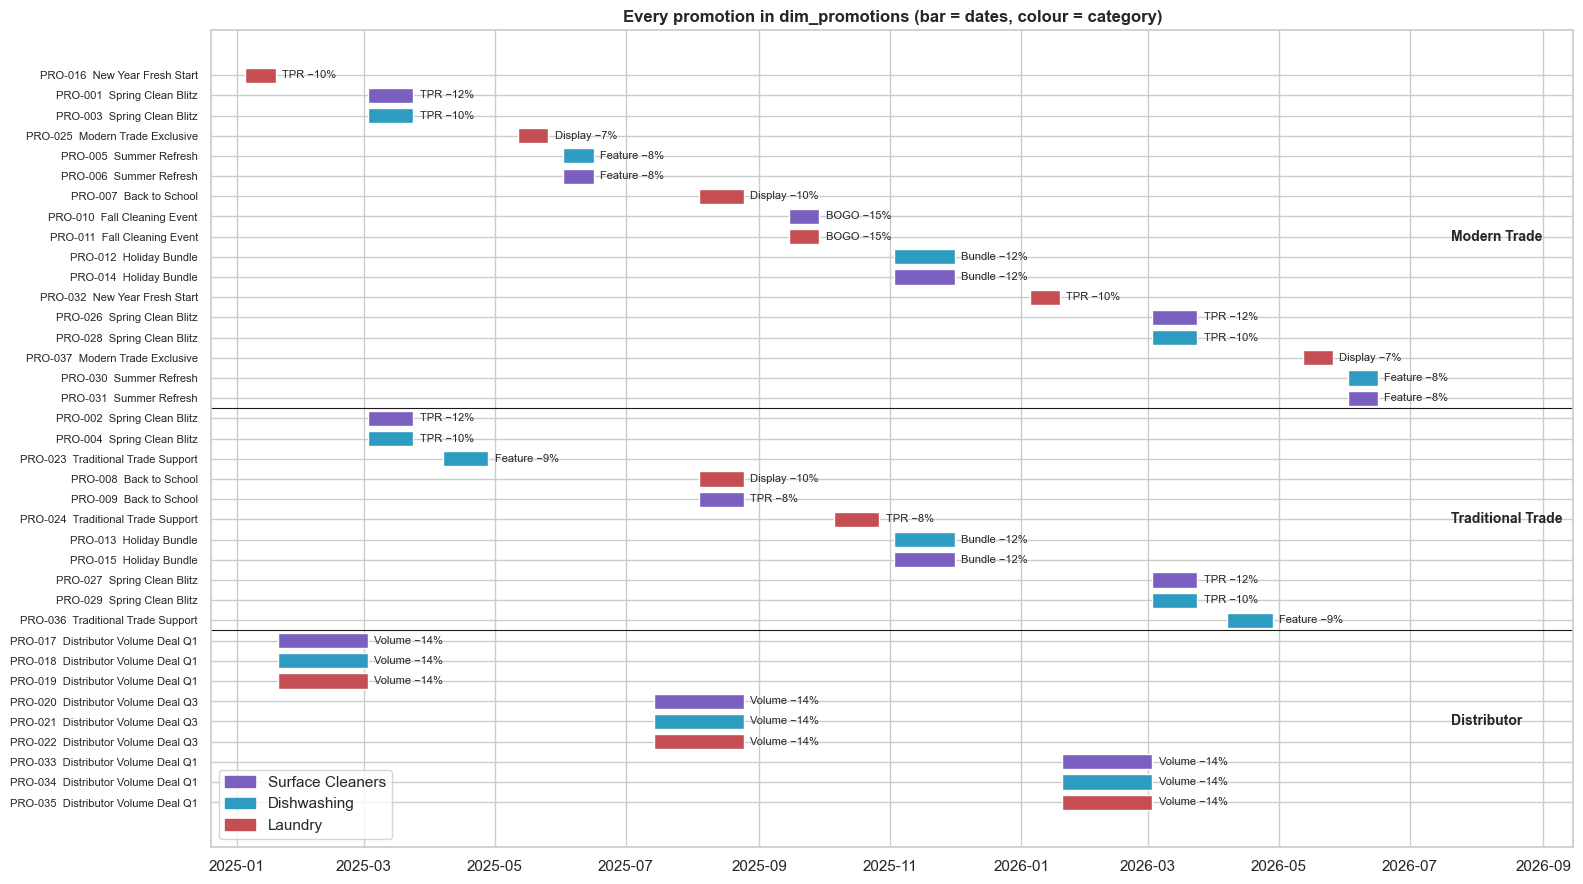

channel,Modern Trade,Traditional Trade,Distributor,discount_range,min_volume
promo_type,,,,,
BOGO,2,0,0,15–15%,80–80
Bundle,2,2,0,12–12%,50–50
Display,3,1,0,7–10%,60–60
Feature,4,2,0,8–9%,20–40
TPR,6,6,0,8–12%,20–50
Volume,0,0,9,14–14%,200–200


In [23]:
p = promos.assign(ch=pd.Categorical(promos.channel, CH_ORDER)).sort_values(['ch', 'start_date']).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(16, 9))
for i, r in p.iterrows():
    ax.barh(i, (r.end_date - r.start_date).days + 1, left=r.start_date, color=CAT_COL[r.category], height=0.75)
    ax.text(r.end_date + pd.Timedelta(days=4), i, f'{r.promo_type} −{r.discount_pct:.0f}%', va='center', fontsize=8)
ax.set_yticks(range(len(p))); ax.set_yticklabels(p.promo_id + '  ' + p.promo_name, fontsize=8); ax.invert_yaxis()
for b in p.index[p.ch != p.ch.shift()][1:]:
    ax.axhline(b - 0.5, color='k', lw=0.8)
for ch, grp in p.groupby('ch', observed=True):
    ax.text(pd.Timestamp('2026-07-20'), grp.index.to_numpy().mean(), ch, va='center', fontsize=10, fontweight='bold')
ax.set_xlim(pd.Timestamp('2024-12-20'), pd.Timestamp('2026-09-15'))
ax.legend(handles=[Patch(color=CAT_COL[c], label=c) for c in CAT_ORDER], loc='lower left')
ax.set_title('Every promotion in dim_promotions (bar = dates, colour = category)')
show('04_promo_calendar')
display(pd.crosstab(promos.promo_type, promos.channel)[CH_ORDER].assign(discount_range=promos.groupby('promo_type').discount_pct.agg(lambda s: f'{s.min():.0f}–{s.max():.0f}%'),
                                                                     min_volume=promos.groupby('promo_type').min_volume_units.agg(lambda s: f'{s.min()}–{s.max()}')))

**Notes:**
1. 37 promotions of 6 types. **Distributors only get "Volume" deals** (14% off, minimum 200 units), while Modern Trade gets the widest mix (TPR, Feature, Display, BOGO, Bundle). The table is identical to the first update.
2. The calendar repeats each year: New Year Fresh Start in January, Spring Clean Blitz in March, Summer Refresh in June, and so on. The second-half events (Back to School, Fall Cleaning, Holiday Bundle, the Q3 distributor deal) appear only once, because the data stops in June 2026.
3. Promos are timed with the seasons (spring cleaning in March, holidays in November), so we have to separate promo lift from seasonality (6.2 and 8.5).

### 4.7 Deliveries (rebuilt)

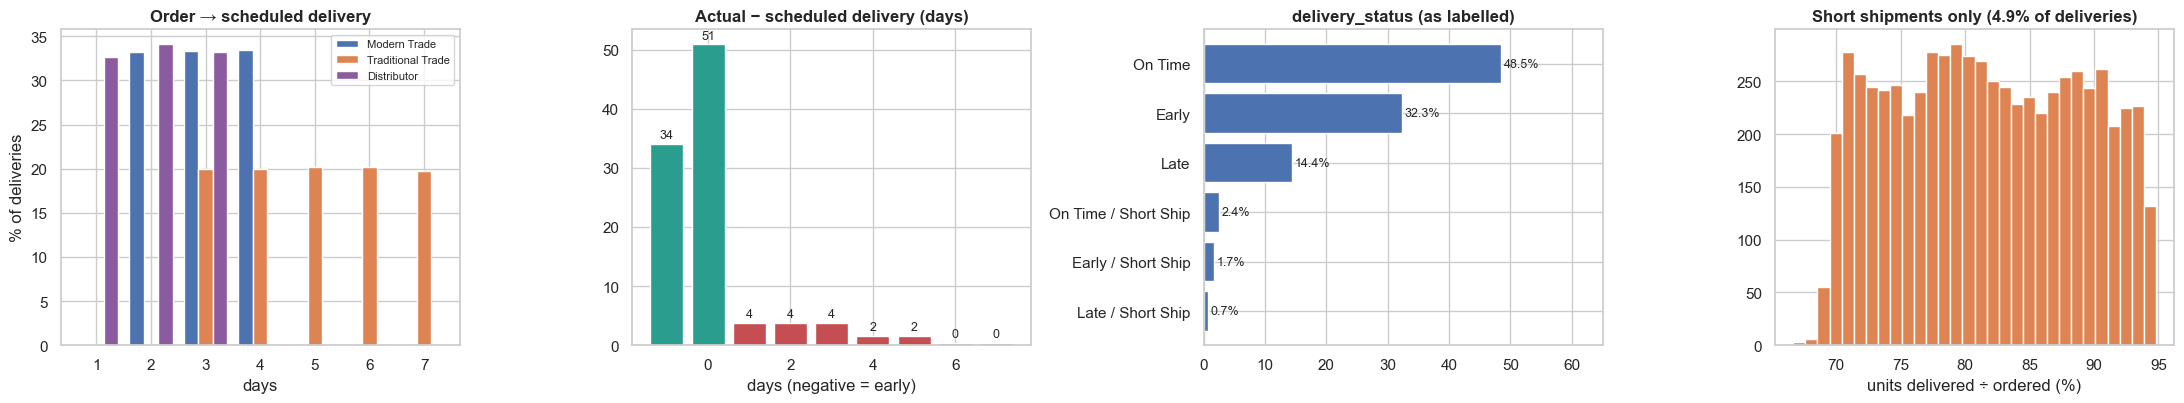

Overall fill rate (units delivered ÷ ordered): 99.1% | deliveries per store-SKU: 30.8 | orders per week: 1828


In [24]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.2))
lead = dv.groupby(['lead_scheduled', 'channel']).size().unstack()[CH_ORDER].fillna(0)
(lead / lead.sum() * 100).plot.bar(ax=axes[0], color=[CH_COL[c] for c in CH_ORDER], rot=0, width=0.8)
axes[0].set_title('Order → scheduled delivery'); axes[0].set_xlabel('days'); axes[0].set_ylabel('% of deliveries'); axes[0].legend(fontsize=8)
dvs = dv.days_vs_schedule.value_counts(normalize=True).sort_index() * 100
axes[1].bar(dvs.index, dvs.values, color=['#2A9D8F' if d <= 0 else '#C44E52' for d in dvs.index]); label_bars(axes[1], '{:.0f}')
axes[1].set_title('Actual − scheduled delivery (days)'); axes[1].set_xlabel('days (negative = early)')
st_share = dv.delivery_status.value_counts(normalize=True).sort_values() * 100
axes[2].barh(st_share.index, st_share.values, color='#4C72B0'); label_bars(axes[2], '{:.1f}%')
axes[2].set_title('delivery_status (as labelled)'); axes[2].set_xlim(0, 65)
short = dv[dv.units_delivered < dv.units_ordered]
axes[3].hist(short.units_delivered / short.units_ordered * 100, bins=30, color='#DD8452')
axes[3].set_title(f'Short shipments only ({len(short) / len(dv):.1%} of deliveries)'); axes[3].set_xlabel('units delivered ÷ ordered (%)')
show('04_deliveries')
print(f"Overall fill rate (units delivered ÷ ordered): {dv.units_delivered.sum() / dv.units_ordered.sum():.1%} | "
      f"deliveries per store-SKU: {len(dv) / len(assortment):.1f} | orders per week: {len(dv) / dv.order_date.nunique() * 7:.0f}")

**Notes:**
1. Each channel has a fixed planned lead time between the order and the scheduled delivery, spread evenly: **Distributors 1–3 days, Modern Trade 2–4, Traditional Trade 3–7**.
2. By the dates, **34% arrive a day early, 51% on the day and 15% are 1–7 days late**, and the `delivery_status` labels now say the same thing. Traditional Trade is the least punctual: 24% of its deliveries are late, against 12% for Modern Trade and 7% for Distributors.
3. Only **4.9%** of deliveries are short, and when they are, usually 70–95% of the units still arrive. The overall fill rate is **99.1%**, so short shipments are not a big source of lost units.
4. About 1,800 deliveries are ordered per week, 31 per store-SKU over the 17 months.

### 4.8 Audit metrics
The audits changed in the latest data (shelf shares are normalised and the rows for store-SKU pairs that don't exist were removed), so unlike before we look at them again. How they relate to sales is checked in 5.5 and 8.7.

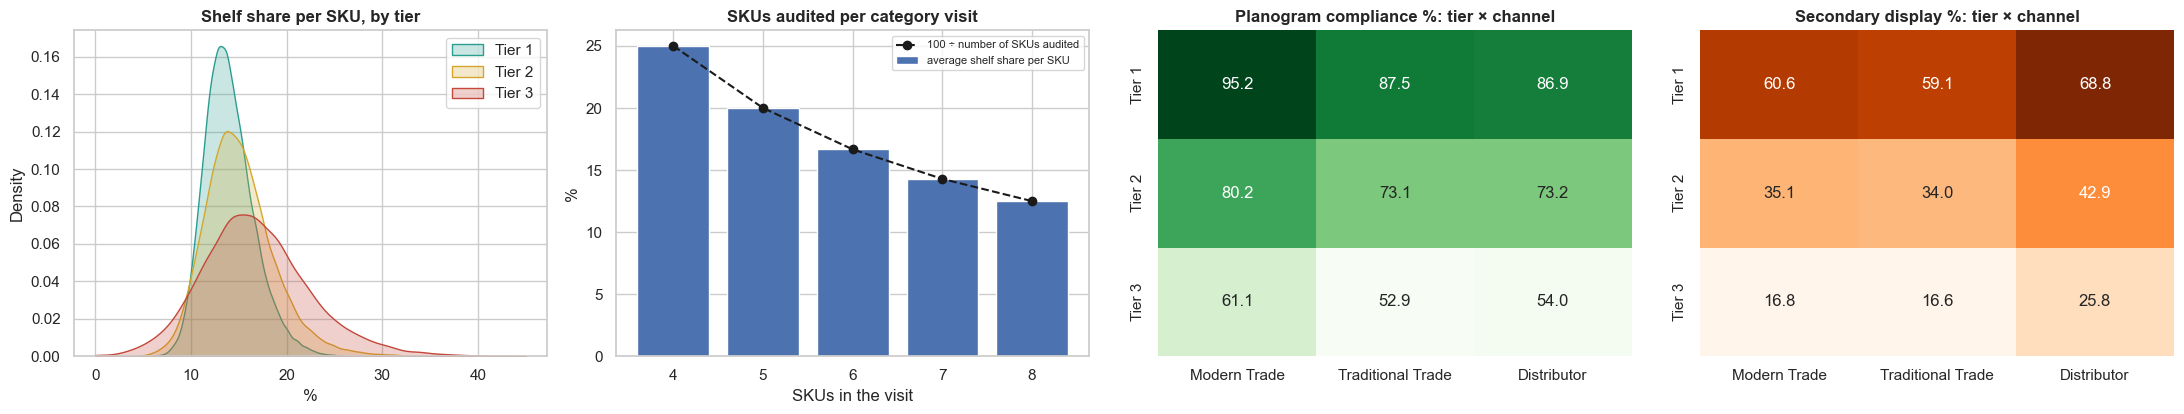

Shelf share summed within a category visit: v3 min 99.98, max 100.03 (28,818 visits) | v1 average 239%
Average shelf share per SKU: v3 14.6% (v1 35.2%) | planogram compliant: v3 83.0% (v1 83.1%) | secondary display: v3 49.0% (v1 44.3%)


channel,Modern Trade,Traditional Trade,Distributor
segment_tier,,,
Tier 1,14.08,14.23,13.47
Tier 2,14.85,15.23,15.47
Tier 3,16.75,16.81,16.85


In [25]:
visit = au.groupby(['store_id', 'date', 'category']).agg(n_skus=('sku_id', 'size'), share_sum=('shelf_share_pct', 'sum'), share_mean=('shelf_share_pct', 'mean'))
a1 = v1['fact_execution_audits']
s1 = a1.assign(category=a1.sku_id.map(cat_of)).groupby(['store_id', 'date', 'category']).shelf_share_pct.sum()
fig, axes = plt.subplots(1, 4, figsize=(22, 4.3))
for t in TIER_ORDER:
    sns.kdeplot(au.loc[au.segment_tier == t, 'shelf_share_pct'], ax=axes[0], color=TIER_COL[t], label=t, fill=True, alpha=0.25, clip=(0, 45))
axes[0].set_title('Shelf share per SKU, by tier'); axes[0].set_xlabel('%'); axes[0].legend()
bn = visit.groupby('n_skus').share_mean.mean()
axes[1].bar(bn.index, bn.values, color='#4C72B0', label='average shelf share per SKU')
axes[1].plot(bn.index, 100 / bn.index, 'k--', marker='o', label='100 ÷ number of SKUs audited')
axes[1].set_title('SKUs audited per category visit'); axes[1].set_xlabel('SKUs in the visit'); axes[1].set_ylabel('%'); axes[1].legend(fontsize=8)
for ax, col, title, cmap in [(axes[2], 'planogram_compliance', 'Planogram compliance %: tier × channel', 'Greens'), (axes[3], 'secondary_display', 'Secondary display %: tier × channel', 'Oranges')]:
    heatmap(au.pivot_table(index='segment_tier', columns='channel', values=col, aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER] * 100,
            annot=True, fmt='.1f', cmap=cmap, ax=ax, cbar=False); ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('')
show('04_audits')
print(f"Shelf share summed within a category visit: v3 min {visit.share_sum.min():.2f}, max {visit.share_sum.max():.2f} ({len(visit):,} visits) | v1 average {s1.mean():.0f}%")
print(f"Average shelf share per SKU: v3 {au.shelf_share_pct.mean():.1f}% (v1 {a1.shelf_share_pct.mean():.1f}%) | planogram compliant: v3 {au.planogram_compliance.mean():.1%} "
      f"(v1 {a1.planogram_compliance.mean():.1%}) | secondary display: v3 {au.secondary_display.mean():.1%} (v1 {a1.secondary_display.mean():.1%})")
display(au.pivot_table(index='segment_tier', columns='channel', values='shelf_share_pct', aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER].round(2))
del visit, s1

**Notes:**
1. **Shelf share per SKU now averages 14.6%** (v1: 35.2%). It's normalised so the SKUs of a category visit **sum to 100%** (28,818 visits; in v1 they added up to 239% on average). Since a visit covers 4 to 8 SKUs, a SKU's share is simply about 100 ÷ the number of SKUs audited (the dashed line), which is why small Tier 3 stores, with fewer SKUs per category, show a *higher* share per SKU (16.8% in every channel) than Tier 1 (13.5–14.2%).
2. That changes what the KPI means: it is now a split **among Marvel's own SKUs**, not Marvel against competitors, and at category level it is always 100% (see the questions in section 10).
3. Planogram compliance is almost unchanged (83.0% vs 83.1% in v1) and keeps its tier pattern (Tier 1 87–95%, Tier 3 53–61%).
4. **Secondary display is up** (49.0% vs 44.3% in v1) and now follows the tier clearly: Tier 1 59–69%, Tier 2 34–43%, Tier 3 17–26%.

## 5. Bivariate and multivariate analysis

### 5.1 Store performance by channel, tier and region
Each dot is one store. Top row: average units per SKU per recorded day (as in v1). Bottom row is new, because OOS behaves very differently in v3: the store's OOS rate.

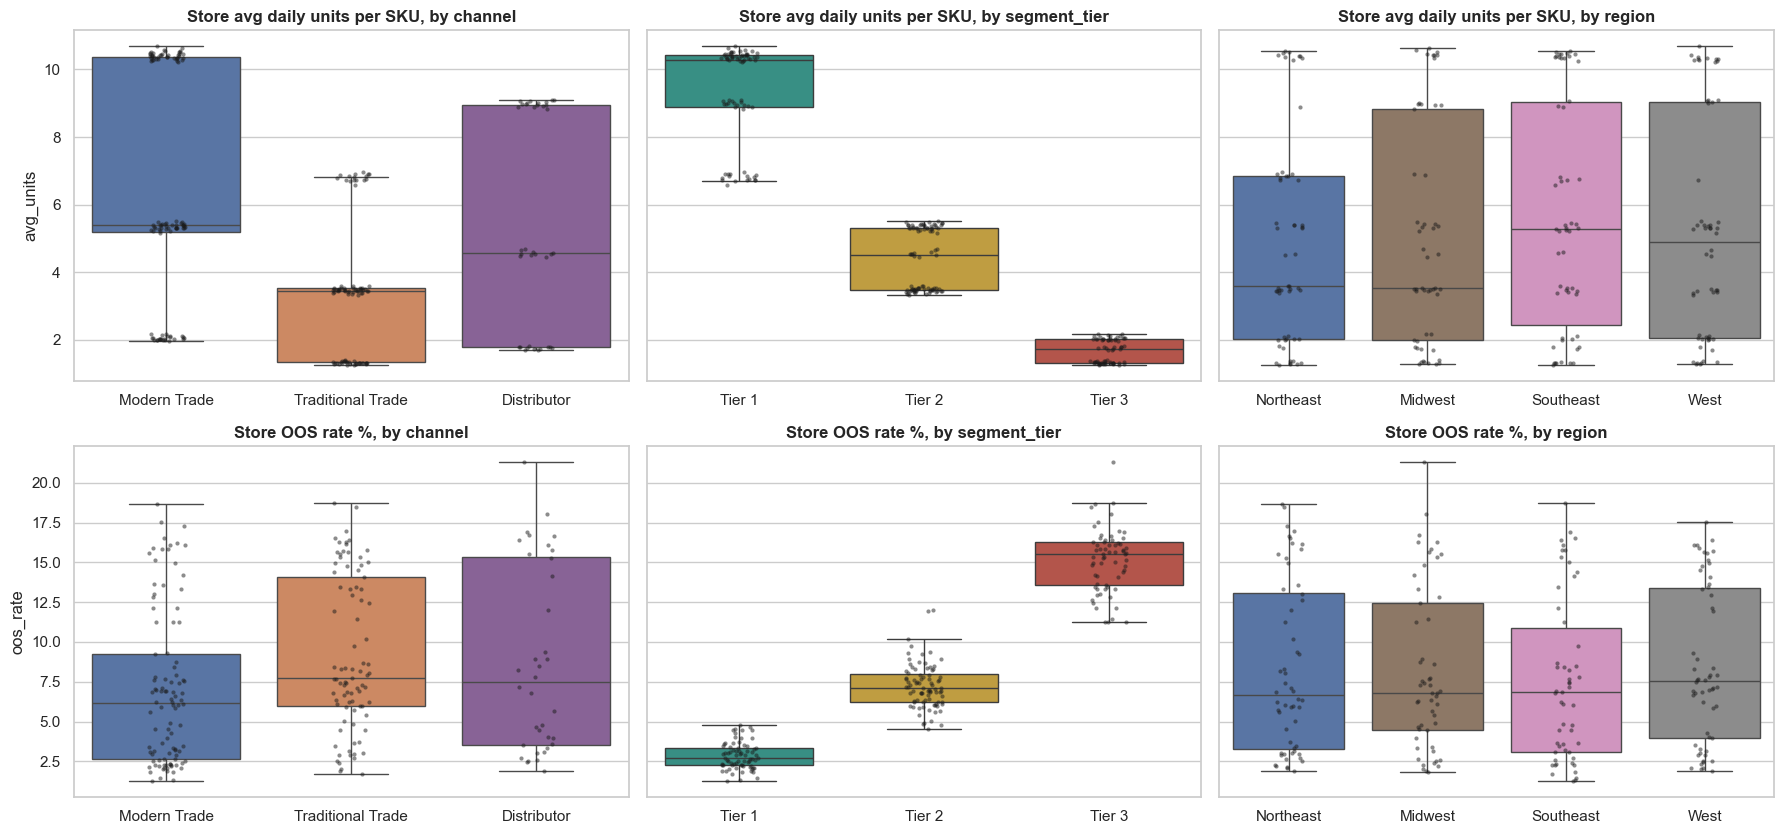

avg_units                                   oos_rate                               
channel      Distributor Modern Trade Traditional Trade Distributor Modern Trade Traditional Trade
segment_tier                                                                                      
Tier 1              8.99        10.40              6.80        3.36         2.39              2.92
Tier 2              4.54         5.34              3.47        8.35         6.93              7.27
Tier 3              1.74         2.04              1.32       16.42        15.07             15.18

In [26]:
store_perf = (sof.groupby('store_id').agg(avg_units=('units_sold_daily', 'mean'), sales_value=('sales_value', 'sum'),
                                         oos_rate=('is_out_of_stock', 'mean'))
                 .join(stores.set_index('store_id')).reset_index())
store_perf['oos_rate'] *= 100
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5), sharey='row')
for j, (col, order, pal) in enumerate(zip(['channel', 'segment_tier', 'region'], [CH_ORDER, TIER_ORDER, REGION_ORDER], [CH_COL, TIER_COL, REG_COL])):
    for i, (metric, lbl) in enumerate([('avg_units', 'avg daily units per SKU'), ('oos_rate', 'OOS rate %')]):
        ax = axes[i, j]
        sns.boxplot(data=store_perf, x=col, y=metric, order=order, hue=col, palette=pal, legend=False, ax=ax, showfliers=False)
        sns.stripplot(data=store_perf, x=col, y=metric, order=order, color='k', size=3, alpha=0.5, ax=ax)
        ax.set_title(f'Store {lbl}, by {col}'); ax.set_xlabel('')
show('05_store_performance')
store_perf.pivot_table(index='segment_tier', columns='channel', values=['avg_units', 'oos_rate'], aggfunc='median').round(2)

**Notes:**
1. Sales look like v1: tier is the strongest split (the median Tier 1 store sells ~10.3 units per SKU per day vs ~1.7 for Tier 3, about 6×), and stores still stack up at a few levels, one per tier × channel.
2. **OOS follows the tier, not the channel.** The store medians are 2.4–3.4% in Tier 1, 6.9–8.4% in Tier 2 and 15.1–16.4% in Tier 3, almost the same in every channel. (In the first update Traditional Trade stood out at 25% in Tier 3; that is gone.) The bottom row is basically the top row upside down: the smaller the store, the more it runs out.
3. Region still barely matters; the dots look the same in all four regions.
### 5.2 Where the money comes from
Now valued at what consumers actually paid.

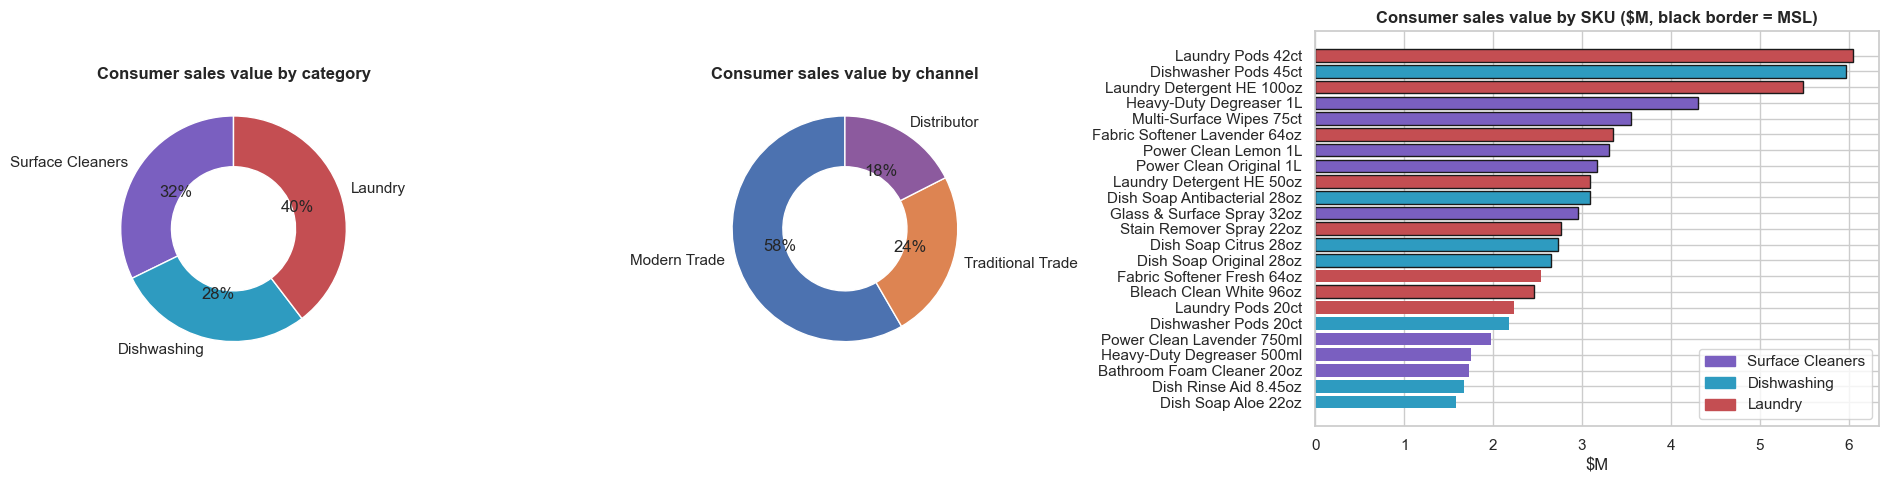

Total consumer sales value: $70.6M | MSL SKUs: 78% | sold on promo: 18% of value, 21% of units


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={'width_ratios': [1, 1, 2]})
for ax, col, order, pal in zip(axes[:2], ['category', 'channel'], [CAT_ORDER, CH_ORDER], [CAT_COL, CH_COL]):
    share = sof.groupby(col).sales_value.sum().reindex(order)
    ax.pie(share, labels=share.index, autopct='%1.0f%%', colors=[pal[x] for x in share.index],
           wedgeprops=dict(width=0.45, edgecolor='w'), startangle=90)
    ax.set_title(f'Consumer sales value by {col}')
sku_val = sof.groupby(['sku_id', 'product_name', 'category', 'is_msl']).sales_value.sum().reset_index().sort_values('sales_value')
axes[2].barh(sku_val.product_name.str.replace('Marvel ', ''), sku_val.sales_value / 1e6,
             color=[CAT_COL[c] for c in sku_val.category], edgecolor=['k' if m else 'none' for m in sku_val.is_msl])
axes[2].set_title('Consumer sales value by SKU ($M, black border = MSL)'); axes[2].set_xlabel('$M')
axes[2].legend(handles=[Patch(color=CAT_COL[c], label=c) for c in CAT_ORDER], loc='lower right')
show('05_sales_value')
msl_share = sof.groupby('is_msl').sales_value.sum()
print(f"Total consumer sales value: ${sof.sales_value.sum() / 1e6:.1f}M | MSL SKUs: {msl_share[True] / msl_share.sum():.0%} "
      f"| sold on promo: {sof.loc[sof.on_promo, 'sales_value'].sum() / sof.sales_value.sum():.0%} of value, {sof.loc[sof.on_promo, 'units_sold_daily'].sum() / sof.units_sold_daily.sum():.0%} of units")

**Notes:** Consumer sales value is **$70.6M** over the 17 months (Jan 2025 – May 2026). The mix is close to v1: Laundry is the biggest category (40%), Modern Trade brings in 58%, and the 15 MSL SKUs make up 78% of value. The top SKUs are still the big packs (Laundry Pods 42ct, Dishwasher Pods 45ct, Laundry Detergent HE 100oz). **18% of value (21% of units) is sold on promotion.**
### 5.3 How concentrated are sales? (Pareto)
In v1 this was a bar chart with a second y-axis. Here we plot only the cumulative curve (one axis is easier to read): x = share of stores (or SKUs), biggest first; y = share of sales value.

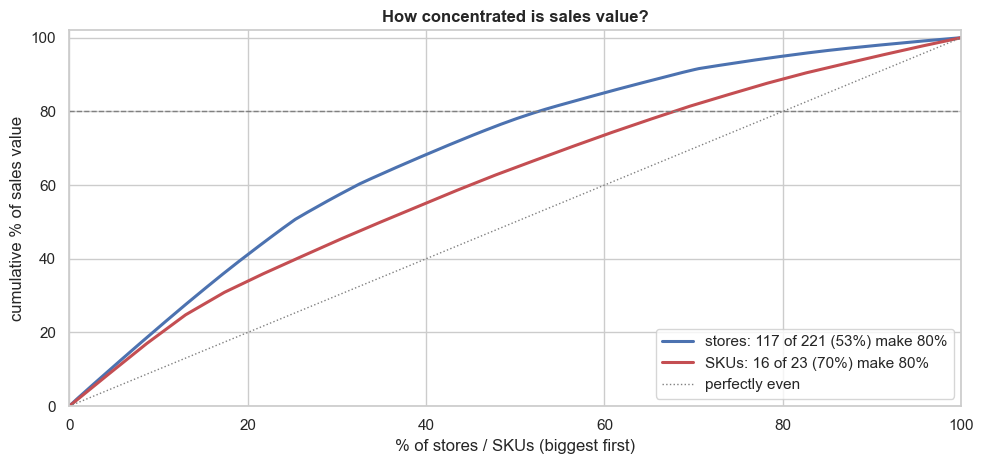

In [28]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for key_col, label, color in [('store_id', 'stores', '#4C72B0'), ('sku_id', 'SKUs', '#C44E52')]:
    s = sof.groupby(key_col).sales_value.sum().sort_values(ascending=False)
    cum = s.cumsum() / s.sum() * 100
    n80 = int((cum < 80).sum() + 1)
    x = np.arange(1, len(s) + 1) / len(s) * 100
    ax.plot(np.r_[0, x], np.r_[0, cum.values], color=color, lw=2.2, label=f'{label}: {n80} of {len(s)} ({n80 / len(s):.0%}) make 80%')
ax.plot([0, 100], [0, 100], color='grey', ls=':', lw=1, label='perfectly even')
ax.axhline(80, color='grey', ls='--', lw=1)
ax.set_xlabel('% of stores / SKUs (biggest first)'); ax.set_ylabel('cumulative % of sales value'); ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_title('How concentrated is sales value?'); ax.legend(loc='lower right')
show('05_pareto')

**Notes:** Still no 80/20: it takes **117 of 221 stores (53%)** and 16 of the 23 SKUs to make 80% of the value (v1: 121 stores and 16 SKUs). So the store visit ranking can't just focus on a few big stores, especially since the stock-outs are in the small ones (5.1).
### 5.4 Geography

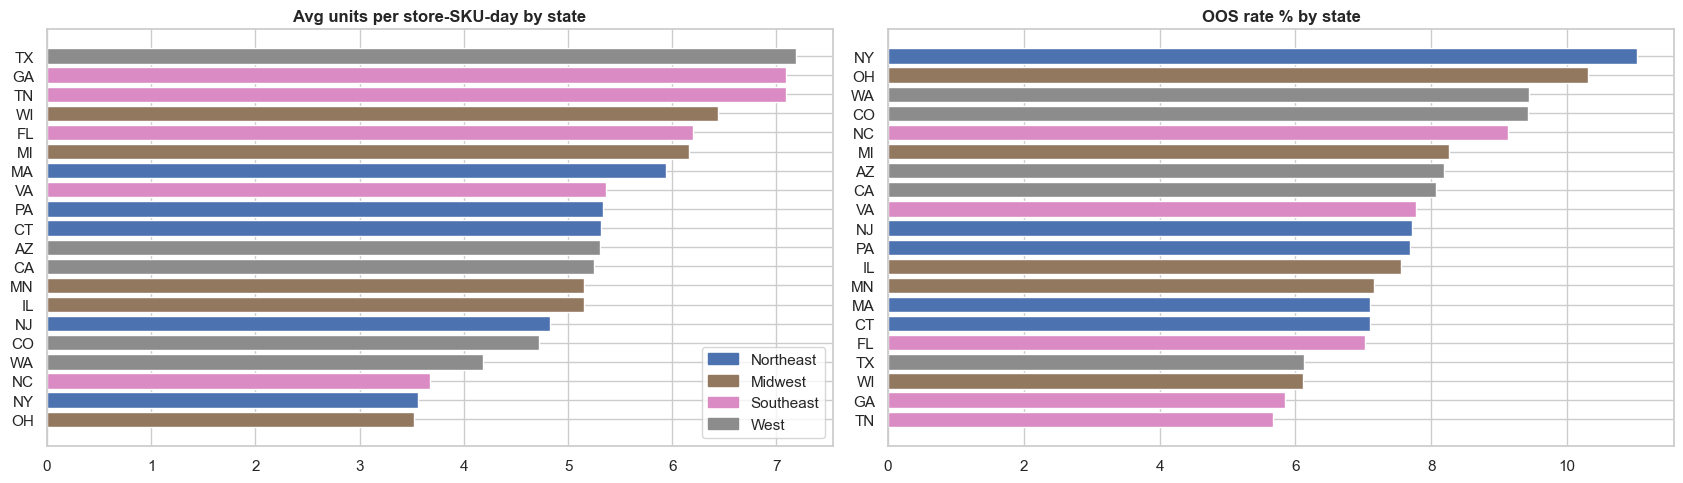

Correlation across states, OOS rate vs share of Tier 3 stores: 0.82


In [29]:
st = (sof.groupby(['state', 'region']).agg(avg_units=('units_sold_daily', 'mean'), oos_rate=('is_out_of_stock', 'mean')).reset_index()
         .merge(stores.groupby('state').segment_tier.apply(lambda s: (s == 'Tier 3').mean() * 100).rename('tier3_share'), on='state'))
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for ax, col, title, mult in [(axes[0], 'avg_units', 'Avg units per store-SKU-day by state', 1),
                             (axes[1], 'oos_rate', 'OOS rate % by state', 100)]:
    d = st.sort_values(col)
    ax.barh(d.state, d[col] * mult, color=[REG_COL[r] for r in d.region])
    ax.set_title(title)
axes[0].legend(handles=[Patch(color=REG_COL[r], label=r) for r in REGION_ORDER], loc='lower right')
show('05_geography')
print('Correlation across states, OOS rate vs share of Tier 3 stores:', round(st.oos_rate.corr(st.tier3_share), 2))

**Notes:** Units by state look like v1. OOS by state ranges from 5.7% to 11.0% and follows how many Tier 3 stores each state has (correlation **0.82**), not anything regional. So a map would mostly show the tier mix again.
### 5.5 Correlations (store-SKU level)
Same idea as v1 (one row per store-SKU pair), with the new variables added: how often the pair is on promo, the average invoice discount, and delivery delay and fill rate.

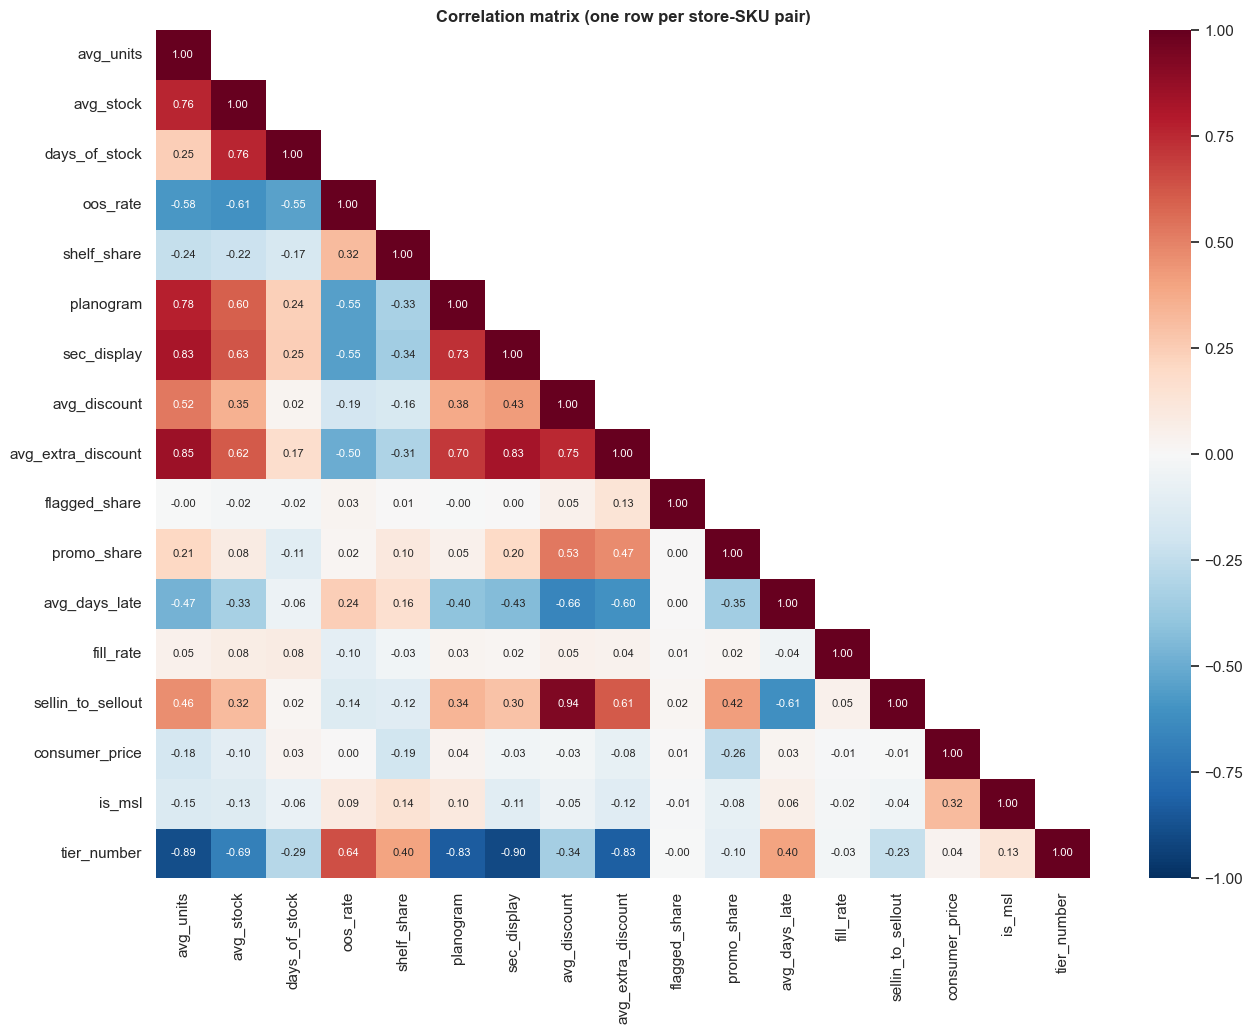

In [30]:
k = ['store_id', 'sku_id']
pair = (so.assign(on_promo=so.promo_id.notna())
          .groupby(k).agg(avg_units=('units_sold_daily', 'mean'), avg_stock=('inventory_level', 'mean'),
                          oos_rate=('is_out_of_stock', 'mean'), total_units=('units_sold_daily', 'sum'), promo_share=('on_promo', 'mean'))
          .join(si.groupby(k).agg(avg_discount=('discount_pct', 'mean'), avg_extra_discount=('extra_discount_pct', 'mean'),
                                  flagged_share=('guardrail_violation', 'mean'), sellin_units=('units_sold', 'sum')))
          .join(audits.groupby(k).agg(shelf_share=('shelf_share_pct', 'mean'), planogram=('planogram_compliance', 'mean'),
                                      sec_display=('secondary_display', 'mean')))
          .join(dv.groupby(k).agg(avg_days_late=('delay_days', 'mean'), fill_rate=('fill_rate_pct', 'mean')))
          .reset_index().merge(stores[['store_id', 'segment_tier']], on='store_id')
          .merge(products[['sku_id', 'consumer_price', 'is_msl']], on='sku_id'))
pair['days_of_stock'] = pair.avg_stock / pair.avg_units
pair['sellin_to_sellout'] = pair.sellin_units / pair.total_units
pair['tier_number'] = pair.segment_tier.str[-1].astype(int)
pair['is_msl'] = pair.is_msl.astype(int)
cols = ['avg_units', 'avg_stock', 'days_of_stock', 'oos_rate', 'shelf_share', 'planogram', 'sec_display', 'avg_discount', 'avg_extra_discount',
        'flagged_share', 'promo_share', 'avg_days_late', 'fill_rate', 'sellin_to_sellout', 'consumer_price', 'is_msl', 'tier_number']
corr = pair[cols].corr()
fig, ax = plt.subplots(figsize=(13.5, 10.5))
heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), 1), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlation matrix (one row per store-SKU pair)')
show('05_correlations')

**Notes**
1. **OOS follows store size:** `tier_number` correlates **+0.64** with the OOS rate (v1: +0.27) and average sales −0.58. Days of stock left is the other strong driver (−0.55).
2. **The extra discount follows the account:** it correlates +0.85 with sales volume and −0.83 with tier, while the *total* discount follows the tier much less (−0.34), because the standard part is fixed per channel × category.
3. **`guardrail_violation` is related to almost nothing** (+0.13 with the extra discount, 0.00 with tier): the flag doesn't favour any kind of store (8.4).
4. `avg_days_late` correlates +0.24 with OOS, but also +0.40 with tier. In 8.6 we check whether the link is real or just tier.
5. Shelf share per SKU correlates +0.40 with tier and −0.24 with sales: that is an effect of the normalisation (fewer SKUs per visit in small stores, 4.8), not of execution. Planogram and secondary display move with tier (−0.83 and −0.90), and display moves with sales (+0.83).

## 6. Time series analysis
Missing days are down to ~8% but still random, so we keep the v1 approach: **average units per recorded store-SKU-day**, not raw totals.

### 6.1 Overall trend

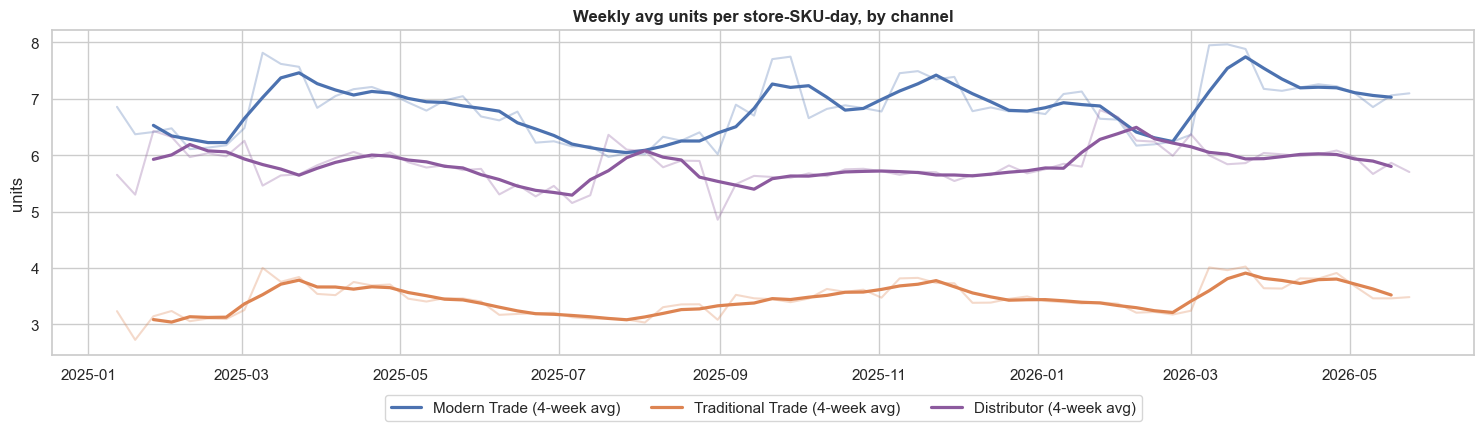

In [31]:
wk = sof.groupby([pd.Grouper(key='date', freq='W'), 'channel']).units_sold_daily.mean().unstack()[CH_ORDER].iloc[1:-1]
fig, ax = plt.subplots(figsize=(15, 4.5))
for ch in CH_ORDER:
    ax.plot(wk.index, wk[ch], color=CH_COL[ch], alpha=0.3)
    ax.plot(wk.index, wk[ch].rolling(4, center=True).mean(), color=CH_COL[ch], lw=2.3, label=f'{ch} (4-week avg)')
ax.set_title('Weekly avg units per store-SKU-day, by channel'); ax.set_ylabel('units')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
show('06_weekly_trend')

**Notes:** Still no long-term growth: 2026 repeats 2025. Modern Trade jumps in **March** and again in **September–November**, lining up with the Spring Clean Blitz, the Fall Cleaning Event and the Holiday Bundle. Distributors get bumps in **February** and **July–August**, their volume deals. So the promotions are visible in the overall trend.
### 6.2 Monthly seasonality by category
New problem in v3: promotions are timed with the seasons (e.g. "Spring Clean Blitz" in March), so a seasonal peak could partly be promo lift. To separate the two we computed the index twice: on all days, and on **non-promo days only**. Because promos cover whole channels, the non-promo days in a promo month come from other channels, so we first divide each store-SKU's sales by its own average (otherwise the mix of channels would distort the index).

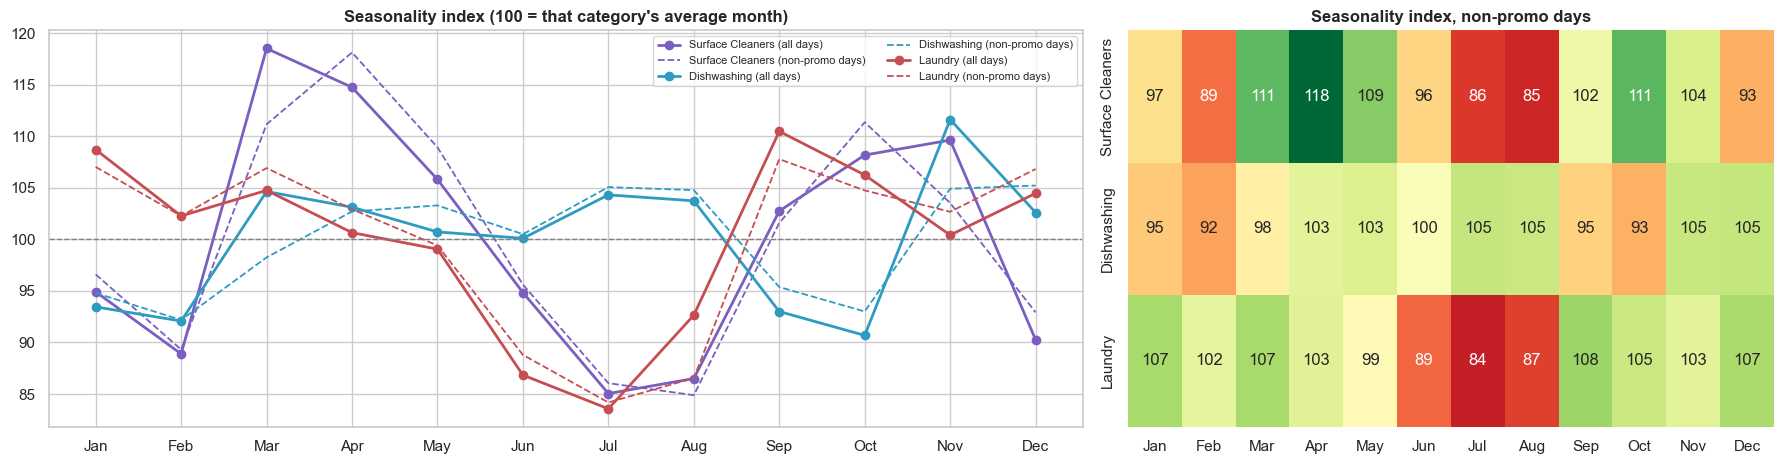

In [32]:
sof['rel_units'] = sof.units_sold_daily / sof.groupby(['store_id', 'sku_id']).units_sold_daily.transform('mean')
def season_index(frame):
    m = frame.groupby([frame.date.dt.month, 'category']).rel_units.mean().unstack()[CAT_ORDER]
    return m / m.mean() * 100
cat_index, cat_index_np = season_index(sof), season_index(sof[~sof.on_promo])
fig, axes = plt.subplots(1, 2, figsize=(18, 4.8), gridspec_kw={'width_ratios': [1.6, 1]})
for c in CAT_ORDER:
    axes[0].plot(range(1, 13), cat_index[c], marker='o', color=CAT_COL[c], label=f'{c} (all days)', lw=2)
    axes[0].plot(range(1, 13), cat_index_np[c], ls='--', color=CAT_COL[c], lw=1.3, label=f'{c} (non-promo days)')
axes[0].axhline(100, color='grey', ls='--', lw=1)
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels(MONTHS)
axes[0].set_title("Seasonality index (100 = that category's average month)"); axes[0].legend(fontsize=8, ncol=2)
heatmap(cat_index_np.T.set_axis(MONTHS, axis=1), annot=True, fmt='.0f', cmap='RdYlGn', center=100, ax=axes[1], cbar=False)
axes[1].set_title('Seasonality index, non-promo days'); axes[1].set_xlabel(''); axes[1].set_ylabel('')
show('06_seasonality')

**Notes:** The v1 seasonality is still there, and it's mostly *not* promo-driven (the dashed non-promo lines stay close to the solid ones):
1. **Surface Cleaners** peak in March–April (111 and 118 on non-promo days) and dip in July–August (~85). The Spring Clean Blitz adds a few points on top in March (119 on all days vs 111 without promos).
2. **Laundry** is high in January (107) and September (108), and lowest in July (84).
3. **Dishwashing** is the steadiest (92–105), with a high in November–December. The Holiday Bundle adds about 7 points in November (112 vs 105).

So for the perfect order we need **both** a month factor and a promo factor.
### 6.3 Seasonal decomposition (daily)

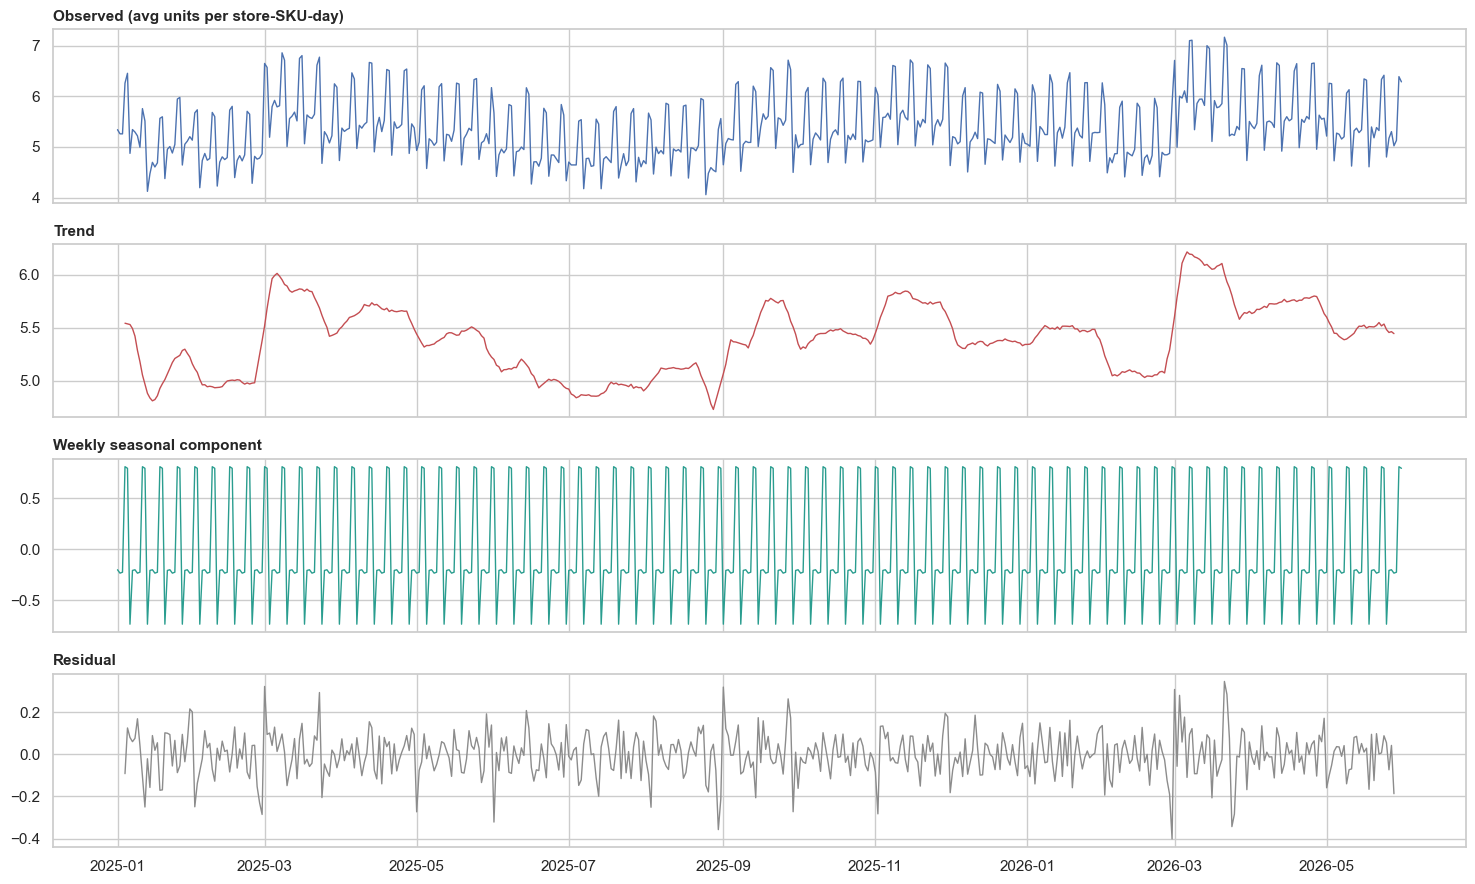

Avg day-to-day change (weekday-adjusted): on the 1st of a month 0.35 units | on all other days 0.10 units   (v1 found jumps on the 1st)


In [33]:
daily = sof.groupby('date').units_sold_daily.mean().asfreq('D')
dec = weekly_decompose(daily)
fig, axes = plt.subplots(4, 1, figsize=(15, 9), sharex=True)
for ax, series, title, color in zip(axes, [dec.observed, dec.trend, dec.seasonal, dec.resid],
                                    ['Observed (avg units per store-SKU-day)', 'Trend', 'Weekly seasonal component', 'Residual'],
                                    ['#4C72B0', '#C44E52', '#2A9D8F', '#8C8C8C']):
    ax.plot(series.index, series.values, color=color, lw=1)
    ax.set_title(title, fontsize=11, loc='left')
show('06_decomposition')
step = (dec.observed - dec.seasonal).diff().abs()      # day-to-day change after removing the weekday effect
print(f"Avg day-to-day change (weekday-adjusted): on the 1st of a month {step[step.index.day == 1].mean():.2f} units "
      f"| on all other days {step[step.index.day != 1].mean():.2f} units   (v1 found jumps on the 1st)")

**Notes:** Same as v1: the trend has the yearly wave, the weekly pattern is clean, and the residual is small. The trend still moves in **steps on the 1st of each month**: the weekday-adjusted daily average changes by 0.35 units on the 1st vs 0.10 on other days. So the simulation still uses one multiplier per month, and a month factor plus a weekday factor should capture most of the seasonality.
### 6.4 Day-of-week effect

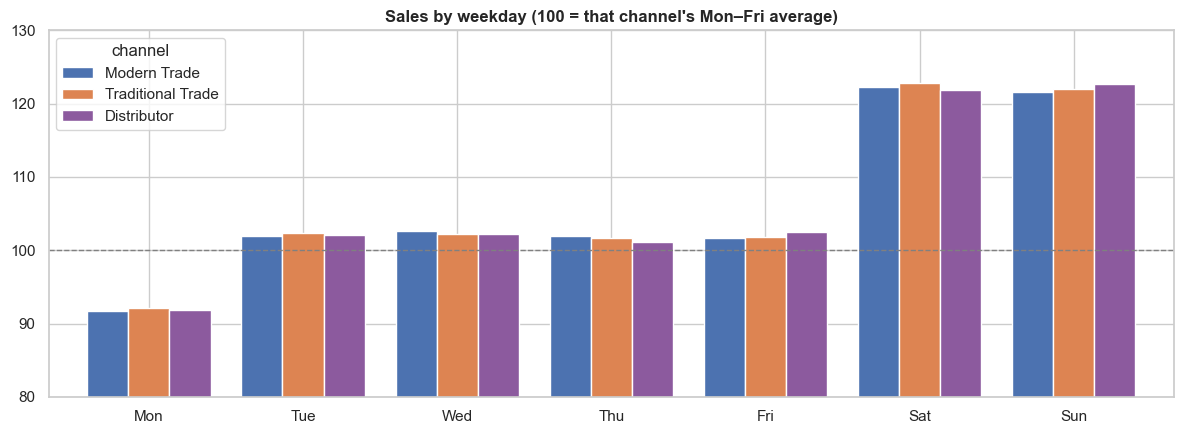

Weekend vs weekday: +22%   (v1: +23%)


In [34]:
dow_ch = sof.groupby(['channel', sof.date.dt.dayofweek]).units_sold_daily.mean().unstack(0)[CH_ORDER]
dow_idx = dow_ch / dow_ch.iloc[:5].mean() * 100
fig, ax = plt.subplots(figsize=(12, 4.5))
dow_idx.set_axis(DAYS).plot.bar(ax=ax, color=[CH_COL[c] for c in CH_ORDER], rot=0, width=0.8)
ax.axhline(100, color='grey', ls='--', lw=1); ax.set_ylim(80, 130)
ax.set_title("Sales by weekday (100 = that channel's Mon–Fri average)"); ax.set_xlabel('')
show('06_weekday')
dow_all = sof.groupby(sof.date.dt.dayofweek).units_sold_daily.mean()
print(f"Weekend vs weekday: {dow_all[[5, 6]].mean() / dow_all[:5].mean() - 1:+.0%}   (v1: +23%)")

**Notes:** Weekends still sell about **22% more** than weekdays (v1: +23%), in every channel, and Monday is still the slowest day.
### 6.5 Year-over-year (Jan–May 2025 vs 2026)

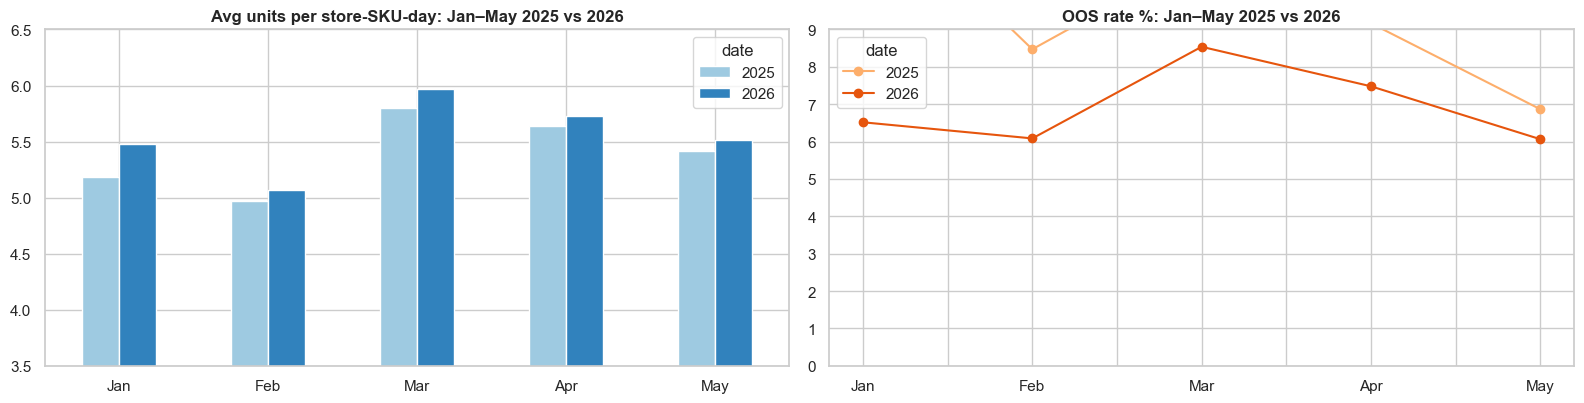

units          oos      
date  2025  2026   2025  2026
date                         
1     5.18  5.48  12.84  6.52
2     4.97  5.07   8.47  6.08
3     5.80  5.97  10.97  8.54
4     5.64  5.73   9.17  7.48
5     5.41  5.51   6.87  6.06

In [35]:
h1 = sof[sof.date.dt.month <= 5]
yoy = h1.groupby([h1.date.dt.month, h1.date.dt.year]).agg(units=('units_sold_daily', 'mean'), oos=('is_out_of_stock', 'mean')).unstack()
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
yoy['units'].set_axis(MONTHS[:5]).plot.bar(ax=axes[0], rot=0, color=['#9ecae1', '#3182bd'])
axes[0].set_title('Avg units per store-SKU-day: Jan–May 2025 vs 2026'); axes[0].set_xlabel(''); axes[0].set_ylim(3.5, 6.5)
(yoy['oos'] * 100).set_axis(MONTHS[:5]).plot(ax=axes[1], marker='o', color=['#fdae6b', '#e6550d'])
axes[1].set_title('OOS rate %: Jan–May 2025 vs 2026'); axes[1].set_ylim(0, 9); axes[1].set_xlabel('')
show('06_yoy')
display((yoy * [1, 1, 100, 100]).round(2))

**Notes:**
1. **The first months of 2025 are a warm-up for stock-outs, and the change list says this is intentional.** OOS is 12.8% in January 2025 (vs 6.5% in January 2026), and it comes down slowly: 8.5% in February, 11.0% in March, 9.2% in April and 6.9% in May 2025, while the same months of 2026 stay at 6.1–8.5%. (In the first update it was the other way round: January 2025 was *lower*.) The excess is largest in the small stores (Tier 3: 23% in January 2025 vs 15% afterwards).
2. Sales are about **2–6% higher in 2026** than in 2025 in every month, a small growth that wasn't there in v1.
3. For model training we still have to decide how much of early 2025 to drop; that belongs in the modelling notebook.

## 7. The brief's KPIs (baseline values)
In v1 we had to invent our own KPI definitions and asked Dr. Masse to confirm them. He answered (Q10, Q13, Q15, Q17), so this section uses the **official** definitions.

### 7.1 Definitions we used (from the Q&A)

| KPI | Official definition (Q10) | How we computed it |
|---|---|---|
| OOS rate % | OOS store-SKU-days ÷ all store-SKU-days | reported days only (missing days are random, so this is unbiased) |
| MSL compliance % | stores where **every** MSL SKU has stock > 0 ÷ stores | per store-day, then averaged over days |
| Sell-in vs sell-out gap % | (sell-in units − sell-out units) ÷ sell-out units | both over the **same window** (Q13); we use whole invoice weeks |
| Shelf share % | average `shelf_share_pct` | audits |
| Planogram compliance % | compliant audit rows ÷ audit rows | audits (a different thing from MSL, Q15) |

Distributors are wholesale accounts (Q17), so we show them on their own row and also give a **Retail (MT + TT)** total.

### 7.2 KPI scorecard

In [36]:
msl_ids = set(products.loc[products.is_msl, 'sku_id'])
def msl_store_days(frame):
    m = frame[frame.sku_id.isin(msl_ids)].groupby(['store_id', 'date']).inventory_level.min().gt(0)
    return m.rename('msl_compliant').reset_index().merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
msl_sd = msl_store_days(sof)

def kpi_table(key, S, I, A, M, gap_end):
    S_gap = S[S.date <= gap_end]               # sell-in and sell-out are compared over the same weeks
    return pd.DataFrame({
        'OOS rate %': S.groupby(key(S)).is_out_of_stock.mean() * 100,
        'MSL compliance %': M.groupby(key(M)).msl_compliant.mean() * 100,
        'Sell-in vs sell-out gap %': (I.groupby(key(I)).units_sold.sum() / S_gap.groupby(key(S_gap)).units_sold_daily.sum() - 1) * 100,
        'Shelf share %': A.groupby(key(A)).shelf_share_pct.mean(),
        'Planogram compliance %': A.groupby(key(A)).planogram_compliance.mean() * 100})

def scorecard(S, I, A, M, gap_end):
    retail = lambda d: d[d.channel != 'Distributor']
    return pd.concat([kpi_table(lambda d: d.channel, S, I, A, M, gap_end).reindex(CH_ORDER),
                      kpi_table(lambda d: np.repeat('Retail (MT + TT)', len(d)), *(retail(d) for d in (S, I, A, M)), gap_end),
                      kpi_table(lambda d: np.repeat('All accounts', len(d)), S, I, A, M, gap_end)])

score_v3 = scorecard(sof, si, au, msl_sd, GAP_END)
display(score_v3.round(1))

# the same scorecard on the v1 data, to see what moved (v1 invoices were dated on the first day of the week they cover)
so1 = v1['fact_sell_out'].assign(channel=lambda d: d.store_id.map(ch_of))
si1 = v1['fact_sell_in'].assign(channel=lambda d: d.store_id.map(ch_of))
au1 = v1['fact_execution_audits'].merge(stores[['store_id', 'channel', 'region', 'segment_tier']], on='store_id')
score_v1 = scorecard(so1, si1, au1, msl_store_days(so1), pd.Timestamp.max)
compare = pd.concat({'v1': score_v1.loc[['Retail (MT + TT)', 'All accounts']], 'v3': score_v3.loc[['Retail (MT + TT)', 'All accounts']]})
display(compare.round(1))
del so1, si1, au1

,OOS rate %,MSL compliance %,Sell-in vs sell-out gap %,Shelf share %,Planogram compliance %
Modern Trade,6.7,45.1,11.4,14.5,88.5
Traditional Trade,8.9,34.4,-44.9,15.1,75.6
Distributor,8.3,37.6,11.3,14.2,80.7
Retail (MT + TT),7.7,40.2,-5.0,14.7,83.5
All accounts,7.8,39.7,-2.1,14.6,83.0


OOS rate %  MSL compliance %  Sell-in vs sell-out gap %  Shelf share %  Planogram compliance %
v1 Retail (MT + TT)         6.0              39.7                       -6.0           35.5                    83.6
   All accounts             6.0              40.0                       -3.2           35.2                    83.1
v3 Retail (MT + TT)         7.7              40.2                       -5.0           14.7                    83.5
   All accounts             7.8              39.7                       -2.1           14.6                    83.0

**Notes**
1. **OOS rate** is 6.7% for Modern Trade, 8.9% for Traditional Trade and 8.3% for Distributors (v1: ~6% everywhere), 7.8% overall: the channels are now closer to each other than in the first update.
2. **MSL compliance** is **39.7%** overall, the same as v1 (40.0%), with Modern Trade at 45.1%, Distributors at 37.6% and Traditional Trade the weakest at 34.4%.
3. **Sell-in gap:** +11.4% for Modern Trade, +11.3% for Distributors and **−44.9% for Traditional Trade**, the same pattern as v1. Overall it's −2.1%, but that average hides two opposite stories, so the dashboard should never show only the total.
4. **Planogram** is unchanged (83.0%, same audit pattern). **Shelf share is 14.6% instead of 35.2%**, but that is because it is now normalised within each category visit (4.8): the two numbers can't be compared.

### 7.3 KPI trends over time
On the original data the monthly sell-in gap swung between −13% and +13% just because some months have five Mondays (invoice days). Here we bucket **both** sell-in and sell-out by the sell-out week (Monday to Sunday) that each invoice describes (the invoice date minus 7 days), and assign each week to the month it starts in, so every month compares the same days.

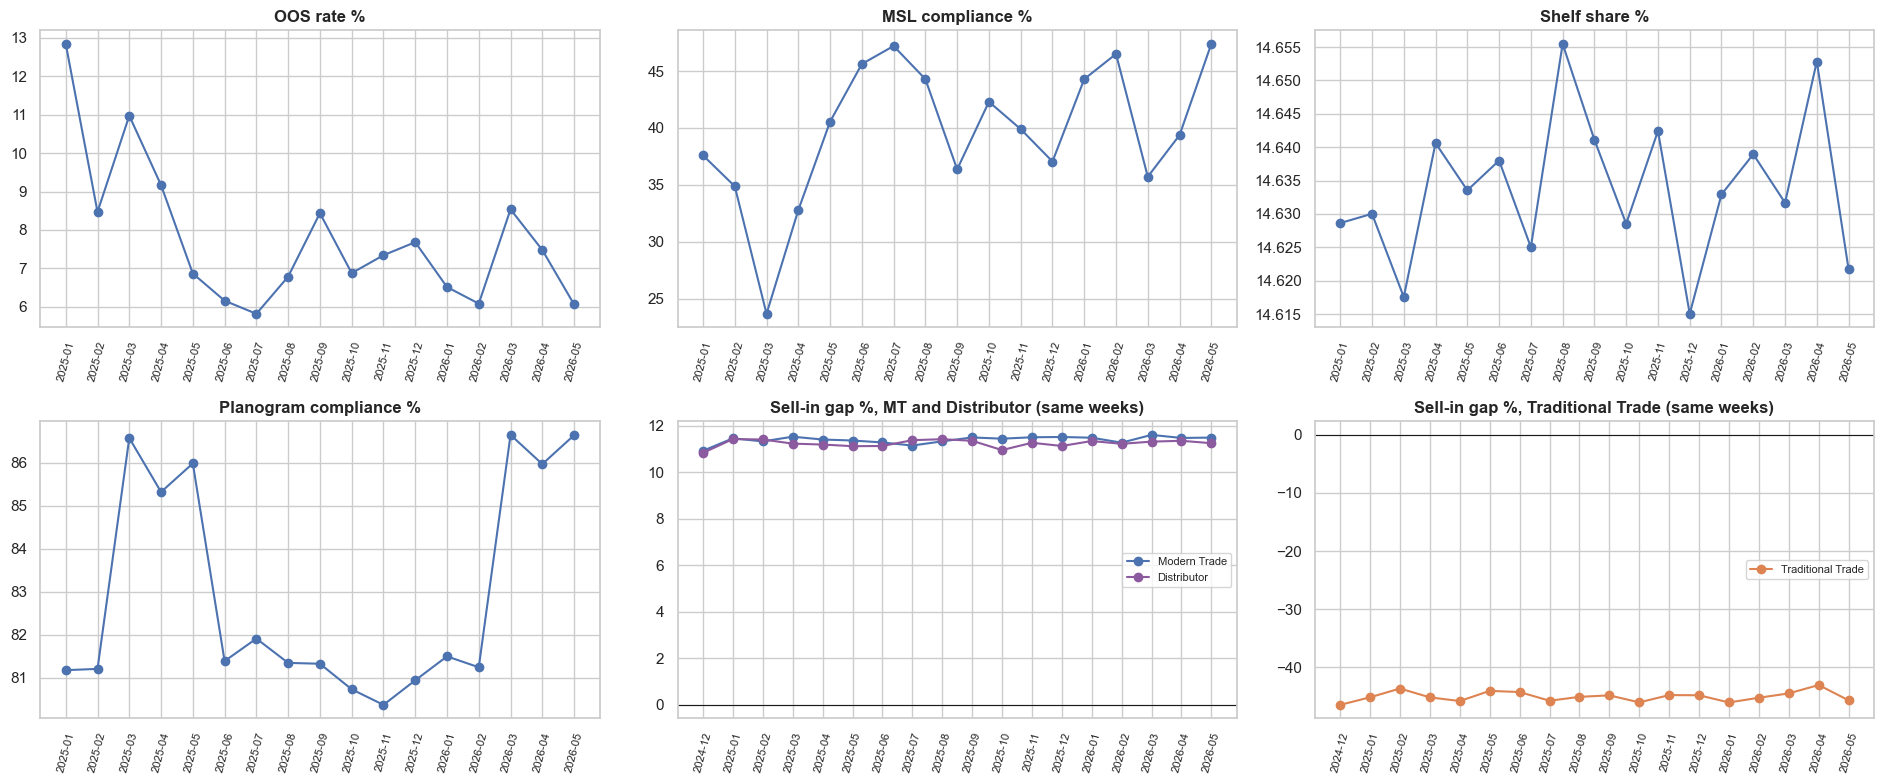

channel,Modern Trade,Traditional Trade,Distributor
mean,11.4,-45.0,11.3
min,10.9,-46.5,10.8
max,11.6,-43.1,11.4


In [37]:
month = lambda d: d.date.dt.to_period('M')
sof['week'] = sof.date - pd.to_timedelta(sof.date.dt.dayofweek, unit='D')     # the Monday that opens the sell-out week
wk_out = sof[sof.date <= GAP_END].groupby(['channel', 'week']).units_sold_daily.sum()
wk_in = si.assign(week=si.date - pd.Timedelta(days=7)).groupby(['channel', 'week']).units_sold.sum()   # an invoice describes the week before it
wk_both = pd.concat([wk_out.rename('sell_out'), wk_in.rename('sell_in')], axis=1).fillna(0).reset_index()
wk_both['month'] = wk_both.week.dt.to_period('M')
gap_m = wk_both.groupby(['month', 'channel'])[['sell_in', 'sell_out']].sum()
gap_m = (gap_m.sell_in / gap_m.sell_out - 1).unstack()[CH_ORDER] * 100

monthly = pd.DataFrame({
    'OOS rate %': sof.groupby(month(sof)).is_out_of_stock.mean() * 100,
    'MSL compliance %': msl_sd.groupby(month(msl_sd)).msl_compliant.mean() * 100,
    'Shelf share %': au.groupby(month(au)).shelf_share_pct.mean(),
    'Planogram compliance %': au.groupby(month(au)).planogram_compliance.mean() * 100}).dropna()

fig, axes = plt.subplots(2, 3, figsize=(19, 8))
for ax, col in zip(axes.flat, ['OOS rate %', 'MSL compliance %', 'Shelf share %', 'Planogram compliance %']):
    ax.plot(monthly.index.astype(str), monthly[col], marker='o', color='#4C72B0')
    ax.set_title(col); ax.tick_params(axis='x', rotation=75, labelsize=8)
for ax, chs, title in [(axes[1, 1], ['Modern Trade', 'Distributor'], 'Sell-in gap %, MT and Distributor (same weeks)'),
                       (axes[1, 2], ['Traditional Trade'], 'Sell-in gap %, Traditional Trade (same weeks)')]:
    for ch in chs:
        ax.plot(gap_m.index.astype(str), gap_m[ch], marker='o', color=CH_COL[ch], label=ch)
    ax.axhline(0, color='k', lw=0.8); ax.set_title(title); ax.tick_params(axis='x', rotation=75, labelsize=8); ax.legend(fontsize=8)
show('07_kpi_trends')
display(gap_m.describe().loc[['mean', 'min', 'max']].round(1))

**Notes**
1. OOS runs between 5.8% and 11.0% a month after the January 2025 peak (12.8%), and is higher in the first half of 2025 and in March and September of both years (see 6.5). **MSL compliance moves the opposite way**, between 24% (March 2025) and 47% (May 2026), because a store only passes when *every* must-stock SKU is in stock on the same day. Shelf share is flat (14.6%, by construction), and planogram has the same spring bump as in v1: ~86% in March–May, ~81% the rest of the year.
2. With both sides bucketed into the same weeks, the monthly sell-in gap is **stable**: Modern Trade +10.9% to +11.6%, Distributors +10.8% to +11.4%, Traditional Trade −46.5% to −43.1%. The v1 swings (−13% to +13%) really were the 5-Monday effect, and this fixes them.
3. But even with matched weeks, **Traditional Trade stays around −45%**. Q13 expected this gap to shrink once the windows match, and it doesn't. We dig into why in 8.3.
### 7.4 KPIs by region and channel

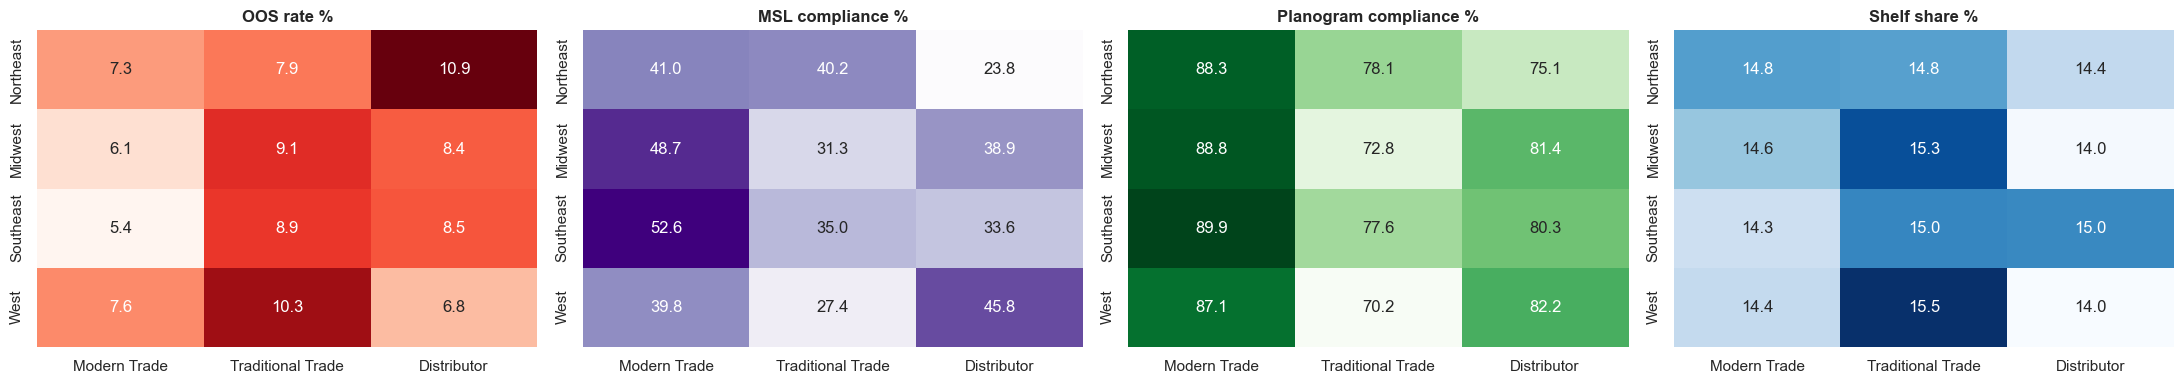

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for ax, (title, frame, col, mult, cmap) in zip(axes, [
        ('OOS rate %', sof, 'is_out_of_stock', 100, 'Reds'),
        ('MSL compliance %', msl_sd, 'msl_compliant', 100, 'Purples'),
        ('Planogram compliance %', au, 'planogram_compliance', 100, 'Greens'),
        ('Shelf share %', au, 'shelf_share_pct', 1, 'Blues')]):
    hm = frame.pivot_table(index='region', columns='channel', values=col, aggfunc='mean').reindex(REGION_ORDER)[CH_ORDER] * mult
    heatmap(hm, annot=True, fmt='.1f', cmap=cmap, ax=ax, cbar=False)
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('')
show('07_kpis_region_channel')

**Notes:** Region still makes little difference; the channel and the tier matter more. Traditional Trade is the weakest in most regions, especially in the **West** (OOS 10.3%, MSL compliance 27.4%, planogram 70.2%). One outlier: Distributors in the **Northeast** (OOS 10.9%, MSL compliance 23.8%). Modern Trade is consistently the best on planogram (87–90% everywhere).
### 7.5 Checking the client's numbers: the "62%" and Q7
In v1 we couldn't reproduce the brief's 62%. In Q7 Dr. Masse gave more detail: Traditional Trade Tier 3 is ~45% planogram-compliant, Traditional Trade Tier 2 ~65%, Modern Trade Tier 1 85–90%. The audits were updated, but now we know *which* numbers to look for:

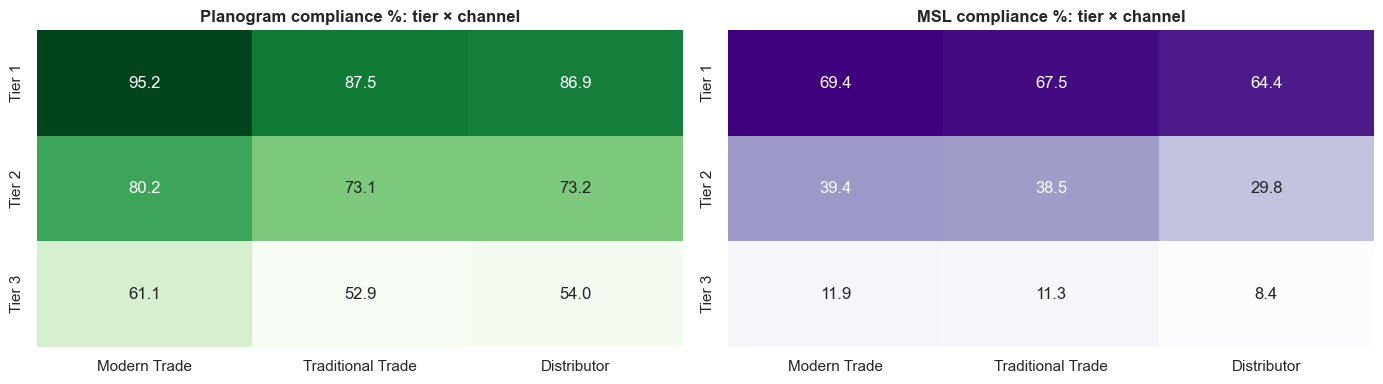

,client says (Q7),audits show
"Traditional Trade, Tier 3",~45%,52.9
"Traditional Trade, Tier 2",~65%,73.1
"Modern Trade, Tier 1",85–90%,95.2


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plano = au.pivot_table(index='segment_tier', columns='channel', values='planogram_compliance', aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER] * 100
heatmap(plano, annot=True, fmt='.1f', cmap='Greens', ax=axes[0], cbar=False); axes[0].set_title('Planogram compliance %: tier × channel'); axes[0].set_xlabel(''); axes[0].set_ylabel('')
msl_tc = msl_sd.pivot_table(index='segment_tier', columns='channel', values='msl_compliant', aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER] * 100
heatmap(msl_tc, annot=True, fmt='.1f', cmap='Purples', ax=axes[1], cbar=False); axes[1].set_title('MSL compliance %: tier × channel'); axes[1].set_xlabel(''); axes[1].set_ylabel('')
show('07_q7_check')
q7 = pd.DataFrame({'client says (Q7)': ['~45%', '~65%', '85–90%'],
                   'audits show': [plano.loc['Tier 3', 'Traditional Trade'], plano.loc['Tier 2', 'Traditional Trade'], plano.loc['Tier 1', 'Modern Trade']]},
                  index=['Traditional Trade, Tier 3', 'Traditional Trade, Tier 2', 'Modern Trade, Tier 1'])
q7.round(1)

**Notes:** The client's story is right in direction (Traditional Trade Tier 3 is the weakest, Modern Trade Tier 1 the strongest), but the audits show **higher** numbers than Q7 for all three groups: 52.9% vs ~45%, 73.1% vs ~65%, and 95.2% vs 85–90%. Planogram compliance is almost the same as before (83.0% vs 83.1% in v1), so the Q7 figures must come from somewhere else (maybe another definition, or the real business). We still can't reproduce the 62% either (overall planogram compliance is 83.0%, MSL compliance 39.7%).

The MSL heatmap is the most striking chart in this section: **in Tier 3 stores all the MSL SKUs are in stock on only 8–12% of days**, against 64–69% in Tier 1 and 30–39% in Tier 2, and the pattern is almost the same in every channel. That's where the field reps need to go first.

## 8. Deep dives

### 8.1 Out-of-stocks
OOS is still problem number one in the brief, and it's the table that changed the most.

Overall OOS rate: 7.78% of store-SKU-days   (v1: 5.98%)


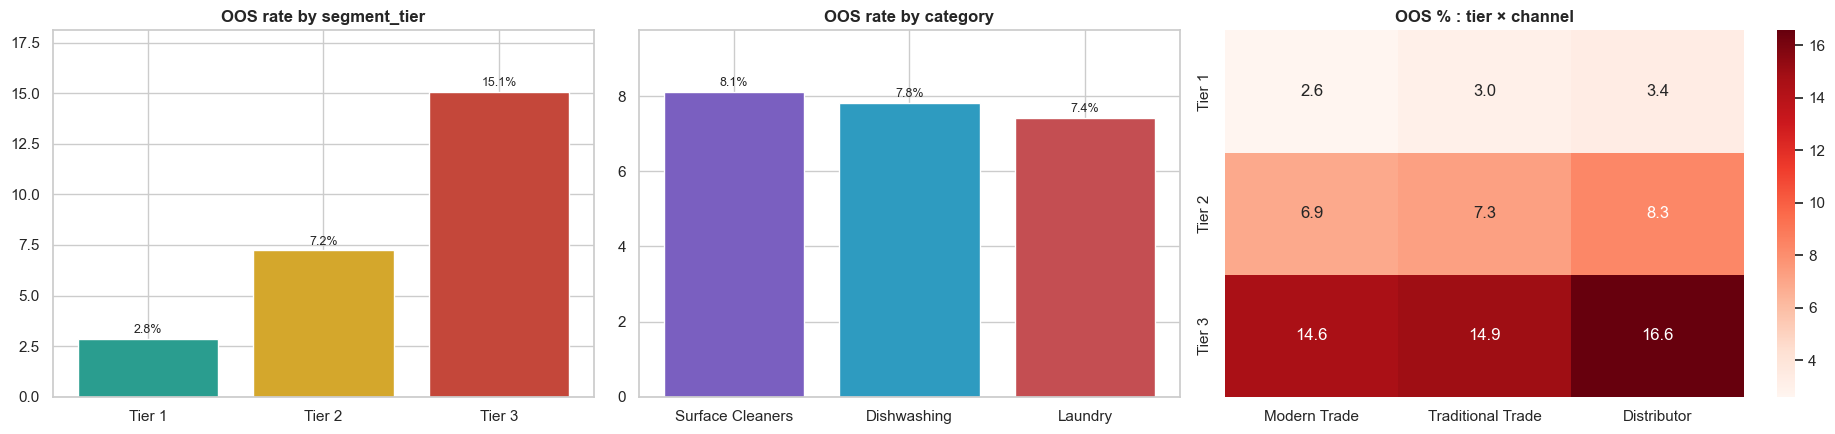

In [40]:
print(f"Overall OOS rate: {sof.is_out_of_stock.mean():.2%} of store-SKU-days   (v1: {v1['fact_sell_out'].is_out_of_stock.mean():.2%})")
fig, axes = plt.subplots(1, 3, figsize=(19, 4.5), gridspec_kw={'width_ratios': [1, 1, 1.2]})
for ax, col, order, pal in [(axes[0], 'segment_tier', TIER_ORDER, TIER_COL), (axes[1], 'category', CAT_ORDER, CAT_COL)]:
    r = sof.groupby(col).is_out_of_stock.mean().reindex(order) * 100
    ax.bar(r.index, r.values, color=[pal[x] for x in r.index]); label_bars(ax, '{:.1f}%')
    ax.set_title(f'OOS rate by {col}'); ax.set_ylim(0, r.max() * 1.2)
hm = sof.pivot_table(index='segment_tier', columns='channel', values='is_out_of_stock', aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER] * 100
heatmap(hm, annot=True, fmt='.1f', cmap='Reds', ax=axes[2]); axes[2].set_title('OOS % : tier × channel'); axes[2].set_xlabel(''); axes[2].set_ylabel('')
show('08_oos_by_dimension')

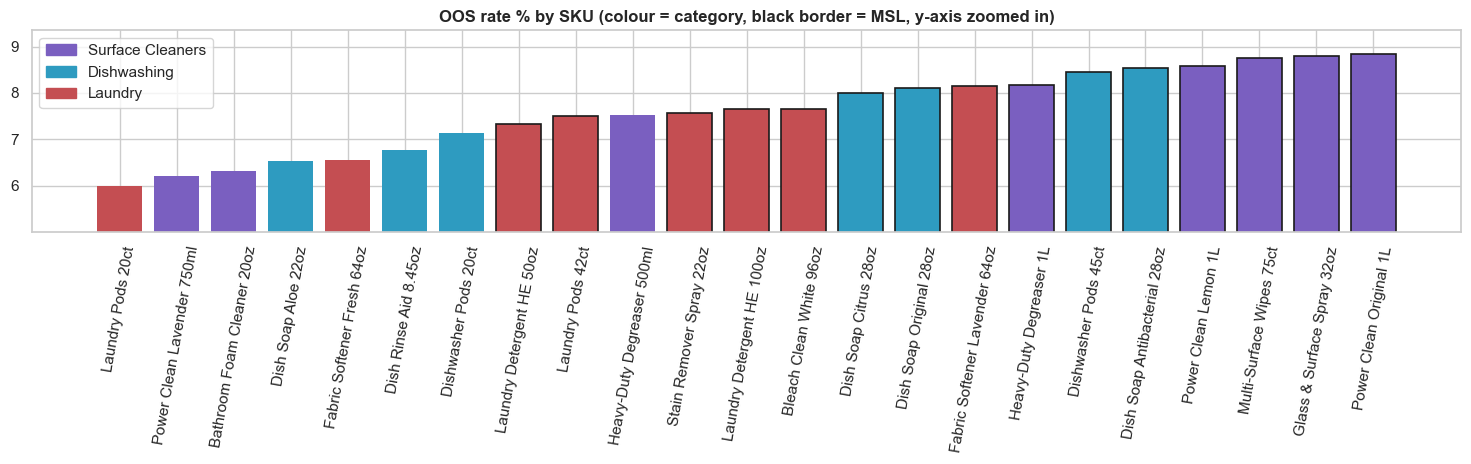

In [41]:
by_sku = (sof.groupby(['sku_id', 'product_name', 'category', 'is_msl']).is_out_of_stock.mean() * 100).reset_index().sort_values('is_out_of_stock')
fig, ax = plt.subplots(figsize=(15, 4.8))
ax.bar(by_sku.product_name.str.replace('Marvel ', ''), by_sku.is_out_of_stock, color=[CAT_COL[c] for c in by_sku.category],
       edgecolor=['k' if m else 'none' for m in by_sku.is_msl], linewidth=1.2)
ax.set_ylim(by_sku.is_out_of_stock.min() - 1, by_sku.is_out_of_stock.max() + 0.5); ax.tick_params(axis='x', rotation=80)
ax.set_title('OOS rate % by SKU (colour = category, black border = MSL, y-axis zoomed in)')
ax.legend(handles=[Patch(color=CAT_COL[c], label=c) for c in CAT_ORDER], loc='upper left')
show('08_oos_by_sku')

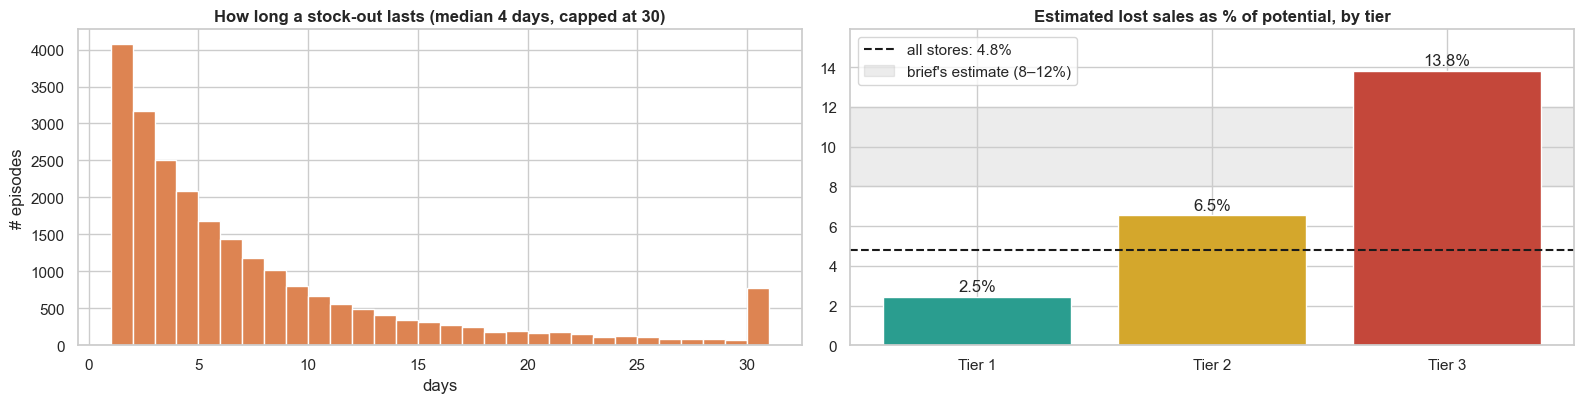

23,610 OOS episodes | 90% last 17 days or less | estimated lost sales $2,703,888 at list price


In [42]:
is_oos = so.is_out_of_stock
new_episode = is_oos & ~so.groupby(['store_id', 'sku_id']).is_out_of_stock.shift(fill_value=False)
so['episode'] = new_episode.groupby([so.store_id, so.sku_id]).cumsum()
ep = so[is_oos].groupby(['store_id', 'sku_id', 'episode']).date.agg(['min', 'max'])
ep_len = (ep['max'] - ep['min']).dt.days + 1

# rough lost sales (same method as v1): on OOS days, assume the store would have sold its normal in-stock daily average.
# valued at list price, like the brief's "units at risk × list price"
normal_daily = so[~so.is_out_of_stock].groupby(['store_id', 'sku_id']).units_sold_daily.mean().rename('normal_daily')
ls = sof[['store_id', 'sku_id', 'is_out_of_stock', 'units_sold_daily', 'list_price', 'segment_tier']].merge(normal_daily, on=['store_id', 'sku_id'])
ls['lost_value'] = np.where(ls.is_out_of_stock, (ls.normal_daily - ls.units_sold_daily).clip(lower=0), 0) * ls.list_price
ls['actual_value'] = ls.units_sold_daily * ls.list_price
lost_tier = ls.groupby('segment_tier')[['lost_value', 'actual_value']].sum().reindex(TIER_ORDER)
lost_pct = lost_tier.lost_value / (lost_tier.lost_value + lost_tier.actual_value) * 100
total_lost = ls.lost_value.sum() / (ls.lost_value.sum() + ls.actual_value.sum())

fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
axes[0].hist(ep_len.clip(upper=30), bins=range(1, 32), color='#DD8452')
axes[0].set_title(f'How long a stock-out lasts (median {ep_len.median():.0f} days, capped at 30)'); axes[0].set_xlabel('days'); axes[0].set_ylabel('# episodes')
bars = axes[1].bar(lost_pct.index, lost_pct.values, color=[TIER_COL[t] for t in lost_pct.index])
axes[1].bar_label(bars, labels=[f'{v:.1f}%' for v in lost_pct.values], padding=2)
axes[1].axhline(total_lost * 100, color='k', ls='--', label=f'all stores: {total_lost:.1%}')
axes[1].axhspan(8, 12, color='grey', alpha=0.15, label="brief's estimate (8–12%)", zorder=0)
axes[1].set_title('Estimated lost sales as % of potential, by tier'); axes[1].legend(loc='upper left'); axes[1].set_ylim(0, max(13, lost_pct.max() * 1.15))
show('08_oos_duration_lost_sales')
print(f"{len(ep_len):,} OOS episodes | 90% last {ep_len.quantile(.9):.0f} days or less | estimated lost sales ${ls.lost_value.sum():,.0f} at list price")
del ls; _ = gc.collect()

**What we found**
1. OOS is **7.78%** of store-SKU-days (v1: 5.98%). **Tier drives it:** Tier 1 is out of stock 2.9% of the time, Tier 2 7.2% and Tier 3 **15.1%**, and within a tier the channels are close (Tier 3: 14.6% Modern Trade, 14.9% Traditional Trade, 16.6% Distributors). By channel: 6.7% Modern Trade, 8.9% Traditional Trade, 8.3% Distributors.
2. Category barely matters, and the range by SKU is narrow (6.0% to 8.9%). MSL SKUs run out a bit more often than optional ones (8.1% vs 6.6%).
3. **Stock-outs last longer than in v1:** the median is **4 days** (3 in Tier 1, 4 in Tier 2, 6 in Tier 3), the mean 7.4 days, and 90% are over within 17 days (v1: about 3 and 10).
4. Lost sales with the same simple method as v1 come to **4.8% of potential** overall, about $2.7M at list price. By tier it's 2.5% for Tier 1, 6.5% for Tier 2 and **13.8% for Tier 3**. So the brief's "8–12%" is not a Marvel-wide number, but it describes the small stores well.

### 8.2 Stock and replenishment
Same example as v1 (STR-0001, a Modern Trade Tier 3 store, and Power Clean Lemon 1L), so the versions can be compared side by side. Each purple line starts on the day a delivery was **ordered** and ends with a triangle on the day it **arrived** according to `fact_deliveries`. With the new link, every arrival on a reported day should be a jump in the stock.

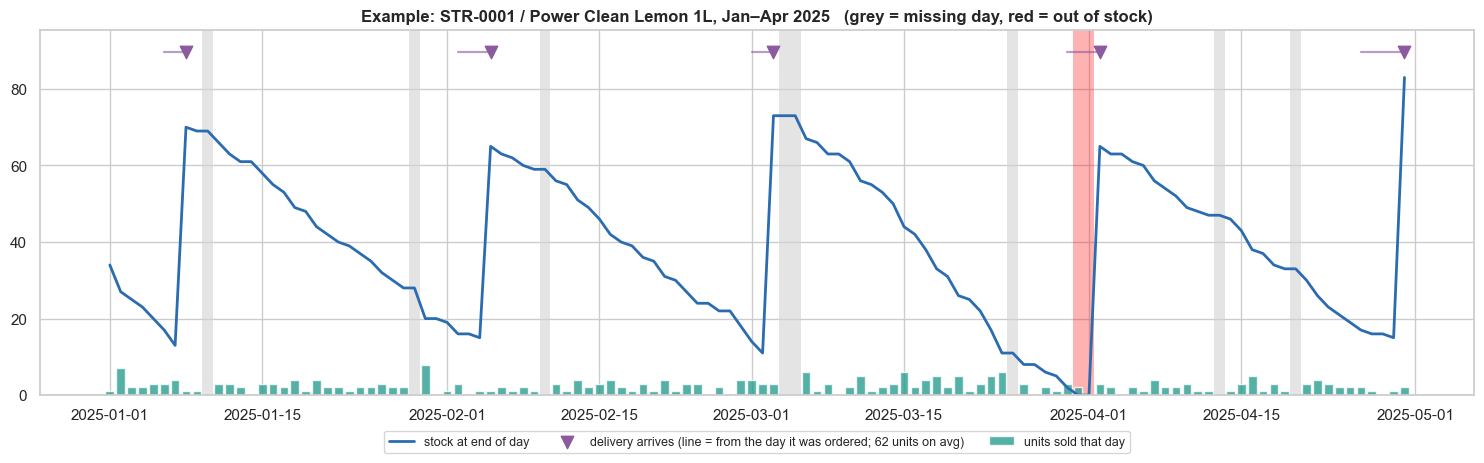

In [43]:
ex = so[(so.store_id == 'STR-0001') & (so.sku_id == 'SKU-1001') & (so.date < '2025-05-01')]
full = ex.set_index('date').reindex(pd.date_range('2025-01-01', '2025-04-30'))
d_ex = deliveries[(deliveries.store_id == 'STR-0001') & (deliveries.sku_id == 'SKU-1001') & (deliveries.actual_delivery <= '2025-04-30')]
half = pd.Timedelta(hours=12)
fig, ax = plt.subplots(figsize=(15, 4.8))
for d in full.index[full.inventory_level.isna()]:
    ax.axvspan(d - half, d + half, color='lightgrey', alpha=0.6, lw=0)
for d in ex.date[ex.is_out_of_stock]:
    ax.axvspan(d - half, d + half, color='red', alpha=0.3, lw=0)
ax.plot(full.index, full.inventory_level.ffill(), color='#2b6cb0', lw=2, label='stock at end of day')
ax.bar(ex.date, ex.units_sold_daily, color='#2A9D8F', alpha=0.8, label='units sold that day')
top = full.inventory_level.max() * 1.15
for _, r in d_ex.iterrows():
    ax.plot([r.order_date, r.actual_delivery], [top * 0.94] * 2, color='#8C5A9E', lw=1.6, alpha=0.6)
ax.scatter(d_ex.actual_delivery, np.full(len(d_ex), top * 0.94), marker='v', s=80, color='#8C5A9E', zorder=5,
           label=f'delivery arrives (line = from the day it was ordered; {d_ex.units_delivered.mean():.0f} units on avg)')
ax.set_title('Example: STR-0001 / Power Clean Lemon 1L, Jan–Apr 2025   (grey = missing day, red = out of stock)')
ax.set_ylim(0, top); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=9)
show('08_example_timeline')

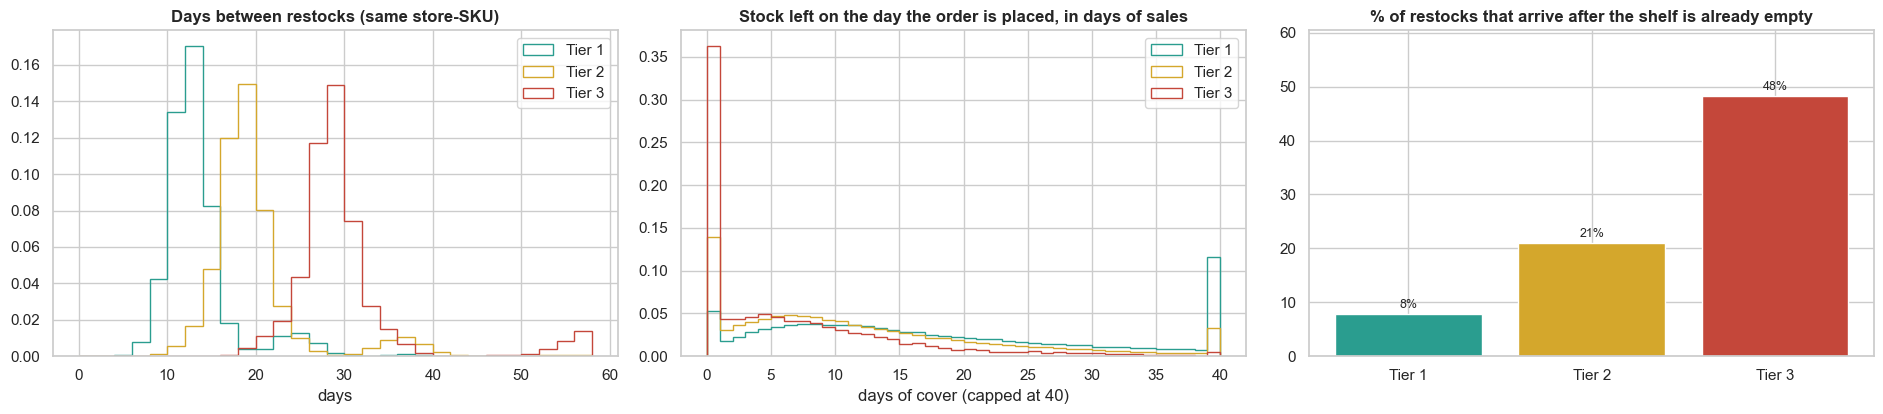

,restocks,median_days_between,median_cover_before,median_cover_after,avg_units_per_day,median_restock_units
tier,,,,,,
Tier 1,60484,12.0,12.4,24.9,9.3,114.0
Tier 2,43595,18.0,6.5,25.0,4.4,79.0
Tier 3,19544,28.0,0.7,31.3,1.7,46.0


,orders,median_cover_at_order,p25_cover_at_order,p75_cover_at_order,ordered_on_empty_shelf,days_of_sales_ordered
tier,,,,,,
Tier 1,66028,14.74,7.66,26.29,0.04,12.76
Tier 2,47473,9.53,4.08,17.24,0.11,18.65
Tier 3,21241,4.12,0.00,10.15,0.31,28.68


In [44]:
avg_u = so.groupby(['store_id', 'sku_id']).units_sold_daily.mean().rename('avg_units')
rf = refills.merge(avg_u, on=['store_id', 'sku_id']).sort_values(['store_id', 'sku_id', 'date'])
rf['tier'] = rf.store_id.map(stores.set_index('store_id').segment_tier)
rf['days_between'] = rf.groupby(['store_id', 'sku_id']).date.diff().dt.days
rf['cover_before'] = rf.prev_inv / rf.avg_units                      # stock left, in days of normal sales
rf['cover_after'] = (rf.prev_inv + rf.restock_units) / rf.avg_units
orders = (deliveries.merge(so[['store_id', 'sku_id', 'date', 'inventory_level']].rename(columns={'date': 'order_date', 'inventory_level': 'stock_on_order_date'}),
                           on=['store_id', 'sku_id', 'order_date'], how='left')
                    .merge(avg_u, on=['store_id', 'sku_id']))
orders['tier'] = orders.store_id.map(stores.set_index('store_id').segment_tier)
orders['cover_at_order'] = orders.stock_on_order_date / orders.avg_units       # days of stock left when the order was placed
orders['days_of_sales_ordered'] = orders.units_ordered / orders.avg_units         # how many days of normal sales the order covers

fig, axes = plt.subplots(1, 3, figsize=(19, 4.3))
for t in TIER_ORDER:
    axes[0].hist(rf.loc[rf.tier == t, 'days_between'].dropna(), bins=range(0, 60, 2), histtype='step', lw=2, color=TIER_COL[t], label=t, density=True)
    axes[1].hist(orders.loc[orders.tier == t, 'cover_at_order'].dropna().clip(upper=40), bins=np.arange(0, 41, 1), histtype='step', lw=2, color=TIER_COL[t], label=t, density=True)
axes[0].set_title('Days between restocks (same store-SKU)'); axes[0].set_xlabel('days'); axes[0].legend()
axes[1].set_title('Stock left on the day the order is placed, in days of sales'); axes[1].set_xlabel('days of cover (capped at 40)'); axes[1].legend()
empty = rf.groupby('tier').prev_inv.apply(lambda s: (s == 0).mean() * 100).reindex(TIER_ORDER)
axes[2].bar(empty.index, empty.values, color=[TIER_COL[t] for t in empty.index]); label_bars(axes[2], '{:.0f}%')
axes[2].set_title('% of restocks that arrive after the shelf is already empty'); axes[2].set_ylim(0, empty.max() * 1.25)
show('08_replenishment')
display(rf.groupby('tier').agg(restocks=('date', 'size'), median_days_between=('days_between', 'median'),
                               median_cover_before=('cover_before', 'median'), median_cover_after=('cover_after', 'median'),
                               avg_units_per_day=('avg_units', 'mean'), median_restock_units=('restock_units', 'median')).reindex(TIER_ORDER).round(1))
display(orders.groupby('tier').agg(orders=('delivery_id', 'size'), median_cover_at_order=('cover_at_order', 'median'),
                                   p25_cover_at_order=('cover_at_order', lambda s: s.quantile(.25)), p75_cover_at_order=('cover_at_order', lambda s: s.quantile(.75)),
                                   ordered_on_empty_shelf=('stock_on_order_date', lambda s: (s == 0).mean()),
                                   days_of_sales_ordered=('days_of_sales_ordered', 'median')).reindex(TIER_ORDER).round(2))

**What we found**
1. The example now makes sense: every triangle on a reported day is a jump in the stock, and the long red stock-outs are the waits between the empty shelf and the next arrival. (A triangle on a grey day is a delivery on a missing store-day; the stock doesn't show it, 3.8.)
2. **Restock cycles differ a lot by tier:** a store-SKU is restocked every **12 days in Tier 1, 18 in Tier 2 and 28 in Tier 3** (medians), and each order covers about **13, 19 and 29 days of normal sales**. After a restock the shelf holds about 25 days of sales in Tier 1 and 2 and 31 in Tier 3.
3. **Small stores order too late.** When the order is placed, the shelf still holds a median **14.7 days of sales in Tier 1, 9.5 in Tier 2 and only 4.1 in Tier 3**; 4%, 11% and **31%** of the orders are placed when the shelf is already empty. Add the 2–7 days of lead time (3.9) and the result is that **48% of Tier 3 restocks arrive after the shelf is already empty** (Tier 2: 21%, Tier 1: 8%).

This gives us a concrete story for Dr. Masse: the stock-outs are mostly a reorder-timing and order-size problem in the small stores, not a delivery problem (8.6).

### 8.3 Sell-in vs sell-out

Sell-in weekdays: {'Monday': 259286} | distinct invoice dates: 73 | first invoice 2025-01-06


,mean,min,50%,max
channel,,,,
Modern Trade,73.0,73.0,73.0,73.0
Traditional Trade,36.4,23.0,36.0,52.0
Distributor,73.0,73.0,73.0,73.0


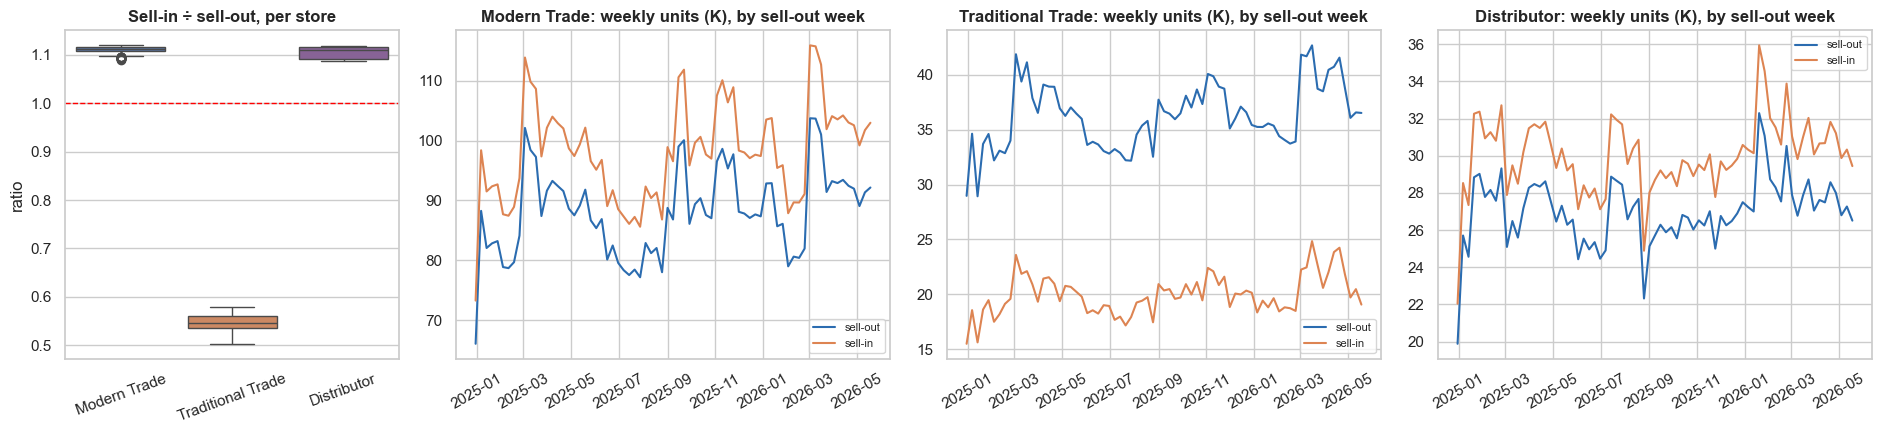

In [45]:
print('Sell-in weekdays:', sell_in.date.dt.day_name().value_counts().to_dict(), '| distinct invoice dates:', sell_in.date.nunique(),
      '| first invoice', sell_in.date.min().date())
weeks = si.groupby(['channel', 'store_id', 'sku_id']).date.nunique().rename('weeks_invoiced').reset_index()
display(weeks.groupby('channel').weeks_invoiced.describe()[['mean', 'min', '50%', 'max']].reindex(CH_ORDER).round(1))

store_ratio = ((si.groupby('store_id').units_sold.sum() / sof_gap.groupby('store_id').units_sold_daily.sum())
               .rename('ratio').reset_index().merge(stores[['store_id', 'channel']], on='store_id'))
fig = plt.figure(figsize=(19, 4.5))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1.3, 1.3, 1.3])
ax0 = fig.add_subplot(gs[0])
sns.boxplot(data=store_ratio, x='channel', y='ratio', order=CH_ORDER, hue='channel', palette=CH_COL, legend=False, ax=ax0)
ax0.axhline(1, color='red', ls='--', lw=1); ax0.set_title('Sell-in ÷ sell-out, per store'); ax0.set_xlabel(''); ax0.tick_params(axis='x', rotation=20)
for i, ch in enumerate(CH_ORDER):
    ax = fig.add_subplot(gs[i + 1])
    w = wk_both[wk_both.channel == ch].set_index('week').sort_index()
    ax.plot(w.index, w.sell_out / 1e3, label='sell-out', color='#2b6cb0'); ax.plot(w.index, w.sell_in / 1e3, label='sell-in', color='#DD8452')
    ax.set_title(f'{ch}: weekly units (K), by sell-out week'); ax.legend(fontsize=8); ax.tick_params(axis='x', rotation=30)
show('08_sellin_vs_sellout')

Two follow-ups. **First**, Q13 says the Traditional Trade gap should shrink once both sides use the same window, because one TT invoice covers two weeks. We computed the gap with 1-week, 2-week and monthly windows. **Second**, the change list says invoices no longer look ahead. On the first update each Monday invoice tracked the *next* 7 days of sell-out almost perfectly, which would leak the future into the OOS model. So we compared each invoice with the sell-out right before and right after it.

,corr with previous 14 days,corr with previous 7 days,corr with next 7 days,corr with next 14 days,invoice ÷ previous 7 days,invoice ÷ previous 14 days,invoice ÷ next 7 days
Modern Trade,0.955,0.997,0.831,0.850,1.114,0.557,1.113
Traditional Trade,0.950,0.997,0.812,0.834,1.105,0.553,1.102
Distributor,0.955,0.997,0.833,0.853,1.113,0.557,1.112


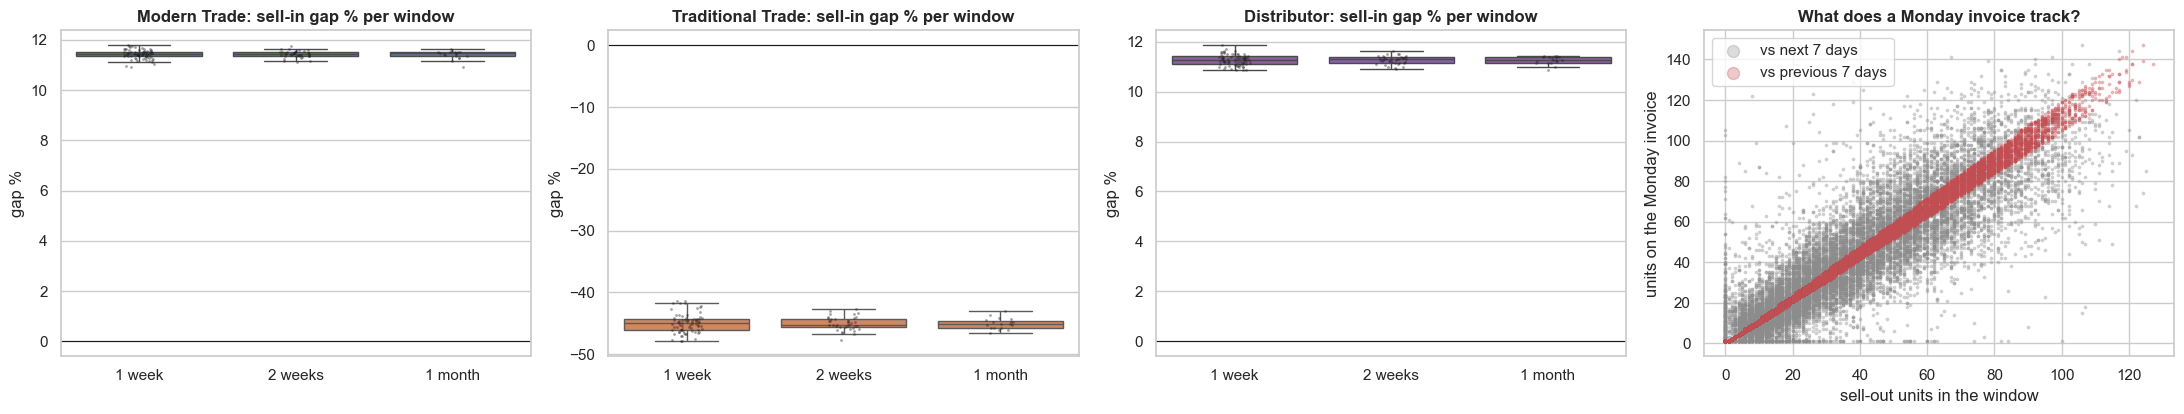

mean   min   max
channel           window                   
Modern Trade      1 month  11.4  10.9  11.6
                  1 week   11.4  10.9  11.8
                  2 weeks  11.4  11.1  11.7
Traditional Trade 1 month -45.0 -46.5 -43.1
                  1 week  -45.0 -47.9 -41.4
                  2 weeks -45.0 -47.8 -42.6
Distributor       1 month  11.3  10.8  11.4
                  1 week   11.3  10.8  11.9
                  2 weeks  11.3  10.9  11.6

In [46]:
wb = wk_both.copy()                                            # sell-in and sell-out per channel and sell-out week (from 7.3)
wb['two_weeks'] = (wb.week - wb.week.min()).dt.days // 14
win_gap = {}
for name, col in [('1 week', 'week'), ('2 weeks', 'two_weeks'), ('1 month', 'month')]:
    g2 = wb.groupby(['channel', col])[['sell_in', 'sell_out']].sum()
    win_gap[name] = ((g2.sell_in / g2.sell_out - 1) * 100).rename('gap').reset_index().assign(window=name)
win_gap = pd.concat(win_gap.values())

units_w = so.pivot(index=['store_id', 'sku_id'], columns='date', values='units_sold_daily').reindex(columns=all_days)
cs = np.hstack([np.zeros((len(units_w), 1)), units_w.fillna(0).to_numpy().cumsum(axis=1)])   # cs[:, j] = units sold before day j
row_of = pd.Series(np.arange(len(units_w)), index=units_w.index)
inv_ = si[(si.date >= all_days[0] + pd.Timedelta(days=14)) & (si.date <= all_days[-1] - pd.Timedelta(days=13))].copy()
r = row_of.reindex(pd.MultiIndex.from_frame(inv_[['store_id', 'sku_id']])).to_numpy()
c = (inv_.date - all_days[0]).dt.days.to_numpy()
WINDOWS = {'previous 14 days': (-14, 0), 'previous 7 days': (-7, 0), 'next 7 days': (0, 7), 'next 14 days': (0, 14)}
for name, (a, b) in WINDOWS.items():
    inv_[name] = cs[r, c + b] - cs[r, c + a]                    # sell-out on days [invoice + a, invoice + b)
track = pd.DataFrame({ch: {**{f'corr with {n}': np.corrcoef(d.units_sold, d[n])[0, 1] for n in WINDOWS},
                           'invoice ÷ previous 7 days': d.units_sold.sum() / d['previous 7 days'].sum(),
                           'invoice ÷ previous 14 days': d.units_sold.sum() / d['previous 14 days'].sum(),
                           'invoice ÷ next 7 days': d.units_sold.sum() / d['next 7 days'].sum()}
                      for ch, d in inv_.groupby('channel')}).T.reindex(CH_ORDER).round(3)
display(track)

fig, axes = plt.subplots(1, 4, figsize=(22, 4.3))
for ax, ch in zip(axes[:3], CH_ORDER):
    sub = win_gap[win_gap.channel == ch]
    sns.boxplot(data=sub, x='window', y='gap', ax=ax, color=CH_COL[ch], showfliers=False)
    sns.stripplot(data=sub, x='window', y='gap', ax=ax, color='k', size=2, alpha=0.4)
    ax.axhline(0, color='k', lw=0.8); ax.set_title(f'{ch}: sell-in gap % per window'); ax.set_xlabel(''); ax.set_ylabel('gap %')
smp = inv_.sample(15_000, random_state=0)
axes[3].scatter(smp['next 7 days'], smp.units_sold, s=3, alpha=0.3, color='#8C8C8C', label='vs next 7 days')
axes[3].scatter(smp['previous 7 days'], smp.units_sold, s=3, alpha=0.3, color='#C44E52', label='vs previous 7 days')
axes[3].set_xlabel('sell-out units in the window'); axes[3].set_ylabel('units on the Monday invoice')
axes[3].set_title('What does a Monday invoice track?'); axes[3].legend(markerscale=5)
show('08_sellin_windows_leak')
display(win_gap.groupby(['channel', 'window']).gap.agg(['mean', 'min', 'max']).round(1).reindex(CH_ORDER, level=0))

**What we found**
1. Same structure as v1: every invoice is on a **Monday**, and each one describes the week *before* it. Modern Trade and Distributors are invoiced every week (73 invoices in the window), Traditional Trade about every second week (36 on average, between 23 and 52).
2. The gap is still basically one number per channel: **+11% for MT and Distributors, −45% for Traditional Trade**, with a tiny spread between stores.
3. **Matching the windows doesn't close the Traditional Trade gap.** With 1-week, 2-week or monthly windows, TT stays at **about −45%** on average. If one invoice really covered two weeks of sales, the 2-week and monthly gaps would be close to 0.
4. The scatter shows why. **Each Monday invoice equals the previous 7 days of sell-out × ~1.11** (correlation 0.997 in every channel), and follows the next week much less (0.81–0.83): the **look-ahead is gone**. A Traditional Trade invoice also covers only the **one week before it**, so the week in between is never invoiced. That's exactly where −45% comes from (1.10 × ½ − 1 ≈ −0.45).
5. Because an invoice now only repeats the week that has already happened, its quantity is known on the Monday and **no longer leaks the future**. It can be used, but it adds nothing beyond the sell-out history we already have.

### 8.4 Discounts in sell-in
The discount is now two numbers: a **standard** discount that is fixed per channel × category, and an **extra** (negotiated) discount. `dim_guardrails` also has a cap, `max_discount_pct`, and the invoice has a `guardrail_violation` flag. We checked who gets how much extra discount, whether it follows order size (the first update said discounts were "volume-correlated"), and how the cap and the flag relate.

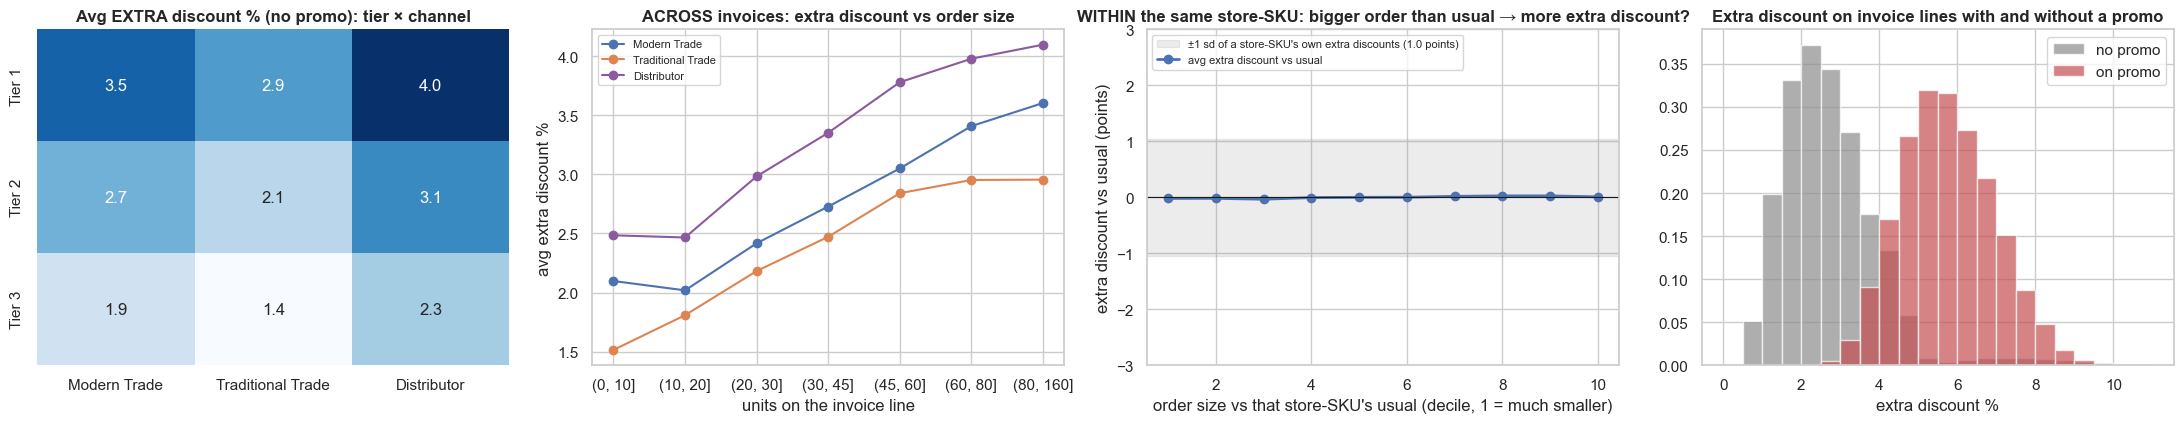

Standard discount, by channel × category, is a single value (it comes from dim_guardrails): True
Correlation, extra discount vs order size: across all non-promo invoices 0.47 | within the same store-SKU 0.01
Extra discount: 2.8% without a promo vs 5.7% on promo lines, while the promotions themselves advertise 11.5%
Promo invoices that reach the promo's min_volume_units: 33%
Invoice lines whose extra discount is above the cap (max_discount_pct): 17.3% | flagged guardrail_violation: 3.0% | flagged among the over-cap lines: 17.3% | flagged among the rest: 0.0%


In [47]:
g = si.merge(guardrails, on=['channel', 'category'])
g['over_cap'] = g.extra_discount_pct > g.max_discount_pct
g['log_units'] = np.log(g.units_sold)
npr = g[~g.on_promo].copy()
npr['units_vs_usual'] = npr.log_units - npr.groupby(k).log_units.transform('mean')
npr['extra_vs_usual'] = npr.extra_discount_pct - npr.groupby(k).extra_discount_pct.transform('mean')

fig, axes = plt.subplots(1, 4, figsize=(22, 4.4))
hm = npr.pivot_table(index='segment_tier', columns='channel', values='extra_discount_pct', aggfunc='mean').reindex(TIER_ORDER)[CH_ORDER]
heatmap(hm, annot=True, fmt='.1f', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Avg EXTRA discount % (no promo): tier × channel'); axes[0].set_xlabel(''); axes[0].set_ylabel('')
npr['units_bin'] = pd.cut(npr.units_sold, [0, 10, 20, 30, 45, 60, 80, 160])
b = npr.groupby(['units_bin', 'channel'], observed=True).extra_discount_pct.mean().unstack()[CH_ORDER]
for ch in CH_ORDER:
    axes[1].plot(b.index.astype(str), b[ch], marker='o', color=CH_COL[ch], label=ch)
axes[1].set_title('ACROSS invoices: extra discount vs order size'); axes[1].set_xlabel('units on the invoice line'); axes[1].set_ylabel('avg extra discount %'); axes[1].legend(fontsize=8)
w = npr.groupby(pd.qcut(npr.units_vs_usual, 10, labels=False)).extra_vs_usual.mean()
sdv = npr.extra_vs_usual.std()
axes[2].axhspan(-sdv, sdv, color='grey', alpha=0.15, label=f"±1 sd of a store-SKU's own extra discounts ({sdv:.1f} points)")
axes[2].plot(range(1, 11), w.values, marker='o', color='#4C72B0', lw=2, label='avg extra discount vs usual')
axes[2].axhline(0, color='k', lw=0.8); axes[2].set_ylim(-3, 3); axes[2].legend(fontsize=8, loc='upper left')
axes[2].set_title('WITHIN the same store-SKU: bigger order than usual → more extra discount?'); axes[2].set_xlabel("order size vs that store-SKU's usual (decile, 1 = much smaller)")
axes[2].set_ylabel('extra discount vs usual (points)')
for flag, col, lbl in [(False, '#8C8C8C', 'no promo'), (True, '#C44E52', 'on promo')]:
    axes[3].hist(g.loc[g.on_promo == flag, 'extra_discount_pct'], bins=np.arange(0, 11.5, 0.5), color=col, alpha=0.7, label=lbl, density=True)
axes[3].set_title('Extra discount on invoice lines with and without a promo'); axes[3].set_xlabel('extra discount %'); axes[3].legend()
show('08_discounts')
print('Standard discount, by channel × category, is a single value (it comes from dim_guardrails):', bool(g.groupby(['channel', 'category']).standard_discount_pct.nunique().eq(1).all()))
print('Correlation, extra discount vs order size: across all non-promo invoices', round(np.corrcoef(npr.extra_discount_pct, npr.units_sold)[0, 1], 3),
      '| within the same store-SKU', round(np.corrcoef(npr.extra_vs_usual, npr.units_vs_usual)[0, 1], 3))
pr_inv = g[g.on_promo].merge(promos[['promo_id', 'discount_pct', 'min_volume_units']].rename(columns={'discount_pct': 'promo_disc'}), on='promo_id')
print(f"Extra discount: {g[~g.on_promo].extra_discount_pct.mean():.1f}% without a promo vs {pr_inv.extra_discount_pct.mean():.1f}% on promo lines, "
      f"while the promotions themselves advertise {pr_inv.promo_disc.mean():.1f}%")
print(f"Promo invoices that reach the promo's min_volume_units: {(pr_inv.units_sold >= pr_inv.min_volume_units).mean():.0%}")
print(f"Invoice lines whose extra discount is above the cap (max_discount_pct): {g.over_cap.mean():.1%} | flagged guardrail_violation: {g.guardrail_violation.mean():.1%} | "
      f"flagged among the over-cap lines: {g.loc[g.over_cap, 'guardrail_violation'].mean():.1%} | flagged among the rest: {g.loc[~g.over_cap, 'guardrail_violation'].mean():.1%}")

**What we found**
1. Outside promos, the extra discount depends on **who the account is**: it steps down with tier in every channel (Modern Trade 3.5 → 2.7 → 1.9 points, Traditional Trade 2.9 → 2.1 → 1.4, Distributors 4.0 → 3.1 → 2.3). The standard part doesn't vary within a channel × category at all.
2. That's why the extra discount rises with order size across invoices (correlation **0.47**): big accounts place big orders *and* get more extra discount. But **within the same store-SKU**, a bigger order than usual doesn't get more discount (correlation **0.01**; the line stays flat inside the grey band of normal variation). So "volume-correlated" means a **volume tier per account**, not a volume discount per order.
3. Promo lines carry about **double the extra discount** (5.7% vs 2.8%), and their total discount is 14.1% vs 10.6%, while the promotions themselves advertise 11.5%. And only **33%** of promo invoice lines reach the promo's `min_volume_units`. So either the minimum isn't enforced, or it applies to something else (the whole order, or the whole promo period). Another question for Dr. Masse.
4. **17.3% of the lines have an extra discount above their cap**, but only **3.0%** are flagged `guardrail_violation`, and the flag has a pattern: it is never set on a line within its cap, almost never when the excess is under 1 point (0.1%), and then set on 19% of the lines 1–2 points over, 31% of 2–3 points over and 58% of lines 3 or more points over (8.8). It doesn't favour any tier or channel (about 3% everywhere).
### 8.5 Promotions and price elasticity
Scenario B of the simulator needs a price elasticity, and in Q14 Dr. Masse asked us to estimate it **from the data**. In v1 that was impossible (no prices in sell-out). Now sell-out has two kinds of price variation:
1. **Promotions:** the price drops by 7–15% for a few weeks.
2. **Everyday wiggle:** on non-promo days the price moves up to ±3% around the consumer price.

To measure the promo lift fairly, we compared each store-SKU with **itself in the same month**: average units on promo days vs non-promo days. Same month, so the seasonal step (6.3) cancels out. In-stock days only, because a shelf at zero can't show the extra demand.

,rows,discount_pct,lift_%,implied_elasticity
Bundle,52832,12.00,2.28,-0.18
Display,41785,8.71,11.34,-1.18
Feature,31690,8.52,13.08,-1.38
TPR,116716,10.36,14.89,-1.27
Volume,41332,14.00,19.87,-1.20
BOGO,16455,15.00,23.28,-1.29
Modern Trade,153604,10.67,12.15,-1.02
Traditional Trade,105874,10.24,10.98,-0.96
Distributor,41332,14.00,19.87,-1.20
All promos,300810,10.98,12.88,-1.04


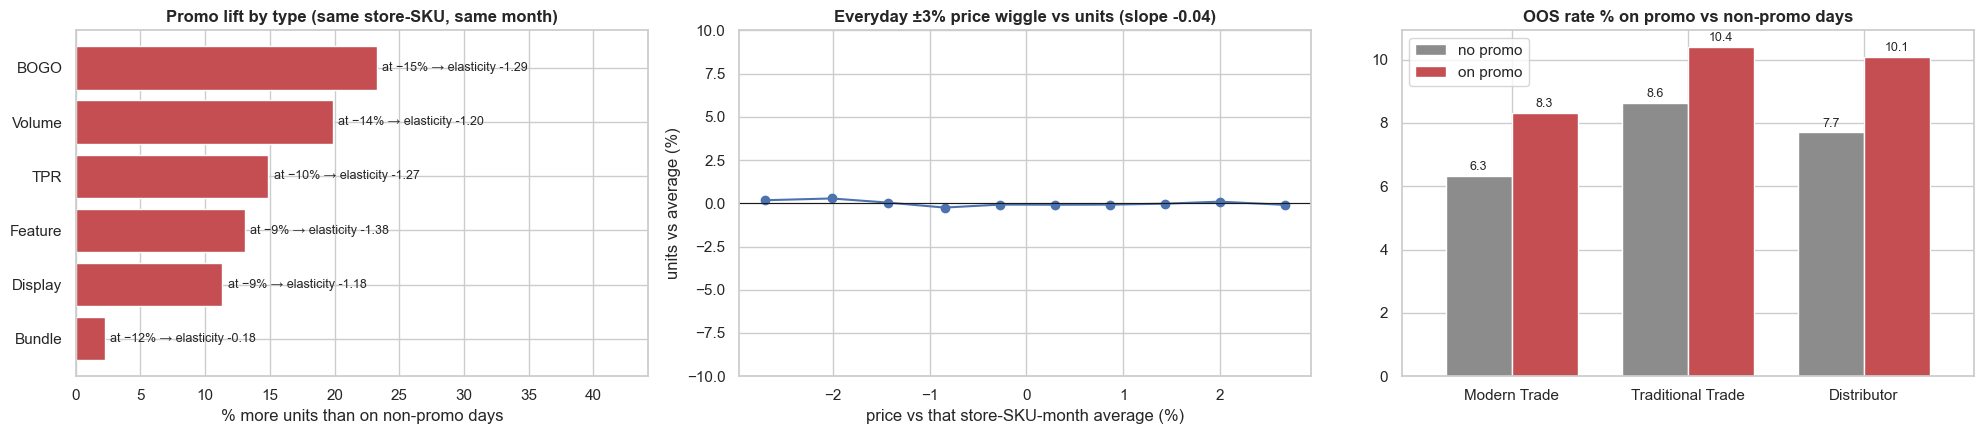

In [48]:
ins = sof.loc[~sof.is_out_of_stock, ['store_id', 'sku_id', 'date', 'channel', 'units_sold_daily', 'consumer_price_actual', 'promo_id', 'promo_discount_pct', 'on_promo']]
ins['ym'] = ins.date.dt.to_period('M')
kk = ['store_id', 'sku_id', 'ym']
base = ins[~ins.on_promo].groupby(kk).units_sold_daily.mean().rename('base_units')
pr_days = ins[ins.on_promo].merge(base, left_on=kk, right_index=True).merge(promos[['promo_id', 'promo_type']], on='promo_id')

def lift_table(by):
    t = pr_days.groupby(by).agg(promo_units=('units_sold_daily', 'sum'), base_units=('base_units', 'sum'), discount_pct=('promo_discount_pct', 'mean'), rows=('date', 'size'))
    t['lift_%'] = (t.promo_units / t.base_units - 1) * 100
    t['implied_elasticity'] = np.log(t.promo_units / t.base_units) / np.log(1 - t.discount_pct / 100)
    return t[['rows', 'discount_pct', 'lift_%', 'implied_elasticity']].round(2)
by_type, by_channel = lift_table('promo_type').sort_values('lift_%'), lift_table('channel').reindex(CH_ORDER)
all_promo = lift_table(np.repeat('All promos', len(pr_days)))
display(pd.concat([by_type, by_channel, all_promo]))

# everyday price wiggle: does a slightly higher price (same store-SKU, same month, no promo) mean fewer units?
npd = ins[~ins.on_promo]
lp = np.log(npd.consumer_price_actual)
price_dev = (lp - lp.groupby([npd.store_id, npd.sku_id, npd.ym]).transform('mean')) * 100
grp_mean = npd.groupby(kk).units_sold_daily.transform('mean')
units_dev = (npd.units_sold_daily / grp_mean.replace(0, np.nan) - 1) * 100
wig = units_dev.groupby(pd.qcut(price_dev, 10, labels=False)).mean()
wig_x = price_dev.groupby(pd.qcut(price_dev, 10, labels=False)).mean()
slope = np.polyfit(price_dev[units_dev.notna()], units_dev.dropna(), 1)[0]

oos_promo = sof.groupby(['channel', 'on_promo']).is_out_of_stock.mean().unstack().reindex(CH_ORDER) * 100

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
axes[0].barh(by_type.index, by_type['lift_%'], color='#C44E52')
for i, (t_, r_) in enumerate(by_type.iterrows()):
    axes[0].text(r_['lift_%'] + 0.4, i, f"at −{r_.discount_pct:.0f}% → elasticity {r_.implied_elasticity:.2f}", va='center', fontsize=9)
axes[0].set_xlim(0, by_type['lift_%'].max() * 1.9); axes[0].set_title('Promo lift by type (same store-SKU, same month)'); axes[0].set_xlabel('% more units than on non-promo days')
axes[1].plot(wig_x, wig, marker='o', color='#4C72B0'); axes[1].axhline(0, color='k', lw=0.8); axes[1].set_ylim(-10, 10)
axes[1].set_title(f'Everyday ±3% price wiggle vs units (slope {slope:.2f})'); axes[1].set_xlabel('price vs that store-SKU-month average (%)'); axes[1].set_ylabel('units vs average (%)')
oos_promo.plot.bar(ax=axes[2], color=['#8C8C8C', '#C44E52'], rot=0, width=0.75); label_bars(axes[2], '{:.1f}')
axes[2].legend(['no promo', 'on promo']); axes[2].set_title('OOS rate % on promo vs non-promo days'); axes[2].set_xlabel('')
show('08_promo_lift_elasticity')

**What we found**
1. **Promotions work.** On average a store-SKU sells **12.9% more** on promo days than on normal days in the same month, at an average discount of 11.0%. BOGO (+23%) and Volume deals (+20%) lift the most, then TPR (+15%), Feature (+13%) and Display (+11%); Bundles almost nothing (+2%).
2. Turned into an elasticity (% change in units ÷ % change in price), that's about **−1.0 overall** (−0.96 for Traditional Trade to −1.20 for Distributors) and **−1.2 to −1.4** for most promo types. TPR, the plain price cut, gives **−1.27**. Bundles are the exception at −0.2.
3. **The everyday ±3% wiggle does nothing**: the slope is −0.04, so units don't react. The wiggle is just noise on the price, and only promotions carry a real price signal.
4. OOS is higher on promo days in every channel (Modern Trade 8.3% vs 6.3%, Traditional Trade 10.4% vs 8.6%, Distributors 10.1% vs 7.7%), because demand goes up while the restock rhythm stays the same.

**For Scenario B**, this is what Q14 asked for: an elasticity that comes from the data. We'd use **about −1.0 to −1.3** from the promotions and show that range in the simulator, with two caveats stated clearly. These are temporary price *cuts*, while Scenario B is about price *increases*. And a promo lift can include shoppers stocking up, which a permanent price change wouldn't cause.

### 8.6 Delivery performance
`fact_deliveries` is now tied to the stock, so besides Marvel's own logistics (judged from the dates) we can finally ask whether late deliveries cause stock-outs: a late delivery means the shelf stays empty longer, so we count the stock-out days that fall between a late delivery's scheduled date and its actual date.

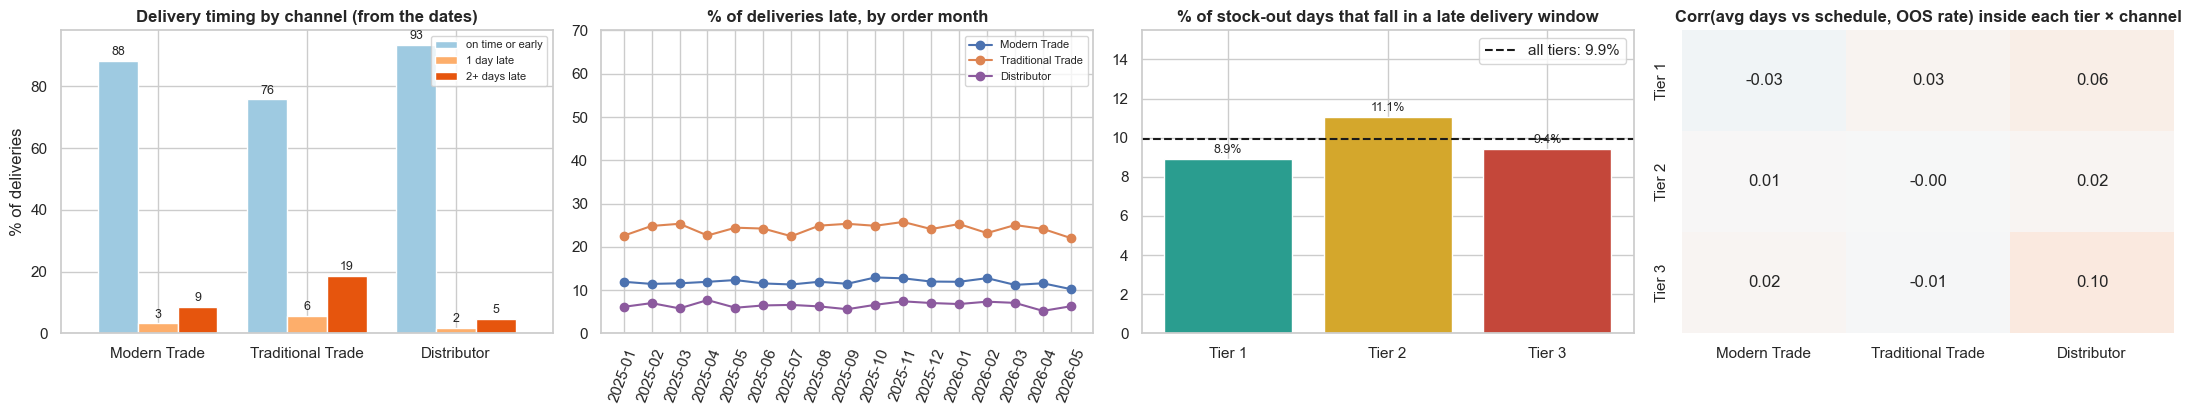

,scheduled_lead_days,actual_lead_days,avg_days_vs_schedule,late_share,short_shipped_pct,fill_rate_pct
channel,,,,,,
Modern Trade,3.00,2.95,-0.05,11.81,4.81,99.14
Traditional Trade,5.00,5.40,0.40,24.20,5.14,99.04
Distributor,2.01,1.79,-0.21,6.53,4.69,99.15


channel,Modern Trade,Traditional Trade,Distributor
segment_tier,,,
Tier 1,-0.12,0.18,-0.25
Tier 2,0.00,0.41,-0.18
Tier 3,0.11,0.69,-0.12


Stock-out days inside a late-delivery window: 16,032 of 161,243 (9.9%); late deliveries: 20,361 of 134,742 (15.1%)
Avg days vs schedule and OOS rate across ALL store-SKUs: corr 0.24 | inside each tier × channel: -0.03 to 0.10


In [49]:
dv['timing'] = np.select([dv.days_vs_schedule <= 0, dv.days_vs_schedule == 1], ['on time or early', '1 day late'], '2+ days late')
timing = pd.crosstab(dv.channel, dv.timing, normalize='index').reindex(CH_ORDER)[['on time or early', '1 day late', '2+ days late']] * 100
perf = dv.groupby('channel').agg(scheduled_lead_days=('lead_scheduled', 'mean'), actual_lead_days=('lead_actual', 'mean'),
                                 avg_days_vs_schedule=('days_vs_schedule', 'mean'), late_share=('days_vs_schedule', lambda s: (s > 0).mean() * 100),
                                 short_shipped_pct=('fill_rate_pct', lambda s: (s < 100).mean() * 100)).reindex(CH_ORDER)
perf['fill_rate_pct'] = dv.groupby('channel').units_delivered.sum() / dv.groupby('channel').units_ordered.sum() * 100

# stock-out days that fall between a late delivery's scheduled date and its actual date
late = deliveries.loc[deliveries.delay_days > 0, ['store_id', 'sku_id', 'scheduled_delivery', 'delay_days']]
rep = late.loc[late.index.repeat(late.delay_days)].copy()
rep['date'] = rep.scheduled_delivery + pd.to_timedelta(rep.groupby(level=0).cumcount(), unit='D')
oos_rows = so.loc[so.is_out_of_stock, ['store_id', 'sku_id', 'date']].copy()
oos_rows['tier'] = oos_rows.store_id.map(stores.set_index('store_id').segment_tier)
oos_rows['in_late_window'] = pd.MultiIndex.from_frame(oos_rows[['store_id', 'sku_id', 'date']]).isin(pd.MultiIndex.from_frame(rep[['store_id', 'sku_id', 'date']]))
share_late = oos_rows.groupby('tier').in_late_window.mean().reindex(TIER_ORDER) * 100

fig, axes = plt.subplots(1, 4, figsize=(22, 4.3))
timing.plot.bar(ax=axes[0], color=['#9ecae1', '#fdae6b', '#e6550d'], rot=0, width=0.8); label_bars(axes[0], '{:.0f}')
axes[0].set_title('Delivery timing by channel (from the dates)'); axes[0].set_ylabel('% of deliveries'); axes[0].set_xlabel(''); axes[0].legend(fontsize=8)
late_m = dv.groupby([dv.order_date.dt.to_period('M'), 'channel']).days_vs_schedule.apply(lambda s: (s > 0).mean() * 100).unstack()[CH_ORDER]
for ch in CH_ORDER:
    axes[1].plot(late_m.index.astype(str), late_m[ch], marker='o', color=CH_COL[ch], label=ch)
axes[1].set_title('% of deliveries late, by order month'); axes[1].tick_params(axis='x', rotation=70); axes[1].legend(fontsize=8); axes[1].set_ylim(0, 70)
axes[2].bar(share_late.index, share_late.values, color=[TIER_COL[t] for t in share_late.index]); label_bars(axes[2], '{:.1f}%')
axes[2].axhline(oos_rows.in_late_window.mean() * 100, color='k', ls='--', label=f'all tiers: {oos_rows.in_late_window.mean():.1%}'); axes[2].legend()
axes[2].set_title('% of stock-out days that fall in a late delivery window'); axes[2].set_ylim(0, share_late.max() * 1.4)
pc = pair.assign(channel=pair.store_id.map(ch_of))
cc = pc.groupby(['segment_tier', 'channel']).apply(lambda g_: g_.avg_days_late.corr(g_.oos_rate)).unstack().reindex(TIER_ORDER)[CH_ORDER]
heatmap(cc, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=axes[3], cbar=False)
axes[3].set_title('Corr(avg days vs schedule, OOS rate) inside each tier × channel'); axes[3].set_xlabel(''); axes[3].set_ylabel('')
show('08_delivery_performance')
display(perf.round(2))
display(pc.pivot_table(index='segment_tier', columns='channel', values='avg_days_late').reindex(TIER_ORDER)[CH_ORDER].round(2))
print(f"Stock-out days inside a late-delivery window: {oos_rows.in_late_window.sum():,} of {len(oos_rows):,} ({oos_rows.in_late_window.mean():.1%}); "
      f"late deliveries: {len(late):,} of {len(deliveries):,} ({len(late) / len(deliveries):.1%})")
print(f"Avg days vs schedule and OOS rate across ALL store-SKUs: corr {pair.avg_days_late.corr(pair.oos_rate):.2f} | "
      f"inside each tier × channel: {cc.min().min():.2f} to {cc.max().max():.2f}")
del rep, oos_rows

**What we found**
1. Planned lead times are short and fixed per channel (Distributors 2 days on average, Modern Trade 3, Traditional Trade 5), and almost every shipment arrives complete (fill rate ~99%, ~5% short in every channel). Against the schedule, **12% of Modern Trade deliveries, 24% of Traditional Trade and 7% of Distributor deliveries are late** (1–7 days), and the share doesn't trend over the 17 months.
2. **Late deliveries do prolong stock-outs, but they explain only about one stock-out day in ten:** 9.9% of the stock-out days fall between a late delivery's scheduled and actual date (8.9% in Tier 1, 11.1% in Tier 2, 9.4% in Tier 3). The share is probably a bit higher in reality, because we can only count days the store reported.
3. At store-SKU level, lateness correlates +0.24 with OOS, but **inside each tier × channel the link disappears** (between −0.03 and +0.10): Traditional Trade is later, and its small stores also run out more, which creates the overall correlation.

So the main driver of stock-outs is **when and how much the stores order** (8.2), not the delivery delays. The delivery table is still useful for a **logistics view** in the dashboard (on-time % by channel, fill rate from units).

### 8.7 Does better execution lead to more sales?
The change list says a real execution uplift is now built into daily sales (secondary display +8%, planogram compliance +5%, shelf share above the category median +3% per 10 percentage points). In v1 and in the first update the answer was "no". We re-ran our earlier test and, since the audits are visits on single days, we also tried the three most natural ways of linking an audit to daily sales: the latest audit before the day, the nearest audit (±45 days), and the audits of the same month. For each we estimated the effect on daily units of the same store-SKU (in-stock, non-promo days, weekday pattern removed).

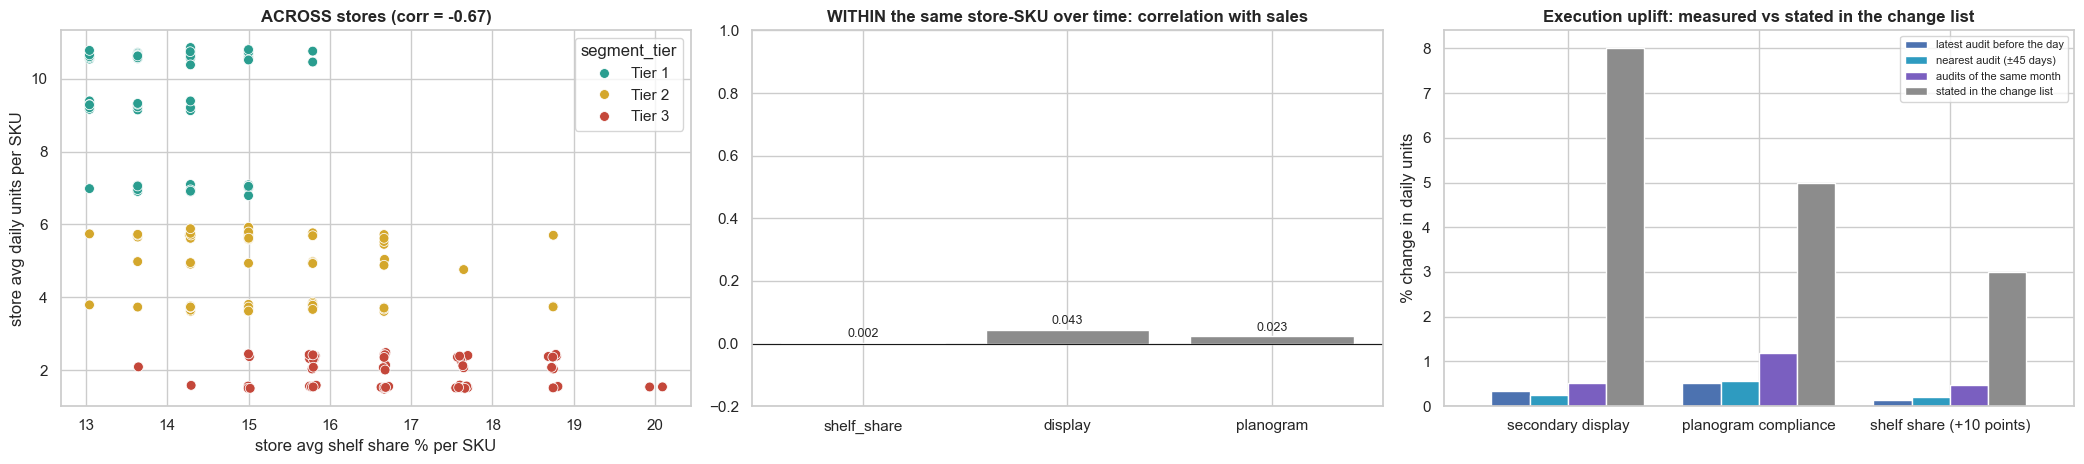

,latest audit before the day,nearest audit (±45 days),audits of the same month,stated in the change list
secondary display,0.34,0.24,0.53,8
planogram compliance,0.51,0.56,1.19,5
shelf share (+10 points),0.13,0.21,0.48,3


Same store-SKU, months WITH a display vs WITHOUT: +1.2% units (4,298 store-SKUs that had both)
Across store-SKUs in the same channel and tier, more displays vs fewer: +0.8% units on average


In [50]:
tmp = sof.loc[~sof.is_out_of_stock, ['store_id', 'sku_id', 'date', 'units_sold_daily']].assign(month=lambda d: d.date.dt.to_period('M'))
so_m = tmp.groupby(['store_id', 'sku_id', 'month']).units_sold_daily.mean().rename('units')
au_m = (audits.assign(month=audits.date.dt.to_period('M')).groupby(['store_id', 'sku_id', 'month'])
              .agg(shelf_share=('shelf_share_pct', 'mean'), display=('secondary_display', 'mean'), planogram=('planogram_compliance', 'mean')))
m = pd.concat([so_m, au_m], axis=1, join='inner').reset_index()
for c in ['units', 'shelf_share', 'display', 'planogram']:
    m[c + '_vs_usual'] = m[c] - m.groupby(['store_id', 'sku_id'])[c].transform('mean')
within = {c: np.corrcoef(m[c + '_vs_usual'], m['units_vs_usual'])[0, 1] for c in ['shelf_share', 'display', 'planogram']}
store_lvl = m.groupby('store_id')[['units', 'shelf_share']].mean().join(stores.set_index('store_id').segment_tier)

# the uplift, estimated the way the change list describes it
base_u = sof.loc[~sof.is_out_of_stock & ~sof.on_promo, ['store_id', 'sku_id', 'date', 'units_sold_daily']].copy()
base_u['rel'] = base_u.units_sold_daily / base_u.groupby(k).units_sold_daily.transform('mean')       # each store-SKU against its own average
base_u['rel'] = base_u.rel / base_u.groupby(base_u.date.dt.dayofweek).rel.transform('mean')           # weekday pattern removed
base_u = base_u.sort_values('date')
aud = audits.sort_values('date')[['date', 'store_id', 'sku_id', 'secondary_display', 'planogram_compliance', 'shelf_share_pct']].copy()
aud['sh10'] = (aud.shelf_share_pct - aud.groupby(aud.sku_id.map(cat_of)).shelf_share_pct.transform('median')) / 10   # per 10 points above the category median
FLAGS = {'secondary display': 'secondary_display', 'planogram compliance': 'planogram_compliance', 'shelf share (+10 points)': 'sh10'}
def effect(mapped):
    out = {}
    for name, col in FLAGS.items():
        x = mapped.dropna(subset=[col])
        f = x[col].astype(float)
        f_d = f - f.groupby([x.store_id, x.sku_id]).transform('mean')          # change in the flag within the same store-SKU
        out[name] = (f_d * (x.rel - 1)).sum() / (f_d ** 2).sum() * 100         # % change in units per unit of the flag
    return out
monthly_aud = (aud.assign(ym=aud.date.dt.to_period('M')).groupby(k + ['ym'])[list(FLAGS.values())].mean().reset_index())
mappings = {'latest audit before the day': lambda d: pd.merge_asof(d, aud, on='date', by=k, direction='backward'),
            'nearest audit (±45 days)': lambda d: pd.merge_asof(d, aud, on='date', by=k, direction='nearest', tolerance=pd.Timedelta(days=45)),
            'audits of the same month': lambda d: d.assign(ym=d.date.dt.to_period('M')).merge(monthly_aud, on=k + ['ym'])}
uplift = pd.DataFrame({n: effect(f(base_u)) for n, f in mappings.items()})
uplift['stated in the change list'] = [8, 5, 3]

fig, axes = plt.subplots(1, 3, figsize=(21, 4.8))
sns.scatterplot(data=store_lvl, x='shelf_share', y='units', hue='segment_tier', hue_order=TIER_ORDER, palette=TIER_COL, s=50, ax=axes[0])
axes[0].set_title(f"ACROSS stores (corr = {store_lvl[['shelf_share', 'units']].corr().iloc[0, 1]:.2f})")
axes[0].set_xlabel('store avg shelf share % per SKU'); axes[0].set_ylabel('store avg daily units per SKU')
axes[1].bar(list(within.keys()), list(within.values()), color='#8C8C8C'); label_bars(axes[1], '{:.3f}')
axes[1].set_ylim(-0.2, 1); axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_title('WITHIN the same store-SKU over time: correlation with sales')
uplift.plot.bar(ax=axes[2], rot=0, width=0.8, color=['#4C72B0', '#2E9BC0', '#7A5FC0', '#8C8C8C'])
axes[2].axhline(0, color='k', lw=0.8); axes[2].set_ylabel('% change in daily units'); axes[2].legend(fontsize=8)
axes[2].set_title('Execution uplift: measured vs stated in the change list')
show('08_execution_vs_sales')
display(uplift.round(2))

md = m.assign(has_display=m.display >= 0.5).groupby(['store_id', 'sku_id', 'has_display']).units.mean().unstack().dropna()
lift_same = md[True].sum() / md[False].sum() - 1
cell = pair.assign(channel=pair.store_id.map(ch_of))
cell['high_display'] = cell.sec_display > cell.groupby(['channel', 'segment_tier']).sec_display.transform('median')
across = cell.groupby(['channel', 'segment_tier', 'high_display']).avg_units.mean().unstack()
lift_across = (across[True] / across[False] - 1).mean()
print(f"Same store-SKU, months WITH a display vs WITHOUT: {lift_same:+.1%} units ({len(md):,} store-SKUs that had both)")
print(f"Across store-SKUs in the same channel and tier, more displays vs fewer: {lift_across:+.1%} units on average")
del tmp, base_u; _ = gc.collect()

**What we found**
1. Across stores, the shelf share per SKU and sales are now *negatively* linked (−0.67). That's an artefact of the normalisation (small stores audit fewer SKUs per category, so each SKU gets a bigger share, 4.8), not an effect of execution. Within the same store-SKU over time the correlations with sales are tiny: shelf share 0.002, display 0.043, planogram 0.023.
2. **We can't find the uplift the change list describes.** With each of the three ways of linking an audit to daily sales, the measured effect is **+0.2% to +0.5% for secondary display, +0.5% to +1.2% for planogram compliance and +0.1% to +0.5% per 10 points of shelf share**, against +8%, +5% and +3% stated. The simpler comparisons agree: months with a display sell +1.2% more than months without it for the same store-SKU, and store-SKUs with more displays than others of the same channel and tier sell +0.8% more.
3. So either the uplift is applied through a state that isn't what the audits record (for example a different day, or a store-level flag), or it is smaller than described. We need Dr. Masse to tell us how the uplift is tied to the audits. Until then, for Module 3 Scenario A the data-derived execution uplift is **about zero to one percent**, and any larger value would have to be a clearly labelled assumption.

### 8.8 Commercial guardrails
The margin formula is **net price = list price × (1 − discount)** and **gross margin = (net price − cost) ÷ net price** (Q5, Q16). `dim_guardrails` now has three discount numbers per channel × category: the **standard** discount, a **cap on the extra** discount (`max_discount_pct`), and the minimum margin. So the most a rep can give without approval is standard + cap, and we compare that with what the invoices actually show.

,channel,category,standard_discount_pct,max_discount_pct,min_target_margin,required_exec_tradeoff
0,Modern Trade,Surface Cleaners,9.64,5.03,22.01,Achieve 100% MSL compliance + planogram adherence
1,Modern Trade,Dishwashing,8.71,5.85,22.15,Achieve 100% MSL compliance + planogram adherence
2,Modern Trade,Laundry,8.28,4.05,25.70,Secure +10% shelf share or place 1 secondary d...
3,Traditional Trade,Surface Cleaners,2.30,3.15,28.61,Guarantee 100% MSL compliance + 1 secondary di...
4,Traditional Trade,Dishwashing,2.84,4.36,27.60,Secure +15% shelf share or place 1 secondary d...
5,Traditional Trade,Laundry,3.24,5.23,26.61,Secure +15% shelf share or place 1 secondary d...
6,Distributor,Surface Cleaners,11.44,5.65,22.06,Achieve 100% MSL compliance + planogram adherence
7,Distributor,Dishwashing,10.81,5.51,22.63,Secure +15% shelf share or place 1 secondary d...
8,Distributor,Laundry,11.31,6.99,19.06,Secure +10% shelf share or place 1 secondary d...


standard  extra_cap  avg_extra  avg_total  p95_total  share_over_cap  share_flagged  min_margin_rule  lowest_margin_on_any_invoice  \
channel           category                                                                                                                                               
Modern Trade      Dishwashing           8.71       5.85       3.40      12.11      15.73            0.10           0.03            22.15                         42.22   
                  Laundry               8.28       4.05       3.32      11.60      14.88            0.27           0.03            25.70                         41.24   
                  Surface Cleaners      9.64       5.03       3.43      13.07      16.53            0.16           0.03            22.01                         40.65   
Traditional Trade Dishwashing           2.84       4.36       2.74       5.58       8.99            0.19           0.03            27.60                         47.04   
                  Laundry               3.24       5.23       2.32       5.56       8.78            0.06           0.03            26.61                         44.13   
                  Surface Cleaners      2.30       3.15       2.53       4.83       8.00            0.25           0.03            28.61                         46.23   
Distributor       Dishwashing          10.81       5.51       4.02      14.83      18.36            0.20           0.03            22.63                         40.95   
                  Laundry              11.31       6.99       4.01      15.32      19.04            0.08           0.03            19.06                         37.06   
                  Surface Cleaners     11.44       5.65       4.00      15.44      18.99            0.19           0.03            22.06                         38.83   

                                    discount_that_breaks_margin  max_total_allowed  
channel           category                                                          
Modern Trade      Dishwashing                             39.55              14.56  
                  Laundry                                 34.17              12.33  
                  Surface Cleaners                        38.10              14.67  
Traditional Trade Dishwashing                             35.00               7.20  
                  Laundry                                 33.35               8.47  
                  Surface Cleaners                        32.38               5.45  
Distributor       Dishwashing                             39.18              16.32  
                  Laundry                                 39.57              18.30  
                  Surface Cleaners                        38.06              17.09

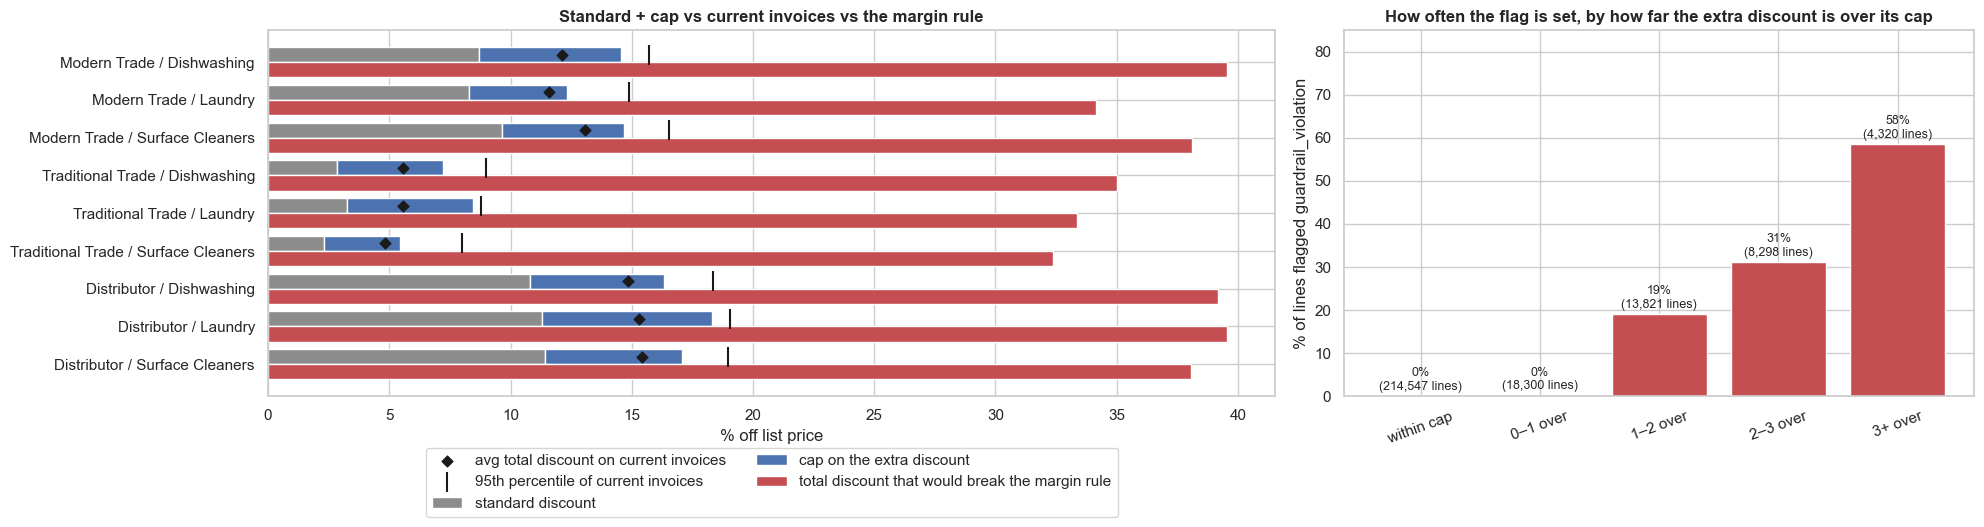

Invoice lines whose extra discount is over the cap: 17.3% | flagged guardrail_violation: 3.0% | invoices with margin below the minimum: 0
Flagged lines that are not over the cap: 0
required_exec_tradeoff
Achieve 100% MSL compliance + planogram adherence       3
Secure +15% shelf share or place 1 secondary display    3
Secure +10% shelf share or place 1 secondary display    2
Guarantee 100% MSL compliance + 1 secondary display     1
Name: count, dtype: int64


In [51]:
display(guardrails)
gm = products.merge(guardrails, on='category')
gm['discount_that_breaks_margin'] = (1 - gm.unit_cost / ((1 - gm.min_target_margin / 100) * gm.list_price)) * 100
g2 = si.merge(guardrails, on=['channel', 'category'])
g2['over_cap'] = g2.extra_discount_pct > g2.max_discount_pct
g2['excess'] = g2.extra_discount_pct - g2.max_discount_pct
g2['margin_pct'] = (g2.net_sales - g2.units_sold * g2.unit_cost) / g2.net_sales * 100
gsum = (g2.groupby(['channel', 'category'])
          .agg(standard=('standard_discount_pct', 'first'), extra_cap=('max_discount_pct', 'first'), avg_extra=('extra_discount_pct', 'mean'),
               avg_total=('discount_pct', 'mean'), p95_total=('discount_pct', lambda s: s.quantile(.95)),
               share_over_cap=('over_cap', 'mean'), share_flagged=('guardrail_violation', 'mean'),
               min_margin_rule=('min_target_margin', 'first'), lowest_margin_on_any_invoice=('margin_pct', 'min'))
          .join(gm.groupby(['channel', 'category']).discount_that_breaks_margin.min()).reindex(CH_ORDER, level=0))
gsum['max_total_allowed'] = gsum.standard + gsum.extra_cap
display(gsum.round(2))

plot_df = gsum.reset_index()
labels = plot_df.channel + ' / ' + plot_df.category
y = np.arange(len(plot_df))
fig, axes = plt.subplots(1, 2, figsize=(20, 5.5), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axes[0]
ax.barh(y - 0.2, plot_df.standard, height=0.4, color='#8C8C8C', label='standard discount')
ax.barh(y - 0.2, plot_df.extra_cap, left=plot_df.standard, height=0.4, color='#4C72B0', label='cap on the extra discount')
ax.barh(y + 0.2, plot_df.discount_that_breaks_margin, height=0.4, color='#C44E52', label='total discount that would break the margin rule')
ax.scatter(plot_df.avg_total, y - 0.2, color='k', marker='D', s=30, zorder=5, label='avg total discount on current invoices')
ax.scatter(plot_df.p95_total, y - 0.2, color='k', marker='|', s=200, zorder=5, label='95th percentile of current invoices')
ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlabel('% off list price'); ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title('Standard + cap vs current invoices vs the margin rule')
fl = g2.assign(bucket=pd.cut(g2.excess, [-20, 0, 1, 2, 3, 12], labels=['within cap', '0–1 over', '1–2 over', '2–3 over', '3+ over']))
fr = fl.groupby('bucket', observed=True).agg(flagged=('guardrail_violation', 'mean'), lines=('guardrail_violation', 'size'))
axes[1].bar(fr.index.astype(str), fr.flagged * 100, color='#C44E52')
for i, (f_, n_) in enumerate(zip(fr.flagged, fr.lines)):
    axes[1].text(i, f_ * 100 + 1.5, f'{f_:.0%}\n({n_:,} lines)', ha='center', fontsize=9)
axes[1].set_ylim(0, 85); axes[1].set_ylabel('% of lines flagged guardrail_violation'); axes[1].tick_params(axis='x', rotation=20)
axes[1].set_title('How often the flag is set, by how far the extra discount is over its cap')
show('08_guardrails')
print(f"Invoice lines whose extra discount is over the cap: {g2.over_cap.mean():.1%} | flagged guardrail_violation: {g2.guardrail_violation.mean():.1%} | "
      f"invoices with margin below the minimum: {(g2.margin_pct < g2.min_target_margin).sum():,}")
print(f"Flagged lines that are not over the cap: {(g2.guardrail_violation & ~g2.over_cap).sum():,}")
print(guardrails.required_exec_tradeoff.value_counts())

**What we found**
1. **How the rules work now.** The standard discount is fixed per channel × category (Traditional Trade 2.3–3.2%, Modern Trade 8.3–9.6%, Distributors 10.8–11.4%), `max_discount_pct` (3.2–7.0 points) is a **cap on the extra discount only**, so the most a rep can give without approval is standard + cap: **5.5% to 18.3%** of list price. The average invoice sits inside that limit in every cell, but the 95th percentile is above it in several (for example Modern Trade Laundry 14.9% vs 12.3%).
2. **17.3% of the lines are over their cap** (27% in Modern Trade Laundry, 25% in Traditional Trade Surface Cleaners, only 6% in Traditional Trade Laundry), but only 3.0% are flagged (8.4): the flag is set only on lines more than 1 point over, and even then on 19–58% of them. We can't derive the flag from the data, so we need its definition.
3. With the official margin formula (Q5, Q16), the margin rule still **never triggers**: the total discount that would break the minimum margin is **32–40%**, far above anything allowed (at most 18.3%) or seen on an invoice. The lowest margin on any invoice is 37.1%, above every minimum (19.1–28.6%).
4. The give-backs (`required_exec_tradeoff`) are now 4 different rules over the 9 channel × category cells (100% MSL + planogram, +10% shelf share or a display, +15% shelf share or a display, 100% MSL + a secondary display). With Q16 answered ("+15%" means percentage points, an endcap counts as `secondary_display`), we can turn them into automatic checks.

## 9. Key insights: what changed from v1, and what it means for our build

| # | v1 finding | Status in v3 | What it means for us |
|---|---|---|---|
| 1 | ~30% of store-days missing; sell-out stock frozen across them | **8.1%** missing, still random whole days; stock still frozen across them, but the 8.3% of deliveries that land on those days never reach the stock | Carry stock forward, treat gap-day sales as unknown; much smaller impact now |
| 2 | Data ends 30 Jun 2026 | Same (confirmed in Q18); no delivery after "today" any more | Treat 30 Jun as today |
| 3 | Tier drives sales, execution and OOS | **OOS is driven by tier** (2.9% / 7.2% / 15.1%), and the channels are now close within a tier | Tier is the main filter and the main model segment |
| 4 | Region barely matters | Same (state OOS just follows the tier mix) | A map is nice to have, not the story |
| 5 | Category seasonality; weekends +23% | Same seasonality (+22% weekends), plus promo spikes on top | Month + weekday + promo factors for the perfect order |
| 6 | MSL compliance ~40% | **39.7%** overall, but Tier 3 stores have every MSL SKU in stock only 8–12% of days vs 64–69% in Tier 1 | The rep view should put Tier 3 stores first |
| 7 | Monthly sell-in gap distorted by the number of Mondays | Fixed by bucketing both sides by sell-out week | Dashboard compares sell-in and sell-out by week (Q13) |
| 8 | Sell-in gap is one number per channel; invoices track the next week | Same gap (+11% / −45% / +11%); **invoices now track the previous week** (no look-ahead) | Invoice quantity can be used as history; TT gap still to confirm |
| 9 | No price signal | **Promotions give an elasticity of ≈ −1.0 to −1.3**; the everyday price wiggle is noise | Scenario B can use a data-derived elasticity (Q14) |
| 10 | Execution doesn't move sales | The change list says +8% / +5% / +3%; **we measure at most +1.2%** | Ask how the uplift is tied to the audits; Scenario A uplift is a labelled assumption until then |
| 11 | The margin guardrail never triggers | Same; the cap is now on the **extra** discount, 17.3% of lines are over it, 3.0% are flagged | Confirm the flag definition |
| 12 | Irregular deliveries cap OOS precision (the next restock is unknowable) | **Deliveries are now linked to restocks**; orders are known 2–7 days ahead (26–72% of the 7-day horizon) | Test the scheduled delivery date in the modelling notebook |
| 13 | *(first update)* Deliveries unrelated to the shelf; "Early" meant late | **Fixed:** deliveries are restock orders, and the labels agree with the dates | The logistics view can use the labels |
| 14 | *(new)* | **Small stores order too late:** Tier 3 orders at a median 4 days of stock (31% on an empty shelf), and 48% of its restocks arrive after the shelf is empty | The OOS story is reorder timing, not delivery delays (late deliveries explain only ~10% of stock-out days) |
| 15 | *(new)* | Shelf share is normalised: 14.6% per SKU = 100 ÷ SKUs audited | KPI definition to confirm |
| 16 | *(new)* | Sell-out regenerated again (14% of shared rows match v1); stock levels 2× higher | Rebuild every dashboard number on v3 |

## 10. Questions for Dr. Masse

1. **Execution uplift:** the change list says display +8%, planogram +5% and shelf share +3% per 10 points are built into daily sales. Linking the audits to sales in three different ways, we measure at most +1.2%. How is the uplift tied to the audits (which days, which state)?
2. **Guardrail flag:** 17.3% of invoice lines have an extra discount above `max_discount_pct`, but only 3.0% are flagged `guardrail_violation`: none within the cap, almost none under 1 point over, and then 19% to 58%. How is the flag defined?
3. **Deliveries on missing store-days:** 8.3% of deliveries land on days the store did not report and never appear as a restock. Is the stock meant to stay frozen on those days?
4. **Traditional Trade sell-in gap:** even with matched 2-week and monthly windows (Q13), the gap stays at −45%, because each biweekly invoice covers only the one week before it. Is that intended, and what should the KPI show?
5. **Shelf share:** it now sums to 100% within each category visit, so per SKU it is just 100 ÷ the number of SKUs and at category level it is always 100%. Is it meant to be a split among Marvel's SKUs or Marvel against competitors, and which one should the KPI use?
6. **Promo minimum volume:** only 33% of promo invoice lines reach `min_volume_units`. Is the minimum per invoice line, per order, or per promo period?
7. **Elasticity:** is an elasticity from the promotions (≈ −1.0 to −1.3) acceptable for the price *increases* in Scenario B?
8. **Q7 numbers:** the audits show higher planogram compliance than the Q7 figures (e.g. TT Tier 3 52.9% vs ~45%). Where do the Q7 numbers come from?
9. **Reorder behaviour:** Tier 3 stores place orders with a median of 4 days of stock left (31% on an empty shelf) and 48% of their restocks arrive after the shelf is empty. Is this reorder rule intended?
10. **OOS metrics by segment:** we know the targets are fixed (Q12). OOS now ranges from under 3% in Tier 1 to 15% in Tier 3, so one overall number hides very different situations. Can we report the metrics per segment alongside the overall number?
11. **Final data:** `guardrail_violation` and `extra_discount_pct` were not in the sell-in file we received on 10 October, although the note says they were. Is the 16 October data the final version, so we can rebuild the dashboard and the model on it?
12. **Guardrails table:** `dim_guardrails` in the 16 October update has a new column (`standard_discount_pct`) and different caps and minimum margins from the earlier file (for example Modern Trade Surface Cleaners: cap 12.8 → 5.03 on the extra discount, minimum margin 26.62 → 22.01). Which version is final? Sections 8.4 and 8.8 use the new one, and the shared V3 data platform keeps the earlier file.

## 11. Next steps

1. Send these questions to Dr. Masse, starting with the execution uplift and the guardrail flag.
2. Update the repo docs flagged for v3 review (data dictionary, KPI spec, bottlenecks) with the numbers from this notebook.
3. Rebuild the dashboard data (Module 1) on v3: official KPI definitions, Distributors shown separately, the sell-in gap by sell-out week, a promotions view, and a logistics view (on-time % from the dates, fill rate from units). Show the shelf-share KPI only after its definition is agreed.
4. Do the missing-data experiments and the OOS model in their own notebooks, on v3: train up to May 2026 and test on June 2026 (kept out of this EDA). Use the promo calendar and the **scheduled delivery date of orders already placed** as forward-looking inputs, add the reorder behaviour (cover at order time, days between restocks), and try segment-specific thresholds.
5. Module 3: elasticity from the promotions for Scenario B; for Scenario A, the standard discount, the cap on the extra discount and each account's usual extra discount (channel × tier) as the starting point, and the execution uplift only once its link to the audits is clear.